# End-to-end reproduction notebook

Running this notebook top to bottom runs the full pipeline and reproduces every reported figure and table; the outputs stored in it document a real, complete run. It is self-contained -- it defines every function inline instead of importing [`../src/`](../src/), and pins the GLCM raster subset rather than prompting for it, so it runs on a fresh clone with nothing but the dataset in place. See [`../README.md`](../README.md) for setup, the data layout, and how to execute it from a terminal.

**The same pipeline, organised as an importable library, lives under [`../src/`](../src/)** -- every function/class defined in the cells below has been extracted, organised by pipeline stage, and documented there:

| Notebook section | Module |
|---|---|
| 1-1a. Configuration | `src/config.py` |
| 1.5. Raster/vector preprocessing | `src/features/raster_preprocessing.py` |
| 2. Helper functions | `src/features/sampling.py` |
| 3a, 3f. Sampling, negative selection | `src/features/sampling.py` |
| 3b-3d. Proximity + raster sampling | `src/features/proximity.py` |
| 3e. Terrane attributes | `src/features/terrane.py` |
| 3g. GLCM texture features | `src/features/glcm.py` |
| 3h. A∧B sampleable domain | `src/features/sampleable_domain.py` |
| 4. Build region feature table | `src/features/build_region.py` |
| 5. Feature matrix | `src/features/feature_matrix.py` |
| 5a. Collinearity pruning | `src/features/collinearity.py` |
| 6. Evaluation protocol (pooled OOF, repeated CV) | `src/evaluation/cv_protocol.py` |
| 7. Random Forest | `src/models/random_forest.py` |
| 8. DevNet | `src/models/devnet.py` |
| 9-10. Run evaluation + production fit | `src/evaluation/run_experiment.py` |
| 11. Comparison table | `src/evaluation/comparison_table.py` |
| 11b. DN_MARGIN ablation | `src/evaluation/ablation_margin.py` |
| 11c. Background-sampling ablation | `src/evaluation/ablation_background_sampling.py` |
| 11e. Positive-count ablation | `src/evaluation/ablation_positive_count.py` |
| 12. Prediction map | `src/evaluation/prediction_map.py` |
| 12b. Capture-rate curve/table | `src/evaluation/capture_rate.py` |
| 13a-13c, 13e. SHAP explainers, global importance | `src/interpretation/shap_explainers.py`, `src/interpretation/shap_pipeline.py`, `src/interpretation/global_importance.py` |
| 13d. SHAP summary plots | `src/interpretation/summary_plots.py` |
| 13e-2. geo_era SHAP importance | `src/interpretation/era_importance.py` |
| 13f. Local explanation (waterfall) | `src/interpretation/local_explanation.py` |
| 13g. Single-feature ablation | `src/evaluation/ablation_single_feature.py` |
| 14a-14e. Label-confidence stratification | `src/evaluation/label_confidence_stratification.py` |
| 15. GIS export | `src/evaluation/gis_export.py` |

See [`../README.md`](../README.md) for data setup and the run order.


## 1. Configuration

In [1]:
import os, warnings, fnmatch
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from scipy.spatial import cKDTree
from scipy.interpolate import griddata
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.metrics import roc_auc_score, classification_report
from skimage.feature import graycomatrix, graycoprops
import torch
import torch.nn as nn
import torch.optim as optim
import rasterio
from rasterio.mask import mask as rio_mask
import pyproj

BASE = '../../dataset'

# ── Data discovery (replaces the old hand-listed _RASTERS dict + per-region
# faults/margins/worms entries) ──────────────────────────────────────────────────
# Feature layers are now discovered by scanning folders instead of being
# named one-by-one: a discovered file's KEY is its own filename (extension
# stripped, spaces/hyphens -> underscores), so e.g. 'Canada_BA.flt' becomes
# the key 'Canada_BA' -- this is what src/features/data_discovery.py's
# discover_layers() does; reproduced inline here since this notebook is a
# self-contained reference copy (see header cell) that doesn't import src.
#
# The five roots below are exactly the ones data/README.md documents and
# src/config.py defaults to -- rasters/, vectors/, points/, outlines/ and
# h3_grid/ under BASE -- so this notebook and src/ read the same dataset in
# the same way. Each scan recurses (and follows symlinked subfolders), so a
# root organised into subfolders by data provider works unchanged.
_RASTER_EXT = ('.tif', '.flt')
_VECTOR_EXT = ('.geojson', '.shp')
_POINT_EXT  = ('.geojson', '.shp')


def _discover_key(path):
    return os.path.splitext(os.path.basename(path))[0].replace(' ', '_').replace('-', '_')


def _discover_layers(directory, extensions):
    """Recursively scan `directory` for files ending in `extensions`,
    return {key: path}. Raises on a filename collision (two files mapping
    to the same key) rather than silently dropping one."""
    layers = {}
    for root, _dirs, files in os.walk(directory, followlinks=True):
        for fname in sorted(files):
            if not fname.lower().endswith(extensions):
                continue
            key = _discover_key(fname)
            path = os.path.join(root, fname)
            if key in layers:
                raise ValueError(f'Two files under {directory!r} both map to key {key!r}: '
                                  f'{layers[key]!r} and {path!r} -- rename one.')
            layers[key] = path
    return dict(sorted(layers.items()))


_rasters = _discover_layers(f'{BASE}/rasters', _RASTER_EXT)
_vectors = _discover_layers(f'{BASE}/vectors', _VECTOR_EXT)
_points  = _discover_layers(f'{BASE}/points',  _POINT_EXT)

print(f'Discovered {len(_rasters)} raster, {len(_vectors)} vector, {len(_points)} point layer(s):')
print('  rasters:', sorted(_rasters))
print('  vectors:', sorted(_vectors))
print('  points: ', sorted(_points))

# GLCM raster selection is pinned here rather than asked interactively (see
# src/features/data_discovery.py's choose_glcm_rasters for the interactive
# version, meant for a first-time setup): this reference notebook exists to
# reproduce a specific past run's stored results exactly, and an interactive
# terminal prompt would make that non-deterministic across re-executions.
# These 4 keys are the SAME 4 underlying files (by content) this project's
# results were always produced from -- 'gravity_ba'/'mag_tmi'/'mag_drtp'/
# 'gravity_ba_hp40km' were this codebase's old hand-chosen short names for
# Canada_BA.flt / TMI.flt / DRTP.flt / Canada_BA_HP40km.flt; under
# filename-derived keys they're named after those same files instead. The
# feature VALUES are therefore bit-identical to every prior run -- only the
# feature-column names change (e.g. 'gravity_ba_glcm_contrast' is now
# 'Canada_BA_glcm_contrast'), so SHAP/importance tables downstream will show
# these new names.
GLCM_RASTERS = ['Canada_BA', 'Canada_BA_HP40km', 'DRTP', 'TMI']
assert set(GLCM_RASTERS) <= set(_rasters), \
    f'expected GLCM_RASTERS {GLCM_RASTERS} to all be present in discovered rasters {sorted(_rasters)}'
print(f'\nGLCM_RASTERS (pinned, not re-chosen interactively): {GLCM_RASTERS}')

# ── Region discovery (replaces the old hand-listed REGIONS dict literal) ───
# Each outline file IS a region -- its discovered key becomes the region
# name -- matched to the single shared H3 grid file and to its own deposit
# CSV by filename PREFIX. Mirrors src.features.data_discovery.discover_regions()
# inline (see that function's docstring for the exact matching rules); add
# a new outline file under outlines/ and a matching deposit CSV, and a new
# region appears here with no code change.
_DEPOSITS_ROOT = '..'  # code/ root -- keep it to the 3 deposit CSVs only:
                       # the match below is by filename PREFIX, so any other
                       # Cordillera*/Superior*/Grenville*-prefixed CSV sitting
                       # here would make it ambiguous. The CSVs this notebook
                       # WRITES go to its own directory (notebooks/), not here.

_outlines = _discover_layers(f'{BASE}/outlines', ('.geojson', '.shp'))
_h3_grid_matches = _discover_layers(f'{BASE}/h3_grid', ('.geojson', '.shp', '.gpkg'))
assert len(_h3_grid_matches) == 1, (
    f'expected exactly one H3 terrane-grid file, found {list(_h3_grid_matches)}')
_h3_grid_path = next(iter(_h3_grid_matches.values()))

# CSVs the pipeline itself writes ('*_features_semisup*.csv',
# '*_top*_potential_targets*.csv') also start with a region name, so skip
# them here -- same guard as src.features.data_discovery's
# PIPELINE_OUTPUT_CSV_PATTERNS, which keeps a re-run from finding two
# 'matches' for a region.
_dep_files = [f for f in sorted(os.listdir(_DEPOSITS_ROOT))
               if f.lower().endswith('.csv')
               and not fnmatch.fnmatch(f, '*_features_semisup*.csv')
               and not fnmatch.fnmatch(f, '*_top*_potential_targets*.csv')]

REGIONS = {}
for _region_name, _outline_path in _outlines.items():
    _dep_matches = [f for f in _dep_files if f.startswith(_region_name)]
    assert len(_dep_matches) == 1, (
        f"expected exactly one deposit CSV starting with {_region_name!r} in "
        f'{_DEPOSITS_ROOT!r}, found {_dep_matches}')
    REGIONS[_region_name] = {
        'outline': _outline_path,
        'h3_grid': _h3_grid_path,
        'dep':     os.path.join(_DEPOSITS_ROOT, _dep_matches[0]),
        'vectors': _vectors,
        'points':  _points,
        'raster':  _rasters,
    }
print(f'\nDiscovered {len(REGIONS)} region(s): {sorted(REGIONS)}')

PROJECTED_CRS  = 'EPSG:3978'  # Canada Atlas Lambert (metres)
BUFFER_KM      = 10.0         # min distance from any REE deposit → negative sample
N_BACKGROUND   = 4000          # max negative samples per region
GRID_DEG       = 0.1          # ~10 km grid spacing for negative sampling & prediction
RANDOM_SEED    = 42
DN_SEED        = 42
DN_EPOCHS      = 300
DN_BATCH       = 32
DN_RESTARTS    = 5      # per-fold restarts averaged to reduce init variance
DN_MARGIN      = 5.0   # deviation margin; 8.0 is too demanding for few positives


Discovered 17 raster, 2 vector, 4 point layer(s):
  rasters: ['Canada_BA', 'Canada_BA_1VD', 'Canada_BA_HP100km', 'Canada_BA_HP40km', 'Canada_BA_THD', 'Canada_BA_THD_Tilt', 'DRTP', 'DRTP_1VD', 'DRTP_THD', 'DRTP_THD_Tilt', 'GeophysicsGravity_Up30km_HGM_USCanada', 'GeophysicsGravity_Up30km_USCanada', 'GeophysicsLAB_USCanada', 'TMI', 'USCanadaMagRTP_DeepSources', 'USCanadaMagRTP_HGMDeepSources', 'USCanada_Moho']
  vectors: ['AncientPassiveMargins', 'Faults_Canada']
  points:  ['DeepGravitySources_Worms_USCanada', 'DeepMagSources_Worms_USCanada', 'ShallowGravitySources_Worms_USCanada', 'ShallowMagSources_Worms_USCanada']

GLCM_RASTERS (pinned, not re-chosen interactively): ['Canada_BA', 'Canada_BA_HP40km', 'DRTP', 'TMI']

Discovered 3 region(s): ['Cordillera', 'Grenville', 'Superior']


## 1a. Extended Modeling & Evaluation Configuration

New imports and hyperparameters needed for the corrected DevNet loss, the
per-region network capacity, and the fold-safe evaluation protocol. All
randomness (numpy, python `random`, torch, and every CV splitter) is seeded
explicitly so the whole notebook is reproducible end-to-end.

`FAST_MODE` (default `True`) trims `CV_N_REPEATS`, `DN_RESTARTS`,
`RUN_LOSSES`, and `RUN_REGIONS` down to a single fast pass for iterating on
the notebook itself. Set it to `False` before generating final numbers.
`FORCE_CPU` lets you compare CPU vs. GPU wall-clock for these small models.
`REGION_MODEL_CFG` gives each region its own DevNet capacity/regularization
instead of one fixed architecture for all three.


In [2]:
import random
from scipy.stats import rankdata
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import average_precision_score
from sklearn.pipeline import Pipeline

# ── Global reproducibility ─────────────────────────────────────────────────
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

# ── Fast-iteration switch ───────────────────────────────────────────────────
# FAST_MODE=True: quick debugging pass (one region, one loss, few repeats).
# FAST_MODE=False: full run used to produce final numbers.
FAST_MODE = False
CV_N_REPEATS = 6
DN_RESTARTS  = 5
RUN_LOSSES   = ['deviation']                        # only loss supported here (see intro)
# RUN_REGIONS depends on REGIONS (cell above), which is now discovered from
# outlines/ rather than a hardcoded 3-region list -- FAST_MODE just takes the
# first discovered region instead of all of them.
RUN_REGIONS  = list(REGIONS)[:1] if FAST_MODE else list(REGIONS)

CV_N_SPLITS = 5

# Semi-supervised deviation detection only has a coherent meaning for the
# deviation loss (an unlabeled pool is not "confirmed negative," so the
# ranking loss's pairwise assertion that every unlabeled point ranks below
# every positive would be both wrong and, at N_UNLABELED scale, expensive).
assert RUN_LOSSES == ['deviation'], (
    "this notebook only supports RUN_LOSSES == ['deviation'] -- see the intro markdown")

FORCE_CPU = False   # these nets are tiny (<=64 hidden units) and datasets are
                     # a few hundred rows -- GPU transfer overhead can dominate
                     # actual compute. Set True to force CPU and compare speed.

# ── Loss selection ──────────────────────────────────────────────────────────
LOSS_TYPES  = ['deviation', 'ranking']
LOSS_TYPE   = 'deviation'  # loss used for the production ensemble / prediction map
RANK_MARGIN    = 1.0       # margin for the pairwise ranking loss
RANK_NEG_RATIO = 4         # ranking-loss batches: this many negatives per positive

DN_LR = 2e-3

# ── Per-region DevNet capacity / regularization ─────────────────────────────
# Cordillera: 44 positives -> can afford more capacity, weaker regularization.
# Superior (8) / Grenville (6): single-digit positives -> must stay small and
# heavily regularized or the network memorizes the few positive examples.
REGION_MODEL_CFG = {
    'Cordillera': dict(hidden=64, dropout=0.3, weight_decay=1e-4),
    'Superior':    dict(hidden=32, dropout=0.4, weight_decay=1e-3),
    'Grenville':   dict(hidden=32, dropout=0.4, weight_decay=1e-3),
}
DEFAULT_MODEL_CFG = dict(hidden=32, dropout=0.4, weight_decay=1e-3)

# ── Positive-sample deduplication ───────────────────────────────────────────
# REE deposit records that fall within this radius of each other (chained,
# single-linkage -- see cordilleran_positive_dedup.ipynb) are treated as the
# same underlying occurrence and collapsed to one representative point before
# any feature extraction or negative sampling happens. Set to 0 (or None) to
# disable.
POSITIVE_DEDUP_RADIUS_KM = 0

# ── Unsupervised collinearity pruning ───────────────────────────────────────
# Features whose |Spearman correlation| exceeds this, within a region, are
# clustered together and reduced to one representative (see prune_collinear
# in Section 5a). Purely a feature-to-feature statistic -- never looks at the
# label. Each region can end up with a different pruned feature set.
COLLINEARITY_THRESH = 0.7

# ── Semi-supervised pools (legacy -- superseded by N_TRAIN_BG/N_EVAL_BG below,
# still referenced by the standalone background-sampling-sensitivity ablation
# in Section 11c, which has not been migrated to the shared-pool design yet) ──
# N_BACKGROUND (defined in the base config cell, default 400) is repurposed
# here as the size of the EVALUATION near-negative pool (`eval_neg`), a
# RANDOM background draw (not cosine-selected) -- the
# small, high-confidence "probably background" set used only to score
# AUC/AP. It is no longer DevNet's training negative set.
N_UNLABELED    = 4000   # size of the large TRAINING unlabeled background pool

# ── Shared background pools (current design, used by build_region) ─────────
# RF and DevNet must be trained on the IDENTICAL set of background locations
# -- differing only in whether those locations are labelled negative (RF) or
# left unlabelled (DevNet) -- so that any AUC/AP gap between the two models
# reflects the modeling paradigm alone, never a difference in which
# background points each model happened to see. Two disjoint pools:
#   N_TRAIN_BG -- shared TRAINING background (RF label=0 / DevNet unlabeled)
#   N_EVAL_BG  -- shared EVALUATION background (both models' pooled-OOF AUC/AP
#                 scores positives against this same pool)
# build_region draws N_EVAL_BG first, then N_TRAIN_BG from the remaining
# candidates, guaranteeing disjointness; if a region's A∧B candidate pool is
# smaller than N_TRAIN_BG + N_EVAL_BG (e.g. Grenville, ~8524 candidates) both
# are scaled down proportionally (ratio preserved) rather than let the pools
# overlap or relaxing the A∧B domain.
N_TRAIN_BG = 5000     # shared training background (RF label=0 / DevNet unlabeled)
N_EVAL_BG  = 3000     # shared evaluation background (both models' common benchmark)

TOP_N_TARGETS  = 5    # how many top-scoring unlabeled points to report as candidate targets

print('Config OK.  FAST_MODE=%s  FORCE_CPU=%s' % (FAST_MODE, FORCE_CPU))
print('RUN_REGIONS=%s  RUN_LOSSES=%s' % (RUN_REGIONS, RUN_LOSSES))
print('CV: %d-fold, %d repeats  |  DN_RESTARTS=%d  |  LOSS_TYPE (production) = %r'
      % (CV_N_SPLITS, CV_N_REPEATS, DN_RESTARTS, LOSS_TYPE))
for _name, _cfg in REGION_MODEL_CFG.items():
    print('  REGION_MODEL_CFG[%s] = %s' % (_name, _cfg))
print('POSITIVE_DEDUP_RADIUS_KM = %s' % POSITIVE_DEDUP_RADIUS_KM)
print('COLLINEARITY_THRESH = %s' % COLLINEARITY_THRESH)
print('N_UNLABELED = %s (legacy) | N_BACKGROUND = %s (legacy, Section 11c only)'
      % (N_UNLABELED, N_BACKGROUND))
print('N_TRAIN_BG = %s (shared training background)  |  N_EVAL_BG = %s (shared evaluation background)'
      % (N_TRAIN_BG, N_EVAL_BG))
print('TOP_N_TARGETS = %s' % TOP_N_TARGETS)

Config OK.  FAST_MODE=False  FORCE_CPU=False
RUN_REGIONS=['Cordillera', 'Grenville', 'Superior']  RUN_LOSSES=['deviation']
CV: 5-fold, 6 repeats  |  DN_RESTARTS=5  |  LOSS_TYPE (production) = 'deviation'
  REGION_MODEL_CFG[Cordillera] = {'hidden': 64, 'dropout': 0.3, 'weight_decay': 0.0001}
  REGION_MODEL_CFG[Superior] = {'hidden': 32, 'dropout': 0.4, 'weight_decay': 0.001}
  REGION_MODEL_CFG[Grenville] = {'hidden': 32, 'dropout': 0.4, 'weight_decay': 0.001}
POSITIVE_DEDUP_RADIUS_KM = 0
COLLINEARITY_THRESH = 0.7
N_UNLABELED = 4000 (legacy) | N_BACKGROUND = 4000 (legacy, Section 11c only)
N_TRAIN_BG = 5000 (shared training background)  |  N_EVAL_BG = 3000 (shared evaluation background)
TOP_N_TARGETS = 5


## 1.5. Preprocess — Clip National Rasters to Study Areas

In [3]:
CLIP_DIR = 'clipped_buffered'    # buffer-then-clip cache, kept distinct from the tight-clip
                                  # 'clipped/' dir below (which holds the H3-grid clip); rebuilt
                                  # on first run and reused as-is by every later run
BUFFER_KM_GLCM = 8.0              # >= GLCM window half-width in ground units; checked to keep
                                  # 56/56 positives across all 3 regions inside the sampleable
                                  # domain, with every candidate pool comfortably exceeding
                                  # N_BACKGROUND+N_UNLABELED

def clip_raster(src_path, boundary_gdf, out_path):
    with rasterio.open(src_path) as src:
        bnd = boundary_gdf.to_crs(src.crs) if src.crs else boundary_gdf
        shapes = [g.__geo_interface__ for g in bnd.geometry]
        out_img, out_tf = rio_mask(src, shapes, crop=True)
        meta = src.meta.copy()
        meta.update(driver='GTiff', height=out_img.shape[1],
                    width=out_img.shape[2], transform=out_tf)
    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    with rasterio.open(out_path, 'w', **meta) as dst:
        dst.write(out_img)

def preprocess_rasters(name, cfg):
    """Buffer-then-clip, replacing the original tight clip. The region
    outline is buffered outward by BUFFER_KM_GLCM -- the buffer itself is computed once in
    PROJECTED_CRS (a metric CRS; buffering directly in a geographic CRS
    would not be an isotropic real-world distance) -- and clip_raster
    reprojects that already-buffered polygon into each raster's own native
    CRS exactly as it already did for the plain outline (no raster DATA is
    ever reprojected, only this one vector polygon, per raster). GLCM
    windows near the true outline edge now draw on genuine national data
    instead of clip-edge nodata."""
    boundary_native   = gpd.read_file(cfg['outline']).to_crs('EPSG:4326')
    boundary_buffered = gpd.GeoDataFrame(
        geometry=boundary_native.to_crs(PROJECTED_CRS).buffer(BUFFER_KM_GLCM * 1000.0),
        crs=PROJECTED_CRS).to_crs('EPSG:4326')

    out_dir = os.path.join(CLIP_DIR, name)
    os.makedirs(out_dir, exist_ok=True)
    clipped = {}
    for feat, path in cfg.get('raster', {}).items():
        out_path = os.path.join(out_dir, f'{feat}.tif')
        if not os.path.exists(out_path):
            print(f'  clipping {feat} (buffered +{BUFFER_KM_GLCM:.0f}km) ...')
            clip_raster(path, boundary_buffered, out_path)
        clipped[feat] = out_path
    return clipped


def preprocess_vectors(name, cfg):
    """Clip H3 Grid polygon layer to study area and cache as GeoPackage.
    Unchanged -- uses the TRUE (unbuffered) outline and the ORIGINAL
    tight-clip cache dir ('clipped/', not CLIP_DIR) since terrane
    attributes are only ever sampled at points already inside the true
    outline and don't need the GLCM buffer margin."""
    boundary = gpd.read_file(cfg['outline']).to_crs('EPSG:4326')
    out_dir  = os.path.join('clipped', name)
    os.makedirs(out_dir, exist_ok=True)
    h3_path = cfg.get('h3_grid')
    if not h3_path:
        return {}
    out_path = os.path.join(out_dir, 'h3_grid.gpkg')
    if not os.path.exists(out_path):
        print(f'  clipping H3 Grid ({name}) ...')
        h3 = gpd.read_file(h3_path)
        gpd.clip(h3.to_crs('EPSG:4326'), boundary).to_file(out_path, driver='GPKG')
    else:
        print(f'  cached  H3 Grid ({name})')
    return {'h3_grid': out_path}

print('Clipping rasters (buffer-then-clip) and H3 Grid (true outline) to study area boundaries ...')
CLIPPED_RASTERS = {}
CLIPPED_VECTORS = {}
for name, cfg in REGIONS.items():
    print(f'\n[{name}]')
    CLIPPED_RASTERS[name] = preprocess_rasters(name, cfg)
    CLIPPED_VECTORS[name] = preprocess_vectors(name, cfg)
print('\nDone.')


Clipping rasters (buffer-then-clip) and H3 Grid (true outline) to study area boundaries ...

[Cordillera]
  clipping Canada_BA (buffered +8km) ...
  clipping Canada_BA_1VD (buffered +8km) ...
  clipping Canada_BA_HP100km (buffered +8km) ...
  clipping Canada_BA_HP40km (buffered +8km) ...
  clipping Canada_BA_THD (buffered +8km) ...
  clipping Canada_BA_THD_Tilt (buffered +8km) ...
  clipping DRTP (buffered +8km) ...
  clipping DRTP_1VD (buffered +8km) ...
  clipping DRTP_THD (buffered +8km) ...
  clipping DRTP_THD_Tilt (buffered +8km) ...
  clipping TMI (buffered +8km) ...
  clipping GeophysicsGravity_Up30km_HGM_USCanada (buffered +8km) ...
  clipping GeophysicsGravity_Up30km_USCanada (buffered +8km) ...
  clipping GeophysicsLAB_USCanada (buffered +8km) ...
  clipping USCanadaMagRTP_DeepSources (buffered +8km) ...
  clipping USCanadaMagRTP_HGMDeepSources (buffered +8km) ...
  clipping USCanada_Moho (buffered +8km) ...
  clipping H3 Grid (Cordillera) ...

[Grenville]
  cached  H3 Grid (

## 2. Helper Functions

In [4]:
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1,lon1,lat2,lon2 = map(np.radians,[lat1,lon1,lat2,lon2])
    dlat,dlon = lat2-lat1, lon2-lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    return 2*R*np.arcsin(np.sqrt(a))

def normalize_proximity(dist_arr):
    """Return 1 - (d-dmin)/(dmax-dmin); closer = higher value."""
    dmin, dmax = dist_arr.min(), dist_arr.max()
    return 1.0 - (dist_arr - dmin)/(dmax - dmin) if dmax > dmin else np.zeros_like(dist_arr)


## 3. Feature-Extraction Functions

In [5]:
# ── 3a. Positive / negative sample points ─────────────────────────────────
def dedup_close_positives(dep_in, radius_km):
    """Collapse REE deposit points within radius_km of each other (chained,
    single-linkage) down to one representative per cluster -- the point
    closest to the cluster centroid. Same method as the standalone analysis
    in cordilleran_positive_dedup.ipynb. radius_km<=0/None disables this."""
    if not radius_km or radius_km <= 0 or len(dep_in) < 2:
        return dep_in

    proj = dep_in.to_crs(PROJECTED_CRS)
    coords = np.column_stack([proj.geometry.x.values, proj.geometry.y.values])
    cluster_ids = fcluster(linkage(coords, method='single', metric='euclidean'),
                           t=radius_km * 1000.0, criterion='distance')

    keep_idx = []
    for cid in np.unique(cluster_ids):
        idx = np.where(cluster_ids == cid)[0]
        if len(idx) == 1:
            keep_idx.append(idx[0])
            continue
        centroid = coords[idx].mean(axis=0)
        rep = idx[np.argmin(np.linalg.norm(coords[idx] - centroid, axis=1))]
        keep_idx.append(rep)
        dropped = [dep_in.iloc[i].get('Name', i) for i in idx if i != rep]
        print(f'    dedup @ {radius_km}km: kept {dep_in.iloc[rep].get("Name", rep)!r} '
              f'<- dropped {dropped}')

    keep_idx = sorted(keep_idx)
    print(f'  positive dedup @ {radius_km}km: {len(dep_in)} -> {len(keep_idx)} '
          f'(removed {len(dep_in) - len(keep_idx)})')
    return dep_in.iloc[keep_idx].reset_index(drop=True)


def make_points(cfg, rng, name):
    """Positive = REE deposits within outline, deduplicated within
    POSITIVE_DEDUP_RADIUS_KM (see dedup_close_positives), THEN dropped if
    outside the A∧B sampleable domain -- a positive there has no guarantee
    of valid features (A∧B is exactly what certifies raster/GLCM coverage),
    so keeping it would train on a point with degenerate/NaN feature values.
    Dropped positives still count toward the BUFFER_KM exclusion zone below
    (dlat/dlon are captured from the undeduped-by-domain dep_in), so nearby
    candidates are never mislabeled as background just because the known
    deposit itself was excluded as a training example.
    Negative candidates = grid points within outline that are >BUFFER_KM
    from any deposit AND inside the region's A∧B sampleable domain
    (SAMPLEABLE[name], built in Section 3h: all 17 modeling layers present
    (A) and every GLCM raster's own 9x9 window adequately populated (B),
    both evaluated on the buffer-then-clip rasters -- 56/56 positives
    pass, and all three regions' candidate pools comfortably exceed
    N_BACKGROUND+N_UNLABELED)."""
    boundary = gpd.read_file(cfg['outline']).to_crs('EPSG:4326')
    study_area = boundary.unary_union

    dep = pd.read_csv(cfg['dep']).dropna(subset=['Latitude','Longitude'])
    dep_gdf = gpd.GeoDataFrame(dep,
        geometry=gpd.points_from_xy(dep['Longitude'], dep['Latitude']),
        crs='EPSG:4326')
    dep_in = dep_gdf[dep_gdf.within(study_area)].reset_index(drop=True)
    if len(dep_in) == 0:
        raise ValueError('No REE deposits found within the study area outline.')
    dep_in = dedup_close_positives(dep_in, POSITIVE_DEDUP_RADIUS_KM)

    pos = pd.DataFrame({'lat': dep_in.geometry.y, 'lon': dep_in.geometry.x, 'label': 1})
    dlat = dep_in.geometry.y.values
    dlon = dep_in.geometry.x.values

    # ── Positive sampleable check: DROP any positive outside A∧B ───────────
    # (dlat/dlon above were already captured from the full, undropped dep_in,
    # so the BUFFER_KM exclusion zone around this deposit still applies to
    # candidates even though the deposit itself is dropped as a training
    # positive.)
    pos_in_dom = sampleable_lookup(pos['lat'].values, pos['lon'].values, name)
    if not pos_in_dom.all():
        bad_idx = np.where(~pos_in_dom)[0]
        dep_names = dep_in['Name'] if 'Name' in dep_in.columns else pd.Series(['Unknown'] * len(dep_in))
        print(f'  WARNING: dropping {len(bad_idx)} positive(s) that fall OUTSIDE the A∧B sampleable domain:')
        for i in bad_idx:
            print(f"    {dep_names.iloc[i]!r} at (lat={pos['lat'].iloc[i]:.4f}, lon={pos['lon'].iloc[i]:.4f})")
        pos = pos[pos_in_dom].reset_index(drop=True)
    else:
        print(f'  All {len(pos)} positives confirmed inside the A∧B sampleable domain.')

    # Generate regular grid inside boundary
    xmin, ymin, xmax, ymax = boundary.total_bounds
    xs = np.arange(xmin, xmax, GRID_DEG)
    ys = np.arange(ymin, ymax, GRID_DEG)
    xx, yy = np.meshgrid(xs, ys)
    grid_gdf = gpd.GeoDataFrame(
        geometry=gpd.points_from_xy(xx.ravel(), yy.ravel()), crs='EPSG:4326')
    grid_in = grid_gdf[grid_gdf.within(study_area)].copy()
    grid_in['lat'] = grid_in.geometry.y
    grid_in['lon'] = grid_in.geometry.x

    # Filter: must be > BUFFER_KM from any deposit
    glat = grid_in['lat'].values
    glon = grid_in['lon'].values
    min_dep_dist = np.array([
        haversine_km(glat[i], glon[i], dlat, dlon).min()
        for i in range(len(glat))
    ])
    grid_ok = grid_in[min_dep_dist > BUFFER_KM][['lat', 'lon']].copy()

    # ── NEW: candidates must ALSO fall inside the A∧B sampleable domain ────
    n_before_domain = len(grid_ok)
    cand_in_dom = sampleable_lookup(grid_ok['lat'].values, grid_ok['lon'].values, name)
    candidates = grid_ok[cand_in_dom].copy()
    candidates['label'] = -1  # -1 = unselected candidate
    print(f'  Candidate grid: {n_before_domain} (>BUFFER_KM from any deposit) -> '
          f'{len(candidates)} after A∧B sampleable-domain filter '
          f'({len(candidates) / n_before_domain * 100:.1f}% kept)')

    pts = pd.concat([pos[['lat','lon','label']], candidates], ignore_index=True)
    print(f'  Positive: {len(pos)}  |  Candidates: {len(candidates)}')
    return pts


# ── 3b. Proximity to line features (faults, passive margins, ...) ─────────
def add_proximity_lines(pts, geojson_path, col_prefix):
    gdf  = gpd.read_file(geojson_path).to_crs(PROJECTED_CRS)
    su   = gdf.geometry.union_all() if hasattr(gdf.geometry,'union_all') else gdf.geometry.unary_union
    g    = gpd.GeoDataFrame(pts.copy(),
               geometry=gpd.points_from_xy(pts['lon'], pts['lat']),
               crs='EPSG:4326').to_crs(PROJECTED_CRS)
    dist = g.geometry.apply(lambda p: p.distance(su)).values.astype(float)
    pts[f'{col_prefix}_dist_m']    = dist
    pts[f'{col_prefix}_proximity'] = normalize_proximity(dist)
    return pts


def add_proximity_line_layers(pts, vector_paths):
    """Apply add_proximity_lines once per discovered line-vector layer
    (cfg['vectors']) -- the key of each {key: path} entry becomes that
    layer's col_prefix. Replaces the two hardcoded 'fault'/'margin' calls
    with a loop over however many line layers were discovered."""
    for key, path in vector_paths.items():
        pts = add_proximity_lines(pts, path, key)
    return pts


# ── 3c. Proximity to point features (worms) using KDTree ──────────────────
def build_worm_trees(worm_paths):
    """Load each worm file once, project, and build a cKDTree. Returns dict of trees."""
    trees = {}
    for name, path in worm_paths.items():
        print(f'  loading worms: {name} ...')
        w = gpd.read_file(path).to_crs(PROJECTED_CRS)
        coords = np.column_stack([w.geometry.x.values, w.geometry.y.values])
        trees[name] = cKDTree(coords)
        print(f'    {len(w):,} points  tree built')
    return trees

def add_proximity_worms(pts, worm_trees):
    g = gpd.GeoDataFrame(pts.copy(),
            geometry=gpd.points_from_xy(pts['lon'], pts['lat']),
            crs='EPSG:4326').to_crs(PROJECTED_CRS)
    qcoords = np.column_stack([g.geometry.x.values, g.geometry.y.values])
    for name, tree in worm_trees.items():
        dist, _ = tree.query(qcoords, k=1)
        dist = dist.astype(float)
        pts[f'worm_{name}_dist_m']    = dist
        pts[f'worm_{name}_proximity'] = normalize_proximity(dist)
    return pts


# ── 3d. Raster sampling ────────────────────────────────────────────────────
def add_rasters(pts, raster_layers):
    for feat, path in raster_layers.items():
        with rasterio.open(path) as src:
            if src.crs and src.crs.to_epsg() != 4326:
                tr = pyproj.Transformer.from_crs('EPSG:4326', src.crs, always_xy=True)
                xs, ys = tr.transform(pts['lon'].values, pts['lat'].values)
            else:
                xs, ys = pts['lon'].values, pts['lat'].values
            vals = np.array([v[0] for v in src.sample(zip(xs,ys))], dtype=float)
            if src.nodata is not None:
                vals[vals == src.nodata] = np.nan
        pts[feat] = vals
    return pts


# ── 3e. Terrane attributes via point-in-polygon on H3 Grid ───────────────
# Geological era → FULL one-hot, deliberately NOT a dropped-reference design
# like lithology below. The goal is to read each era's own SHAP contribution
# directly and rank all five against each other, so every era (including
# what would otherwise be the reference level) gets its own column. Ordered
# oldest -> youngest purely for readability -- the order carries no meaning
# to the model, unlike the previous ordinal encoding it replaces.
ERA_DUMMY_GROUPS = ['Archean', 'Proterozoic', 'Paleozoic', 'Mesozoic', 'Cenozoic']

# Lithology → coarse geological group, REE-relevance-informed rather than an
# arbitrary label code. LithMajor's raw categories (28 nationally) have no
# natural order, so integer label-encoding (the previous approach) imposes a
# fake distance/ordering that both RF's threshold splits and, more acutely,
# DevNet's standardized-continuous MLP input would wrongly treat as
# meaningful. This national-scale lithology layer has no dedicated
# "Carbonatite" class, so 'alkaline_favorable' groups the best available
# proxies for carbonatite/alkaline-affinity REE hosts:
# Igneous_Intrusive_Alkalic and NYF-type Igneous_Intrusive_Felsic_Pegmatite
# directly, plus Igneous_Intrusive_Anorthosite as a proxy for Grenville-type
# AMCG alkaline igneous provinces (a spatial/petrogenetic association, not a
# claim that anorthosite itself is REE-bearing — flag this when writing it
# up). 'other_metamorphic' (gneiss/schist/quartzite/amphibolite/marble) plus
# the rare Other_* codes is the implicit REFERENCE group: it gets no dummy
# column below, so a point with a mapped-but-baseline lithology reads as
# all-zero across the four dummies, matching a standard one-hot design with
# a dropped reference level. Verified against the actual clipped H3 grids
# for all three regions: every LithMajor value that occurs maps into one of
# the five groups below (none left unmapped), and every group has a nonzero
# point count in every region's candidate-grid population.
LITH_GROUP_MAP = {
    # alkaline_favorable -- REE-favorable proxy lithologies
    'Igneous_Intrusive_Alkalic':          'alkaline_favorable',
    'Igneous_Intrusive_Felsic_Pegmatite': 'alkaline_favorable',
    'Igneous_Intrusive_Anorthosite':      'alkaline_favorable',
    # other_igneous -- non-alkaline intrusive + extrusive
    'Igneous_Intrusive_Felsic':           'other_igneous',
    'Igneous_Intrusive_Felsic_Tonalite':  'other_igneous',
    'Igneous_Intrusive_Felsic_Felsite':   'other_igneous',
    'Igneous_Intrusive_Intermediate':     'other_igneous',
    'Igneous_Intrusive_Mafic':            'other_igneous',
    'Igneous_Intrusive_Ultramafic':       'other_igneous',
    'Igneous_Intrusive':                  'other_igneous',
    'Igneous_Extrusive':                  'other_igneous',
    # highgrade_metamorphic -- high-grade/anatectic, spatially linked to AMCG
    # suites in Grenville-type terranes
    'Metamorphic_Charnockite':            'highgrade_metamorphic',
    'Metamorphic_Granulite':              'highgrade_metamorphic',
    'Metamorphic_Migmatite':              'highgrade_metamorphic',
    # sedimentary
    'Sedimentary_Siliciclastic':          'sedimentary',
    'Sedimentary_Chemical_Carbonate':     'sedimentary',
    'Sedimentary_Chemical':               'sedimentary',
    'Sedimentary_Chemical_Evaporite':     'sedimentary',
    # other_metamorphic -- REFERENCE group (no dummy column)
    'Metamorphic_Gneiss':                 'other_metamorphic',
    'Metamorphic_Gneiss_Orthogneiss':     'other_metamorphic',
    'Metamorphic_Gneiss_Paragneiss':      'other_metamorphic',
    'Metamorphic_Schist':                 'other_metamorphic',
    'Metamorphic_Quartzite':              'other_metamorphic',
    'Metamorphic_Amphibolite':            'other_metamorphic',
    'Metamorphic_Marble':                 'other_metamorphic',
    'Other_Unknown':                      'other_metamorphic',
    'Other_Melange':                      'other_metamorphic',
    'Other_Unconsolidated':               'other_metamorphic',
}
# Groups that get their own one-hot dummy column -- 'other_metamorphic' is
# the dropped reference level (see LITH_GROUP_MAP docstring above).
LITH_DUMMY_GROUPS = ['alkaline_favorable', 'other_igneous', 'highgrade_metamorphic', 'sedimentary']


def add_terrane_h3(pts, h3_path):
    """Point-in-polygon join with clipped H3 Grid. Extracts full one-hot
    dummies for geological era (ERA_DUMMY_GROUPS above -- every era gets its
    own column, unlike lithology's dropped-reference design, so each era's
    contribution can be read directly) and one-hot dummies for the coarse,
    REE-relevance-informed
    lithology grouping (LITH_GROUP_MAP / LITH_DUMMY_GROUPS above) in place
    of the previous arbitrary integer label code.

    Uses a FIXED mapping applied identically no matter what set of raw
    LithMajor values happens to appear in pts -- unlike
    `.astype('category').cat.codes` (the previous approach), which assigns
    codes based on whichever categories are present in that specific call.
    That meant the training/candidate build (build_region) and the
    prediction grid (predict_grid) each called add_terrane_h3 independently
    and could silently assign the *same* integer code to two *different*
    lithologies if the two calls didn't see an identical set of raw values --
    a fixed dict has no such dependency, so this also fixes that
    train/prediction inconsistency, not just the fake-ordering problem.

    A point whose lithology is genuinely unavailable (no overlapping H3
    polygon, or a raw value absent from LITH_GROUP_MAP) gets NaN on every
    dummy -- left for the existing fold-safe SimpleImputer(median) to fill,
    same as any other missing feature in this pipeline -- rather than being
    silently folded into the reference group, which would wrongly assert
    "confirmed non-alkaline/non-high-grade/..." for a point where the
    lithology is actually unknown."""
    if not h3_path or not os.path.exists(h3_path):
        print('  H3 Grid not found — skipping terrane features')
        return pts
    h3 = gpd.read_file(h3_path)[['EraMaxMjr', 'LithMajor', 'geometry']]
    g  = gpd.GeoDataFrame(pts.copy(),
             geometry=gpd.points_from_xy(pts['lon'], pts['lat']),
             crs='EPSG:4326')
    joined = gpd.sjoin(g, h3, how='left', predicate='within')
    joined = joined[~joined.index.duplicated(keep='first')]

    # Full one-hot for era (see ERA_DUMMY_GROUPS docstring above) -- every
    # era gets its own column; unknown/unmapped era -> NaN on every column
    # (left for the median imputer), not folded into any single era.
    era_vals = joined['EraMaxMjr'].where(joined['EraMaxMjr'].isin(ERA_DUMMY_GROUPS)).values
    for era in ERA_DUMMY_GROUPS:
        pts[f'geo_era_{era}'] = np.where(
            pd.isna(era_vals), np.nan, (era_vals == era).astype(float))

    # Coarse lithology group via the fixed LITH_GROUP_MAP (NaN where the H3
    # join found no polygon, or the raw value isn't in the map).
    lith_vals  = joined['LithMajor'].replace({'NA': None, '': None})
    lith_group = lith_vals.map(LITH_GROUP_MAP).values
    for grp in LITH_DUMMY_GROUPS:
        pts[f'lith_{grp}'] = np.where(
            pd.isna(lith_group), np.nan, (lith_group == grp).astype(float))
    return pts

# ── 3f. Cosine-dissimilarity negative selection ──────────────────────────
def select_negatives_cosine(pts, feat_cols, n_neg):
    """From candidates (label=-1), select the n_neg points whose feature
    vector is most cosine-dissimilar from the positive sample centroid.
    Falls back to random if too few candidates."""
    pos_mask  = (pts['label'] == 1).values
    cand_mask = (pts['label'] == -1).values

    # Impute + standardize for cosine comparison
    X_raw = pts[feat_cols].astype(float).values
    X_imp = SimpleImputer(strategy='median').fit_transform(X_raw)
    X_std = StandardScaler().fit_transform(X_imp)

    # Mean positive vector (unit-normalised)
    pos_vec  = X_std[pos_mask].mean(axis=0)
    pos_norm = pos_vec / (np.linalg.norm(pos_vec) + 1e-9)

    # Cosine similarity of each candidate with the positive centroid
    cand_X   = X_std[cand_mask]
    norms    = np.linalg.norm(cand_X, axis=1, keepdims=True) + 1e-9
    cos_sim  = (cand_X / norms) @ pos_norm   # shape (n_cands,)

    # Select the n_neg most dissimilar (lowest cosine similarity)
    cand_idx = np.where(cand_mask)[0]
    n_select = min(n_neg, len(cand_idx))
    top      = np.argsort(cos_sim)[:n_select]   # ascending → most dissimilar first
    selected = cand_idx[top]

    # Build final table: positives + selected negatives (relabelled 0)
    keep = np.concatenate([np.where(pos_mask)[0], selected])
    pts_out = pts.iloc[keep].copy().reset_index(drop=True)
    pts_out.loc[pts_out['label'] == -1, 'label'] = 0
    print(f'  cosine selection: kept {n_select} / {len(cand_idx)} candidates')
    return pts_out


# ── 3f-2. Mixed (cosine + random) negative selection ─────────────────────
def select_negatives_mixed(pts, feat_cols, n_neg, cosine_frac=0.5, seed=42):
    """cosine_frac of n_neg from most cosine-dissimilar candidates;
    remainder drawn uniformly at random."""
    pos_mask  = (pts['label'] == 1).values
    cand_mask = (pts['label'] == -1).values
    cand_idx  = np.where(cand_mask)[0]
    X_raw = pts[feat_cols].astype(float).values
    X_imp = SimpleImputer(strategy='median').fit_transform(X_raw)
    X_std = StandardScaler().fit_transform(X_imp)
    pos_vec  = X_std[pos_mask].mean(axis=0)
    pos_norm = pos_vec / (np.linalg.norm(pos_vec) + 1e-9)
    cand_X   = X_std[cand_mask]
    norms    = np.linalg.norm(cand_X, axis=1, keepdims=True) + 1e-9
    cos_sim  = (cand_X / norms) @ pos_norm
    n_cos    = int(n_neg * cosine_frac)
    n_rand   = n_neg - n_cos
    cos_sel  = cand_idx[np.argsort(cos_sim)[:n_cos]]
    remain   = np.setdiff1d(cand_idx, cos_sel)
    rand_sel = np.random.RandomState(seed).choice(
                   remain, size=min(n_rand, len(remain)), replace=False)
    keep = np.concatenate([np.where(pos_mask)[0], cos_sel, rand_sel])
    out  = pts.iloc[keep].copy().reset_index(drop=True)
    out.loc[out['label'] == -1, 'label'] = 0
    print(f'  mixed selection: {n_cos} cosine + {len(rand_sel)} random / {len(cand_idx)} candidates')
    return out


# ── 3f-3. Pure random negative selection ─────────────────────────────────
def select_negatives_random(pts, n_neg, seed=42):
    """Uniform random selection from buffer-outside candidates."""
    pos_mask  = (pts['label'] == 1).values
    cand_mask = (pts['label'] == -1).values
    cand_idx  = np.where(cand_mask)[0]
    selected  = np.random.RandomState(seed).choice(
                    cand_idx, size=min(n_neg, len(cand_idx)), replace=False)
    keep = np.concatenate([np.where(pos_mask)[0], selected])
    out  = pts.iloc[keep].copy().reset_index(drop=True)
    out.loc[out['label'] == -1, 'label'] = 0
    print(f'  random selection: kept {len(selected)} / {len(cand_idx)} candidates')
    return out

## 3g. GLCM Texture Features

In [6]:
# ── 3g. GLCM texture feature extraction ───────────────────────────────────
# GLCM_RASTERS is now defined in the config cell above (pinned to the same
# 4 layers, by underlying file, this project's results always used).
GLCM_PATCH_HALF = 4                                       # → 9×9 pixel window
GLCM_LEVELS     = 8                                       # quantisation bins
GLCM_PROPS      = ['contrast', 'homogeneity', 'energy', 'correlation']
GLCM_ANGLES     = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]


def add_glcm_features(pts, raster_layers,
                      patch_half=GLCM_PATCH_HALF, n_levels=GLCM_LEVELS):
    """Compute GLCM statistics from a neighbourhood patch around each point.

    Reads each raster once, quantises globally to n_levels using the
    2nd-98th percentile, then extracts a (2*patch_half+1)^2 window for every
    sample. Points whose window contains fewer than (patch_half+1)^2 valid
    pixels receive NaN (imputed later by the median imputer) -- this is
    exactly condition B of the sampleable domain in Section 3h
    (min_valid = (GLCM_PATCH_HALF+1)^2 = 25), so on the A∧B sampleable
    domain this NaN branch should essentially never trigger.

    Nodata-aware GLCM: a window can still contain a handful of GENUINE
    nodata cells (>= min_valid real cells, condition B's own threshold)
    even after buffer-then-clip. Rather than filling those cells with the
    local median -- which invents spurious real-to-filled-value pixel-pair
    transitions in the co-occurrence matrix -- nodata gets its own extra
    reserved gray level (index n_levels, one past the real quantised range
    [0, n_levels-1]). The co-occurrence matrix is computed including that
    level, every entry that touches it (its row AND its column) is zeroed,
    and the remaining matrix is renormalized to sum to 1 before
    graycoprops -- so texture reflects only genuine real-pixel-to-real-pixel
    transitions, never a fabricated pair involving a filled-in value.
    """
    rasters_to_use = [k for k in GLCM_RASTERS if k in raster_layers]
    NODATA_LEVEL = n_levels   # reserved sentinel, one past [0, n_levels-1]

    for feat in rasters_to_use:
        path = raster_layers[feat]
        col_buffers = {f'{feat}_glcm_{p}': [] for p in GLCM_PROPS}

        with rasterio.open(path) as src:
            # Project sample coords to raster CRS
            if src.crs and src.crs.to_epsg() != 4326:
                tr = pyproj.Transformer.from_crs(
                    'EPSG:4326', src.crs, always_xy=True)
                xs, ys = tr.transform(pts['lon'].values, pts['lat'].values)
            else:
                xs, ys = pts['lon'].values, pts['lat'].values

            # Read full band into memory (clipped rasters are small)
            data = src.read(1).astype(float)
            nd   = src.nodata
            if nd is not None:
                data[data == nd] = np.nan

            # Global 2-98th-percentile quantisation to [0, n_levels-1]
            valid = np.isfinite(data)
            if valid.any():
                vmin = float(np.nanpercentile(data[valid], 2))
                vmax = float(np.nanpercentile(data[valid], 98))
                scaled = np.clip(
                    (data - vmin) / (vmax - vmin + 1e-9) * (n_levels - 1),
                    0, n_levels - 1,
                )
                data_q = np.where(valid, np.round(scaled).astype(np.uint8), NODATA_LEVEL)
            else:
                data_q = np.full(data.shape, NODATA_LEVEL, dtype=np.uint8)

            H, W      = data_q.shape
            min_valid = (patch_half + 1) ** 2  # minimum usable pixels -- condition B's own threshold

            for xi, yi in zip(xs, ys):
                try:
                    row, col = src.index(xi, yi)
                except Exception:
                    for p in GLCM_PROPS:
                        col_buffers[f'{feat}_glcm_{p}'].append(np.nan)
                    continue

                r0 = max(row - patch_half, 0)
                r1 = min(row + patch_half + 1, H)
                c0 = max(col - patch_half, 0)
                c1 = min(col + patch_half + 1, W)
                patch = data_q[r0:r1, c0:c1].copy()

                valid_px = patch[patch != NODATA_LEVEL]
                if len(valid_px) < min_valid:
                    for p in GLCM_PROPS:
                        col_buffers[f'{feat}_glcm_{p}'].append(np.nan)
                    continue

                # Nodata-aware co-occurrence: include NODATA_LEVEL as its own
                # gray level, zero every entry that touches it, renormalize.
                glcm = graycomatrix(
                    patch, distances=[1], angles=GLCM_ANGLES,
                    levels=n_levels + 1, symmetric=True, normed=False,
                ).astype(float)
                glcm[NODATA_LEVEL, :, :, :] = 0.0
                glcm[:, NODATA_LEVEL, :, :] = 0.0
                totals = glcm.sum(axis=(0, 1), keepdims=True)
                totals[totals == 0] = 1.0
                glcm = glcm / totals

                for p in GLCM_PROPS:
                    col_buffers[f'{feat}_glcm_{p}'].append(
                        float(graycoprops(glcm, p).mean()))

        for col_name, vals in col_buffers.items():
            pts[col_name] = vals

        print(f'    GLCM: {feat} → {len(GLCM_PROPS)} texture features (nodata-aware)')

    return pts


## 3h. A∧B Sampleable Domain (buffer-then-clip)

The domain definition below was validated separately before being adopted
here (56/56 positives across the three regions fall inside it); this
section reuses that implementation unchanged.

- **A -- full input-layer coverage:** a pixel has real data in *all* 17
  modeling layers (gravity all + magnetic all + `moho_depth` + `lab_depth`)
  simultaneously. Built by reprojecting (nearest-neighbour) every layer's
  own valid-data mask, on the buffer-then-clip rasters, onto a reference
  grid (the clipped `gravity_ba` raster's own grid), intersecting all 17,
  then clipping back to the TRUE (unbuffered) region outline.
- **B -- GLCM computable:** a pixel's own 9x9 window, on *each* of the 4
  `GLCM_RASTERS` separately (own native grid/CRS/resolution, no shared
  reference grid for this step), has `>= min_valid = (GLCM_PATCH_HALF+1)^2 = 25`
  real valid pixels (`scipy.ndimage.uniform_filter` box-sum), reprojected
  (nearest) onto the reference grid, ANDed across all 4, then also clipped
  back to the true outline.

`SAMPLEABLE[name]['sampleable'] = A & B` is what `make_points` (below) and
`build_grid`/`_prosp_panel` (Section 12) actually gate sampling and the
prediction map on.

In [7]:
from rasterio.warp import reproject, Resampling
from rasterio.transform import rowcol as rio_rowcol
from rasterio.features import geometry_mask as rio_geometry_mask
import scipy.ndimage as ndi

REFERENCE_RASTER_KEY = 'Canada_BA'   # same file as the old 'gravity_ba' key -- coarsest of the
                                      # 4 GLCM rasters (2 km), natively EPSG:3978
ALL_MODEL_RASTERS = list(_rasters.keys())
MIN_VALID_GLCM = (GLCM_PATCH_HALF + 1) ** 2   # 25 -- add_glcm_features' own existing threshold


def load_valid_mask_native(path):
    with rasterio.open(path) as src:
        data = src.read(1).astype(float)
        nd = src.nodata
        valid = (data != nd) & np.isfinite(data) if nd is not None else np.isfinite(data)
        return valid, src.transform, src.crs


def reproject_mask_to_reference(valid_native, src_tf, src_crs, ref_tf, ref_crs, ref_shape):
    dst = np.zeros(ref_shape, dtype=np.uint8)
    reproject(source=valid_native.astype(np.uint8), destination=dst,
              src_transform=src_tf, src_crs=src_crs,
              dst_transform=ref_tf, dst_crs=ref_crs, resampling=Resampling.nearest)
    return dst.astype(bool)


def build_common_valid_mask(clipped_rasters):
    """Condition A."""
    ref_path = clipped_rasters[REFERENCE_RASTER_KEY]
    with rasterio.open(ref_path) as ref_src:
        ref_tf, ref_crs, ref_shape = ref_src.transform, ref_src.crs, ref_src.shape
    per_layer = {}
    common = np.ones(ref_shape, dtype=bool)
    for key in ALL_MODEL_RASTERS:
        vnat, stf, scrs = load_valid_mask_native(clipped_rasters[key])
        von = reproject_mask_to_reference(vnat, stf, scrs, ref_tf, ref_crs, ref_shape)
        per_layer[key] = von
        common &= von
    return ref_tf, ref_crs, ref_shape, common, per_layer


def clip_mask_to_outline(mask, ref_tf, ref_crs, outline_path):
    boundary = gpd.read_file(outline_path).to_crs(ref_crs)
    outline_mask = rio_geometry_mask(boundary.geometry, out_shape=mask.shape,
                                     transform=ref_tf, invert=True)
    return mask & outline_mask


def build_glcm_ok_mask(clipped_rasters, ref_tf, ref_crs, ref_shape,
                       glcm_rasters=GLCM_RASTERS, patch_half=GLCM_PATCH_HALF,
                       min_valid=MIN_VALID_GLCM):
    """Condition B."""
    window_area = (2 * patch_half + 1) ** 2
    per_raster_ok = {}
    glcm_ok = np.ones(ref_shape, dtype=bool)
    for key in glcm_rasters:
        with rasterio.open(clipped_rasters[key]) as src:
            data = src.read(1).astype(float)
            nd = src.nodata
            valid = (data != nd) & np.isfinite(data) if nd is not None else np.isfinite(data)
            src_tf, src_crs = src.transform, src.crs
        valid_count = ndi.uniform_filter(valid.astype(float), size=2 * patch_half + 1,
                                         mode='constant', cval=0.0) * window_area
        ok_native = valid_count >= min_valid
        ok_on_ref = reproject_mask_to_reference(ok_native, src_tf, src_crs, ref_tf, ref_crs, ref_shape)
        per_raster_ok[key] = ok_on_ref
        glcm_ok &= ok_on_ref
    return glcm_ok, per_raster_ok


print('Building per-region A ∧ B sampleable domain ...')
SAMPLEABLE = {}
for name, cfg in REGIONS.items():
    ref_tf, ref_crs, ref_shape, common_buf, per_layer_buf = build_common_valid_mask(CLIPPED_RASTERS[name])
    common_final = clip_mask_to_outline(common_buf, ref_tf, ref_crs, cfg['outline'])
    glcm_ok, per_raster_ok = build_glcm_ok_mask(CLIPPED_RASTERS[name], ref_tf, ref_crs, ref_shape)
    glcm_ok_final = clip_mask_to_outline(glcm_ok, ref_tf, ref_crs, cfg['outline'])
    sampleable = common_final & glcm_ok_final

    px_km2 = abs(ref_tf.a * ref_tf.e) / 1e6
    outline_km2 = gpd.read_file(cfg['outline']).to_crs(PROJECTED_CRS).geometry.area.sum() / 1e6
    print(f'  [{name}] outline={outline_km2:,.0f} km2  '
          f'A={common_final.sum()*px_km2:,.0f} km2 ({common_final.sum()*px_km2/outline_km2*100:.1f}%)  '
          f'A∧B={sampleable.sum()*px_km2:,.0f} km2 ({sampleable.sum()*px_km2/outline_km2*100:.1f}%)')

    SAMPLEABLE[name] = dict(ref_tf=ref_tf, ref_crs=ref_crs, ref_shape=ref_shape,
                            common_final=common_final, glcm_ok_final=glcm_ok_final,
                            per_layer_buf=per_layer_buf, per_raster_ok=per_raster_ok,
                            sampleable=sampleable)


def sampleable_lookup(lats, lons, name):
    """Vectorized point-in-A∧B-sampleable-domain check for region `name`."""
    info = SAMPLEABLE[name]
    ref_tf, ref_crs, ref_shape, mask = info['ref_tf'], info['ref_crs'], info['ref_shape'], info['sampleable']
    tr = pyproj.Transformer.from_crs('EPSG:4326', ref_crs, always_xy=True)
    xs, ys = tr.transform(np.asarray(lons), np.asarray(lats))
    rows, cols = rio_rowcol(ref_tf, xs, ys)
    rows = np.asarray(rows); cols = np.asarray(cols)
    H, W = ref_shape
    in_bounds = (rows >= 0) & (rows < H) & (cols >= 0) & (cols < W)
    ok = np.zeros(len(lats), dtype=bool)
    ok[in_bounds] = mask[rows[in_bounds], cols[in_bounds]]
    return ok

print('\nSAMPLEABLE ready: A∧B domain per region, sampleable_lookup() for point queries.')

Building per-region A ∧ B sampleable domain ...
  [Cordillera] outline=1,436,188 km2  A=1,055,984 km2 (73.5%)  A∧B=1,055,976 km2 (73.5%)
  [Grenville] outline=692,598 km2  A=673,312 km2 (97.2%)  A∧B=673,312 km2 (97.2%)
  [Superior] outline=1,428,921 km2  A=1,408,980 km2 (98.6%)  A∧B=1,408,980 km2 (98.6%)

SAMPLEABLE ready: A∧B domain per region, sampleable_lookup() for point queries.


### Verification (run this before the full RF/DevNet pipeline below)

Calls `make_points` for all three regions right now -- identical seeding
(`np.random.default_rng(RANDOM_SEED)`) to what `build_region` (Section 4)
will do later, so these are the exact final positive/candidate counts, not
an approximation. Reports positive counts, candidate (A∧B-restricted) pool
sizes vs. `N_BACKGROUND + N_UNLABELED`, and one map per region.

In [8]:
print('=== Sampleable-domain verification (before running the full pipeline) ===')
_verify_rng = np.random.default_rng(RANDOM_SEED)
VERIFY_PTS = {}
for name, cfg in REGIONS.items():
    print(f'\n[{name}]')
    VERIFY_PTS[name] = make_points(cfg, _verify_rng, name)

print('\n=== Summary ===')
N_NEEDED = N_BACKGROUND + N_UNLABELED
for name in REGIONS:
    pts = VERIFY_PTS[name]
    n_pos = int((pts['label'] == 1).sum())
    n_cand = int((pts['label'] == -1).sum())
    flag = 'OK' if n_cand >= N_NEEDED else f'SHORTFALL of {N_NEEDED - n_cand}'
    print(f'  [{name}] positives={n_pos}  A∧B candidates={n_cand}  '
         f'need(N_BACKGROUND+N_UNLABELED)={N_NEEDED}  -> {flag}')

=== Sampleable-domain verification (before running the full pipeline) ===

[Cordillera]
    'Lempriere' at (lat=52.4022, lon=-119.1383)
  Candidate grid: 22724 (>BUFFER_KM from any deposit) -> 16473 after A∧B sampleable-domain filter (72.5% kept)
  Positive: 27  |  Candidates: 16473

[Grenville]
  All 12 positives confirmed inside the A∧B sampleable domain.
  Candidate grid: 8752 (>BUFFER_KM from any deposit) -> 8524 after A∧B sampleable-domain filter (97.4% kept)
  Positive: 12  |  Candidates: 8524

[Superior]
  All 15 positives confirmed inside the A∧B sampleable domain.
  Candidate grid: 19702 (>BUFFER_KM from any deposit) -> 19371 after A∧B sampleable-domain filter (98.3% kept)
  Positive: 15  |  Candidates: 19371

=== Summary ===
  [Cordillera] positives=27  A∧B candidates=16473  need(N_BACKGROUND+N_UNLABELED)=8000  -> OK
  [Grenville] positives=12  A∧B candidates=8524  need(N_BACKGROUND+N_UNLABELED)=8000  -> OK
  [Superior] positives=15  A∧B candidates=19371  need(N_BACKGROUND+N_

### Verification map — A∧B sampleable domain + outline + positives, per region

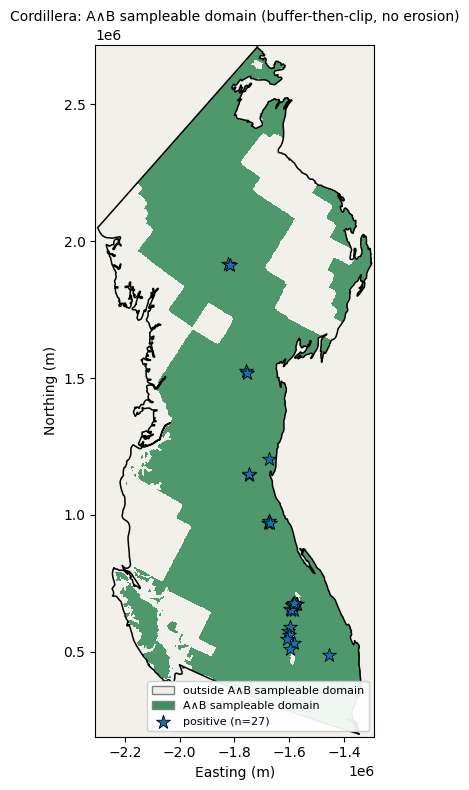

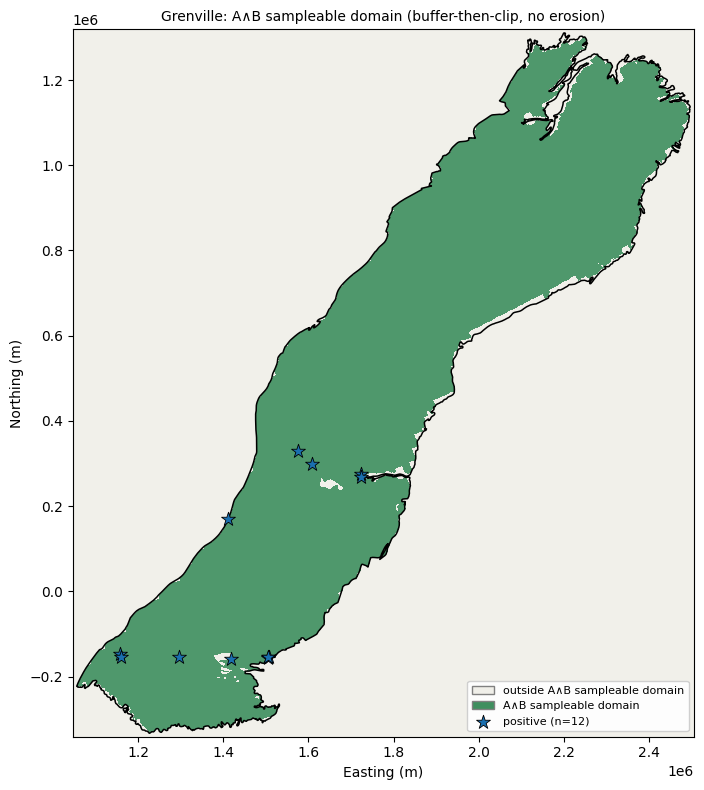

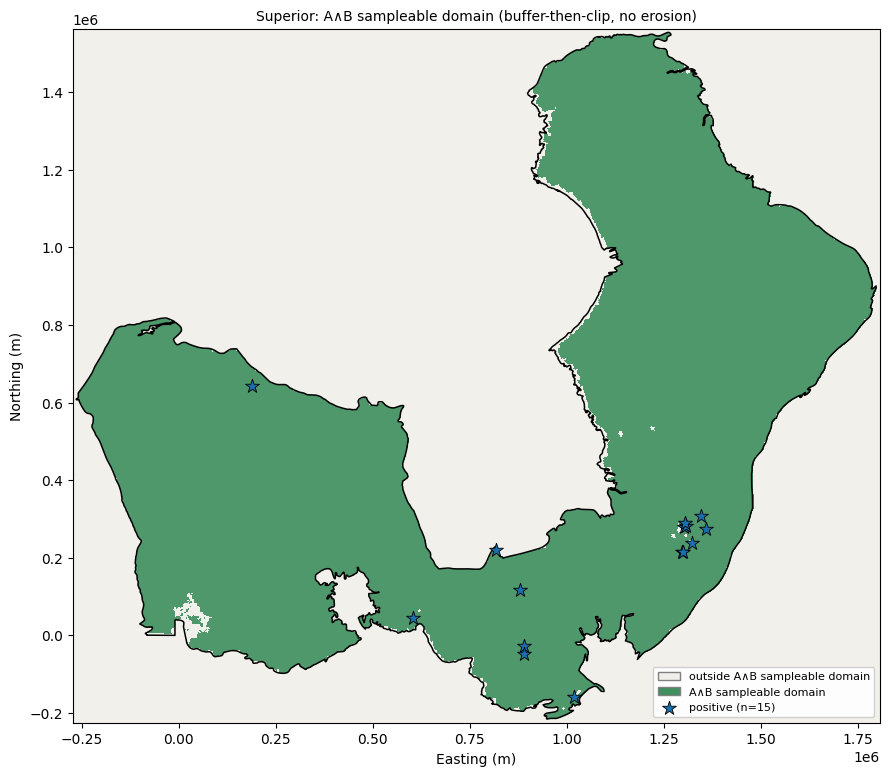

In [9]:
def plot_sampleable_domain(name):
    info = SAMPLEABLE[name]
    ref_tf, shape = info['ref_tf'], info['ref_shape']
    H, W = shape
    extent = [ref_tf.c, ref_tf.c + W * ref_tf.a, ref_tf.f + H * ref_tf.e, ref_tf.f]

    fig, ax = plt.subplots(figsize=(9, 8))
    ax.imshow(info['sampleable'].astype(int), extent=extent, origin='upper',
              cmap=mcolors.ListedColormap(['#f0efe9', '#3f8f5f']), vmin=0, vmax=1, alpha=0.92)

    boundary = gpd.read_file(REGIONS[name]['outline']).to_crs(PROJECTED_CRS)
    for geom in boundary.geometry:
        polys = [geom] if geom.geom_type == 'Polygon' else list(geom.geoms)
        for poly in polys:
            gx, gy = poly.exterior.xy
            ax.plot(gx, gy, 'k-', lw=1.1)

    tr = pyproj.Transformer.from_crs('EPSG:4326', PROJECTED_CRS, always_xy=True)
    pos = VERIFY_PTS[name][VERIFY_PTS[name]['label'] == 1]
    px_, py_ = tr.transform(pos['lon'].values, pos['lat'].values)
    ax.scatter(px_, py_, s=110, marker='*', c='#1a6faf', edgecolors='black', linewidths=0.6,
              zorder=5, label=f'positive (n={len(pos)})')

    legend_extra = [
        mpatches.Patch(facecolor='#f0efe9', edgecolor='grey', label='outside A∧B sampleable domain'),
        mpatches.Patch(facecolor='#3f8f5f', edgecolor='grey', label='A∧B sampleable domain'),
    ]
    h, l = ax.get_legend_handles_labels()
    ax.legend(handles=legend_extra + h, loc='lower right', fontsize=8, framealpha=0.92)
    ax.set_title(f'{name}: A∧B sampleable domain (buffer-then-clip, no erosion)', fontsize=10)
    ax.set_xlabel('Easting (m)'); ax.set_ylabel('Northing (m)'); ax.set_aspect('equal')
    plt.tight_layout(); plt.show()

for name in REGIONS:
    plot_sampleable_domain(name)

## 4. Build Region Feature Table

In [10]:
def build_region(name, cfg, worm_trees):
    print(f'\n[{name}] building features ...')
    rng = np.random.default_rng(RANDOM_SEED)

    pts = make_points(cfg, rng, name)

    print('  extracting terrane attributes (H3 Grid) ...')
    pts = add_terrane_h3(pts, CLIPPED_VECTORS[name].get('h3_grid'))

    print(f"  computing line-feature proximity ({', '.join(sorted(cfg['vectors']))}) ...")
    pts = add_proximity_line_layers(pts, cfg['vectors'])

    print('  computing point-feature proximity ...')
    pts = add_proximity_worms(pts, worm_trees)

    print('  sampling rasters ...')
    pts = add_rasters(pts, CLIPPED_RASTERS[name])

    print('  extracting GLCM texture features ...')
    pts = add_glcm_features(pts, CLIPPED_RASTERS[name])

    # Drop candidates where ALL rasters are NaN (outside raster coverage)
    raster_cols = list(CLIPPED_RASTERS[name].keys())
    pts = pts[pts[raster_cols].notna().any(axis=1)].reset_index(drop=True)

    # ── Shared background pools (RF and DevNet see IDENTICAL background
    # locations; only the label differs -- 0 for RF, unlabeled for DevNet).
    # This isolates "modeling paradigm" as the only variable between the two
    # models' evaluation. Draw the EVALUATION pool first, then the TRAINING
    # pool from what's left, guaranteeing disjointness -- pool_col retains
    # the legacy names ('eval_neg' / 'train_unlabeled') so every downstream
    # cell that filters on pts['pool'] keeps working unchanged; only what
    # populates those two pools has changed.
    n_candidates = int((pts['label'] == -1).sum())
    n_needed = N_TRAIN_BG + N_EVAL_BG
    if n_needed > n_candidates:
        shrink = n_candidates / n_needed
        n_train_bg = max(1, int(round(N_TRAIN_BG * shrink)))
        n_eval_bg  = max(1, int(round(N_EVAL_BG * shrink)))
        print(f'  WARNING: N_TRAIN_BG+N_EVAL_BG={n_needed} exceeds {n_candidates} available '
             f'A∧B candidates -- scaling BOTH pools down proportionally (ratio preserved) to '
             f'{n_train_bg}+{n_eval_bg}={n_train_bg + n_eval_bg}.')
    else:
        n_train_bg, n_eval_bg = N_TRAIN_BG, N_EVAL_BG
    print(f'  [{name}] shared pools: N_TRAIN_BG={n_train_bg}  N_EVAL_BG={n_eval_bg}  '
         f'(of {n_candidates} A∧B candidates)')

    print(f'  selecting {n_eval_bg} shared EVALUATION background points (random) ...')
    eval_tbl = select_negatives_random(pts, n_eval_bg, seed=RANDOM_SEED)
    eval_neg_tbl = eval_tbl[eval_tbl['label'] == 0].reset_index(drop=True)

    # Remove the chosen evaluation background from the candidate pool so the
    # training-background draw below is guaranteed disjoint from it.
    cand_key    = pd.MultiIndex.from_arrays([pts['lat'].values, pts['lon'].values])
    eval_key    = pd.MultiIndex.from_arrays([eval_neg_tbl['lat'].values, eval_neg_tbl['lon'].values])
    is_eval_neg = pd.Series(cand_key.isin(eval_key), index=pts.index) & (pts['label'] == -1)
    pts_remaining = pts[(pts['label'] == 1) | ((pts['label'] == -1) & ~is_eval_neg)].reset_index(drop=True)

    # ── Shared training background: drawn from the REMAINING candidates
    # (disjoint from the evaluation pool by construction above). Used by BOTH
    # models during CV-fold training -- RF labels these 0, DevNet leaves them
    # unlabeled (semi-supervised) -- and by both production model fits.
    print(f'  selecting {n_train_bg} shared TRAINING background points (random) ...')
    unlabeled_tbl = select_negatives_random(pts_remaining, n_train_bg, seed=RANDOM_SEED)
    unlabeled_neg_tbl = unlabeled_tbl[unlabeled_tbl['label'] == 0].reset_index(drop=True)

    pos_tbl = pts[pts['label'] == 1].reset_index(drop=True)

    pos_tbl           = pos_tbl.copy();           pos_tbl['pool']           = 'positive'
    eval_neg_tbl      = eval_neg_tbl.copy();      eval_neg_tbl['pool']      = 'eval_neg'
    unlabeled_neg_tbl = unlabeled_neg_tbl.copy();  unlabeled_neg_tbl['pool'] = 'train_unlabeled'

    pts_out = pd.concat([pos_tbl, eval_neg_tbl, unlabeled_neg_tbl], ignore_index=True)

    npos, n_eval, n_unlab = len(pos_tbl), len(eval_neg_tbl), len(unlabeled_neg_tbl)
    print(f'  final: {npos} positive | {n_eval} shared evaluation background | '
          f'{n_unlab} shared training background (RF label=0 / DevNet unlabeled) | '
          f'{pts_out.shape[1]} columns')

    pts_out.to_csv(f'{name}_features_semisup_combined_dedup.csv', index=False)
    return pts_out

## 5. Feature Matrix

In [11]:
TERRANE_COLS = [f'geo_era_{e}' for e in ERA_DUMMY_GROUPS] + [f'lith_{g}' for g in LITH_DUMMY_GROUPS]  # 5 one-hot era dummies (full, no dropped reference) + 4 one-hot lithology dummies (LITH_GROUP_MAP, Section 3e) -- documentation only, not used for feature filtering below

# Feature-column selection is a DENYLIST, not an allowlist (replaces the old
# PROXIMITY_COLS/GLCM_COLS constants, which hardcoded fault/margin/worm/
# raster names): every column in `pts` is a model feature EXCEPT the
# bookkeeping ones (lat/lon/label/pool) and raw distance columns (*_dist_m --
# only their normalized *_proximity twin is a feature). This is necessary
# now that raster/vector/point layers are discovered from folders (Section
# 1) rather than a fixed, hand-named set -- there is no dataset-specific
# allowlist to keep in sync any more.
_NON_FEATURE_COLS = {'lat', 'lon', 'label', 'pool'}


def _is_feature_col(col):
    return col not in _NON_FEATURE_COLS and not col.endswith('_dist_m')


def feature_cols(pts):
    """All model-feature columns present in `pts`, in column order."""
    return [c for c in pts.columns if _is_feature_col(c)]


def feature_matrix(pts, scaler=None, imputer=None, fit=True, feat_subset=None):
    feat_cols = feature_cols(pts)
    if feat_subset is not None:
        feat_cols = [c for c in feat_cols if c in feat_subset]
    X = pts[feat_cols].astype(float).values
    y = pts['label'].values

    if imputer is None:
        imputer = SimpleImputer(strategy='median')
    if scaler is None:
        scaler = StandardScaler()

    if fit:
        X = imputer.fit_transform(X)
        X = scaler.fit_transform(X)
    else:
        X = imputer.transform(X)
        X = scaler.transform(X)

    return X, y, feat_cols, scaler, imputer


## 5a. Unsupervised Collinearity Pruning (per region)

Each region has its own correlation structure among the ~50 candidate
features, so pruning is done **independently per region** and can keep a
different number/set of features in each — that's allowed, since the
research design is "same method, independently modeled per region," not "same
feature set across regions." What must stay identical *within* a region is
that RF and DevNet see the same pruned set, and that the pruned set used for
evaluation is the same one used for the production model and the prediction
map.

`prune_collinear(pts, feat_cols, thresh)`:

1. Computes a **Spearman** correlation matrix over the feature columns only
   — the label is never included, so this is purely unsupervised and cannot
   leak CV information.
2. Median-imputes the features **only for this correlation calculation** (it
   does not alter `pts` or anything downstream) so `NaN`s don't break the
   correlation matrix.
3. Clusters features with hierarchical clustering (`scipy.linkage`,
   `method='average'`, distance `1 - |corr|`, cut at `t = 1 - thresh`) — any
   two features correlated above `thresh` (in absolute value) end up in the
   same cluster.
4. Keeps **one representative per cluster**, chosen by a fixed, objective
   rule: lowest missing-value rate first, ties broken by highest variance.
   Never by which one gives a better AUC — no supervised signal enters this
   choice at all.

`plot_collinearity_heatmap` draws the full Spearman correlation matrix for a
region with the kept features bold-labeled, so pruning can be sanity-checked
visually.


In [12]:
def prune_collinear(pts, feat_cols, thresh=COLLINEARITY_THRESH):
    """Unsupervised collinearity pruning. Clusters feat_cols by
    1 - |Spearman correlation| (average-linkage hierarchical clustering, cut
    at 1 - thresh) and keeps one representative per cluster: lowest
    missing-rate first, ties broken by highest variance. Never looks at the
    label column or any model metric -- purely a feature-to-feature
    statistic, so there is no CV leakage and no supervised feature selection.
    Returns the kept feature names, in their original relative order."""
    X = pts[feat_cols].astype(float).values
    X_imp = SimpleImputer(strategy='median').fit_transform(X)  # for the correlation calc only

    corr = pd.DataFrame(X_imp, columns=feat_cols).corr(method='spearman').values
    # A zero-variance column (e.g. a one-hot era/lithology dummy that never
    # occurs in this region's candidate pool -- expected now that geo_era is
    # a full one-hot with no dropped reference level) makes Spearman
    # correlation undefined (NaN) against every other column. Treat that as
    # "no relationship" (it can't be redundant with anything if it never
    # varies) rather than letting NaN reach linkage(), which rejects any
    # non-finite value outright.
    const_cols = [feat_cols[i] for i in np.where(np.nanvar(X_imp, axis=0) == 0)[0]]
    if const_cols:
        print(f'  prune_collinear: {len(const_cols)} zero-variance column(s) in this region '
             f'(kept as standalone features, treated as uncorrelated with everything): {const_cols}')
    corr = np.nan_to_num(corr, nan=0.0)
    dist = 1.0 - np.abs(corr)
    np.fill_diagonal(dist, 0.0)
    dist = (dist + dist.T) / 2.0  # guard against float asymmetry
    condensed = squareform(dist, checks=False)

    Z = linkage(condensed, method='average')
    cluster_ids = fcluster(Z, t=1.0 - thresh, criterion='distance')

    missing_rate = np.isnan(X).mean(axis=0)
    variance     = np.nanvar(X, axis=0)

    kept = []
    print(f'  prune_collinear(thresh={thresh}): {len(feat_cols)} features -> '
          f'{len(np.unique(cluster_ids))} groups')
    for cid in np.unique(cluster_ids):
        idx = np.where(cluster_ids == cid)[0]
        if len(idx) == 1:
            kept.append(feat_cols[idx[0]])
            continue
        # objective, fixed rule: lowest missingness wins; ties -> highest variance
        rep = sorted(idx, key=lambda i: (missing_rate[i], -variance[i]))[0]
        kept.append(feat_cols[rep])
        members = [feat_cols[i] for i in idx]
        print(f'    group {members} -> kept {feat_cols[rep]!r} '
              f'(missing={missing_rate[rep]:.2f}, var={variance[rep]:.3g})')
    # preserve the original master-list order rather than cluster-id order
    kept_set = set(kept)
    return [c for c in feat_cols if c in kept_set]


def plot_collinearity_heatmap(pts, feat_cols, kept_cols, name, thresh=COLLINEARITY_THRESH):
    """Full Spearman correlation heatmap for a region's candidate features,
    with the features prune_collinear kept bold-labeled -- a visual check
    that the unsupervised pruning is behaving sensibly."""
    X = pts[feat_cols].astype(float).values
    X_imp = SimpleImputer(strategy='median').fit_transform(X)
    corr = pd.DataFrame(X_imp, columns=feat_cols).corr(method='spearman').values
    corr = np.nan_to_num(corr, nan=0.0)  # zero-variance columns -> undefined correlation -> 0, see prune_collinear

    div_cmap = mcolors.LinearSegmentedColormap.from_list(
        'blue_red_div', ['#2a78d6', '#f0efec', '#d03b3b'])

    fig, ax = plt.subplots(figsize=(max(8, len(feat_cols) * 0.22), max(7, len(feat_cols) * 0.22)))
    im = ax.imshow(corr, cmap=div_cmap, vmin=-1, vmax=1)
    ax.set_xticks(range(len(feat_cols))); ax.set_xticklabels(feat_cols, rotation=90, fontsize=6)
    ax.set_yticks(range(len(feat_cols))); ax.set_yticklabels(feat_cols, fontsize=6)
    kept_set = set(kept_cols)
    for tick, col in zip(ax.get_xticklabels(), feat_cols):
        tick.set_fontweight('bold' if col in kept_set else 'normal')
        tick.set_color('#0b0b0b' if col in kept_set else '#898781')
    for tick, col in zip(ax.get_yticklabels(), feat_cols):
        tick.set_fontweight('bold' if col in kept_set else 'normal')
        tick.set_color('#0b0b0b' if col in kept_set else '#898781')
    fig.colorbar(im, ax=ax, label='Spearman correlation', shrink=0.8)
    ax.set_title(f'{name}: feature correlation — bold = kept after '
                f'|corr|>{thresh} pruning ({len(kept_cols)}/{len(feat_cols)})',
                fontsize=10)
    plt.tight_layout()
    plt.show()


## 6. Evaluation Protocol — Fold-Safe Pooled OOF, Repeated CV

The rest of the notebook shares **one** evaluation engine between Random
Forest and DevNet so the two are judged under an identical protocol:

- `get_raw_features` pulls the *unimputed, unscaled* feature matrix — the
  same column set as `feature_matrix` above (`PROXIMITY_COLS + TERRANE_COLS +
  raster_cols + GLCM_COLS`) — so that imputation/scaling can be fit inside
  each fold instead of on the whole dataset.
- `pooled_oof_eval` runs one `StratifiedKFold`, converts each fold's
  validation scores to **within-fold percentile ranks** (`rankdata / n`),
  and pools all folds' ranks + labels into a **single** AUC/AP — never an
  average of per-fold AUCs.
- `repeated_pooled_auc` repeats that whole pooled-OOF procedure
  `CV_N_REPEATS` times (`RepeatedStratifiedKFold`) and returns the array of
  per-repeat pooled AUCs, from which we report the median and a
  [2.5, 97.5] percentile interval.

A `fold_scorer(X_tr_raw, y_tr, X_va_raw, seed_counter)` callable is the only
thing that differs between models — Random Forest and DevNet each provide
one in the sections that follow.


In [13]:
def get_raw_features(pts, feat_subset=None):
    """Raw (unimputed, unscaled) feature matrix — same column selection as
    feature_matrix(), so RF/DevNet fold-safe scorers can fit their own
    imputer/scaler per fold instead of on the whole dataset. Pass feat_subset
    (e.g. REGION_FEATS[name]) to restrict to a pruned feature list; the
    master column order is preserved either way."""
    feat_cols = feature_cols(pts)
    if feat_subset is not None:
        feat_cols = [c for c in feat_cols if c in feat_subset]
    X = pts[feat_cols].astype(float).values
    y = pts['label'].values
    return X, y, feat_cols


def pooled_oof_eval(X_raw, y, fold_scorer, n_splits=CV_N_SPLITS, seed=RANDOM_SEED):
    """One stratified CV pass. Returns (auc, ap, oof_rank) where oof_rank is
    the per-fold percentile rank of every sample's out-of-fold score, pooled
    across folds before computing a single AUC/AP."""
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    n = len(y)
    oof_rank = np.full(n, np.nan)
    for k, (tr_idx, va_idx) in enumerate(cv.split(X_raw, y)):
        va_scores = fold_scorer(X_raw[tr_idx], y[tr_idx], X_raw[va_idx], seed_counter=k)
        oof_rank[va_idx] = rankdata(va_scores) / len(va_scores)
    auc = roc_auc_score(y, oof_rank)
    ap  = average_precision_score(y, oof_rank)
    return auc, ap, oof_rank


def repeated_pooled_auc(X_raw, y, fold_scorer, n_splits=CV_N_SPLITS,
                        n_repeats=CV_N_REPEATS, seed=RANDOM_SEED):
    """Distribution of the pooled-OOF AUC across independent 5-fold splits.
    Returns an array of length n_repeats (one pooled AUC per repeat) —
    report median + [2.5, 97.5] percentile, not a single mean."""
    rskf = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=seed)
    n = len(y)
    repeat_aucs = []
    oof_rank = np.full(n, np.nan)
    counter = 0
    for k, (tr_idx, va_idx) in enumerate(rskf.split(X_raw, y)):
        if k > 0 and k % n_splits == 0:
            repeat_aucs.append(roc_auc_score(y, oof_rank))
            oof_rank = np.full(n, np.nan)
        va_scores = fold_scorer(X_raw[tr_idx], y[tr_idx], X_raw[va_idx], seed_counter=counter)
        oof_rank[va_idx] = rankdata(va_scores) / len(va_scores)
        counter += 1
    repeat_aucs.append(roc_auc_score(y, oof_rank))
    return np.array(repeat_aucs)



## 7. Random Forest — Fold-Safe Pipeline

`rf_fold_scorer` builds a fresh `Pipeline(SimpleImputer(median) →
StandardScaler → RandomForestClassifier)` and fits it **only on the training
fold**, then predicts probabilities on the validation fold — so imputation
and scaling never see the validation fold's data, keeping the reported AUC
leakage-free.


In [14]:
RF_PARAMS = dict(n_estimators=300, max_features='sqrt',
                 class_weight='balanced', random_state=RANDOM_SEED)

def make_rf_pipeline():
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler',  StandardScaler()),
        ('rf',      RandomForestClassifier(**RF_PARAMS)),
    ])

def rf_fold_scorer(X_tr_raw, y_tr, X_va_raw, seed_counter=0):
    pipe = make_rf_pipeline()
    pipe.fit(X_tr_raw, y_tr)
    return pipe.predict_proba(X_va_raw)[:, 1]


def rf_shared_bg_fold_scorer_factory(X_train_bg_raw):
    """RF fold scorer trained on (this fold's positive subset + the FULL
    shared TRAINING background pool, labeled 0) -- mirrors
    devnet_semisup_fold_scorer_factory's training-set construction exactly
    (same external background pool, just labeled 0 instead of left
    unlabeled), so RF and DevNet are trained on the IDENTICAL set of
    background locations and differ only in label semantics / loss. The
    fold's own eval-pool rows in X_tr_raw are intentionally ignored for
    training (same rationale as DevNet's own scorer) -- the shared
    evaluation pool exists only to be scored against, never to teach either
    model what "negative" looks like during CV.
    """
    def scorer(X_tr_raw, y_tr, X_va_raw, seed_counter=0):
        X_pos_tr = X_tr_raw[y_tr == 1]
        X_train_raw = np.vstack([X_pos_tr, X_train_bg_raw])
        y_train     = np.concatenate([np.ones(len(X_pos_tr)), np.zeros(len(X_train_bg_raw))])
        pipe = make_rf_pipeline()
        pipe.fit(X_train_raw, y_train)
        return pipe.predict_proba(X_va_raw)[:, 1]
    return scorer

## 8. DevNet — Corrected Deviation Loss + Per-Region Capacity

**`_REF`** is a single 50,000-sample reference pool built once; every batch
computes a stable z-score against its fixed mean/std, rather than resampling
the reference distribution independently each batch (which would inject an
extra source of gradient noise on top of the actual training signal).

**`deviation_loss`** — standard DevNet: negatives pulled to `z≈0`,
positives pushed past `z>margin`. Batches are label-balanced 50/50, with
positives oversampled with replacement up to the negative count. This is the
only loss actually used below — `RUN_LOSSES` is locked to `['deviation']`
in Section 1a — so it is the sole loss driving both the comparison table and
the production model; `ranking_loss` is still defined in the code but is
never called, kept only for reference.

**Per-region capacity:** `DevNet`, `train_devnet`, and
`devnet_fold_scorer_factory` now take an explicit `model_cfg`
(`hidden`/`dropout`/`weight_decay`) instead of hard-coded globals, so
Cordillera (44 positives) can use a larger, weaker-regularized net while
Superior/Grenville (single-digit positives) stay small and heavily
regularized — see `REGION_MODEL_CFG` above. The same `model_cfg` is used for
both evaluation and the production model trained on all of a region's data,
so the two are directly comparable.

`ensemble_score` rank-averages a list of trained DevNets — the same
combination rule `devnet_fold_scorer_factory` uses internally — so the
production model (Section 9) can be shipped as the same kind of
`DN_RESTARTS`-model ensemble that was actually evaluated, rather than a
single model.


**Semi-supervised fold scorer (`devnet_semisup_fold_scorer_factory`):** within
a CV fold, DevNet is trained on that fold's positives plus the region's
*entire* unlabeled pool (`train_unlabeled`), and is scored on that fold's
held-out rows from the labeled set (positives + `eval_neg`) -- exactly the
`fold_scorer(X_tr_raw, y_tr, X_va_raw, seed_counter) -> va_scores` interface
`pooled_oof_eval` / `repeated_pooled_auc` already expect, so their internals
need no changes. The fold's own `eval_neg` rows in `X_tr_raw` are
deliberately **not** used for training -- only the fold's positives are
extracted from `X_tr_raw`/`y_tr`; the unlabeled pool supplies every
"background" example instead. The original discriminative
`devnet_fold_scorer_factory` is left in place for reference but is not used
below.


In [15]:
torch.manual_seed(RANDOM_SEED)
DEVICE = torch.device('cpu') if FORCE_CPU else torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE, ' (FORCE_CPU=%s)' % FORCE_CPU)

# ── Fixed reference pool (built once, reused by every batch/fold/restart) ──
_REF = torch.randn(50000)

def deviation_loss(scores, labels, margin=DN_MARGIN, ref=_REF):
    ref = ref.to(scores.device)
    dev = (scores - ref.mean()) / ref.std()          # stable z-score
    inlier  = dev[labels == 0].abs().mean()          # negatives -> dev ~ 0
    outlier = torch.clamp(margin - dev[labels == 1], min=0).mean()  # positives -> dev > margin
    return inlier + outlier


def ranking_loss(scores, labels, margin=RANK_MARGIN):
    pos, neg = scores[labels == 1], scores[labels == 0]
    if pos.numel() == 0 or neg.numel() == 0:
        return scores.sum() * 0.0
    diff = margin - (pos.unsqueeze(1) - neg.unsqueeze(0))  # (P, N) all pairs
    return torch.clamp(diff, min=0).mean()


_LOSS_FNS    = {'deviation': deviation_loss, 'ranking': ranking_loss}
_LOSS_MARGIN = {'deviation': DN_MARGIN,      'ranking': RANK_MARGIN}


class DevNet(nn.Module):
    def __init__(self, input_dim, hidden, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, 1),
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)


def _make_batch(X_t, y_t, pos_idx, neg_idx, rng, loss_type):
    if loss_type == 'deviation':
        n_half = DN_BATCH // 2
        pi = rng.choice(pos_idx, n_half, replace=True)                       # oversample positives
        ni = rng.choice(neg_idx, n_half, replace=len(neg_idx) < n_half)
        idx = np.concatenate([pi, ni])
    else:  # ranking: all true positives, negatives ~RANK_NEG_RATIO:1, no oversampling
        n_neg_b = min(len(neg_idx), len(pos_idx) * RANK_NEG_RATIO)
        ni = rng.choice(neg_idx, n_neg_b, replace=False)
        idx = np.concatenate([pos_idx, ni])
    rng.shuffle(idx)
    return X_t[idx], y_t[idx]


def train_devnet(X_tr, y_tr, loss_type, seed, model_cfg=DEFAULT_MODEL_CFG,
                 epochs=DN_EPOCHS, record_losses=False, margin=None):
    """Train one DevNet instance on already-imputed/scaled data, sized and
    regularized according to model_cfg (hidden/dropout/weight_decay) so each
    region can use its own capacity.

    margin=None (default, used by every call site in the main experiment)
    reproduces the original behaviour exactly -- falls back to
    _LOSS_MARGIN[loss_type] (DN_MARGIN for the deviation loss). Passing an
    explicit margin overrides it for that one call only, without touching
    the DN_MARGIN/_LOSS_MARGIN globals -- added for the DN_MARGIN
    sensitivity ablation (Section 11b) so it can sweep margins without any
    risk of leaking a mutated global into the main experiment's own calls.
    """
    torch.manual_seed(seed)
    X_t = torch.tensor(X_tr, dtype=torch.float32, device=DEVICE)
    y_t = torch.tensor(y_tr, dtype=torch.float32, device=DEVICE)
    model = DevNet(X_t.shape[1], hidden=model_cfg['hidden'],
                   dropout=model_cfg['dropout']).to(DEVICE)
    opt   = optim.Adam(model.parameters(), lr=DN_LR,
                       weight_decay=model_cfg['weight_decay'])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs, eta_min=1e-5)

    pos_idx = np.where(y_tr == 1)[0]
    neg_idx = np.where(y_tr == 0)[0]
    rng     = np.random.default_rng(seed)
    loss_fn = _LOSS_FNS[loss_type]
    margin  = _LOSS_MARGIN[loss_type] if margin is None else margin

    losses = []
    model.train()
    for _ in range(epochs):
        xb, yb = _make_batch(X_t, y_t, pos_idx, neg_idx, rng, loss_type)
        opt.zero_grad()
        loss = loss_fn(model(xb), yb, margin)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        opt.step()
        sched.step()
        if record_losses:
            losses.append(loss.item())
    return model, losses


def devnet_fold_scorer_factory(loss_type, model_cfg=DEFAULT_MODEL_CFG,
                               restarts=None, base_seed=DN_SEED):
    """Returns a fold_scorer(X_tr_raw, y_tr, X_va_raw, seed_counter) that:
    1. fits imputer+scaler on the training fold only,
    2. trains `restarts` (defaults to the current global DN_RESTARTS,
       re-read at call time so FAST_MODE takes effect) independent DevNets
       sized per model_cfg,
    3. combines them by RANK-averaging the validation predictions, since raw
       DevNet score scale can differ between restarts/initializations."""
    def scorer(X_tr_raw, y_tr, X_va_raw, seed_counter=0):
        n_restarts = DN_RESTARTS if restarts is None else restarts
        imp = SimpleImputer(strategy='median').fit(X_tr_raw)
        sc  = StandardScaler().fit(imp.transform(X_tr_raw))
        X_tr = sc.transform(imp.transform(X_tr_raw))
        X_va = sc.transform(imp.transform(X_va_raw))

        rank_accum = np.zeros(len(X_va))
        for k in range(n_restarts):
            seed = base_seed + seed_counter * 1000 + k
            model, _ = train_devnet(X_tr, y_tr, loss_type, seed=seed, model_cfg=model_cfg)
            model.eval()
            with torch.no_grad():
                va_scores = model(
                    torch.tensor(X_va, dtype=torch.float32, device=DEVICE)
                ).cpu().numpy()
            rank_accum += rankdata(va_scores) / len(va_scores)
        return rank_accum / n_restarts
    return scorer


def ensemble_score(models, X):
    """Rank-average scores from a list of trained DevNets -- the same
    combination rule devnet_fold_scorer_factory uses -- so a production
    ensemble can be scored identically to how it was evaluated."""
    acc = np.zeros(len(X))
    for m in models:
        m.eval()
        with torch.no_grad():
            s = m(torch.tensor(X, dtype=torch.float32, device=DEVICE)).cpu().numpy()
        acc += rankdata(s) / len(s)
    return acc / len(models)



def devnet_semisup_fold_scorer_factory(X_unlabeled_raw, model_cfg=DEFAULT_MODEL_CFG,
                                       restarts=None, base_seed=DN_SEED, margin=None):
    """Semi-supervised DevNet fold scorer. TRAINS on (this fold's positives +
    the region's full unlabeled background pool) with the deviation loss, but
    is SCORED on X_va_raw as passed in by pooled_oof_eval/repeated_pooled_auc
    (that fold's held-out positives + eval_neg). The fold's own eval_neg rows
    in X_tr_raw are intentionally ignored for training -- eval_neg exists
    only to be scored against, never to teach the model what "negative"
    looks like, so it stays a fair, never-trained-on evaluation set.

    margin=None (default, every main-experiment call site) reproduces the
    original behaviour exactly -- train_devnet falls back to
    _LOSS_MARGIN['deviation'] (DN_MARGIN). Passing an explicit margin here
    threads it through to every train_devnet call this scorer makes, for
    the DN_MARGIN sensitivity ablation (Section 11b) -- no global is ever
    mutated, so the main experiment's own (margin=None) calls are
    unaffected regardless of call order.
    """
    def scorer(X_tr_raw, y_tr, X_va_raw, seed_counter=0):
        n_restarts = DN_RESTARTS if restarts is None else restarts

        X_pos_tr = X_tr_raw[y_tr == 1]
        X_train_raw = np.vstack([X_pos_tr, X_unlabeled_raw])
        y_train     = np.concatenate([np.ones(len(X_pos_tr)), np.zeros(len(X_unlabeled_raw))])

        imp = SimpleImputer(strategy='median').fit(X_train_raw)
        sc  = StandardScaler().fit(imp.transform(X_train_raw))
        X_tr = sc.transform(imp.transform(X_train_raw))
        X_va = sc.transform(imp.transform(X_va_raw))

        rank_accum = np.zeros(len(X_va))
        for k in range(n_restarts):
            seed = base_seed + seed_counter * 1000 + k
            model, _ = train_devnet(X_tr, y_train, 'deviation', seed=seed, model_cfg=model_cfg,
                                    margin=margin)
            model.eval()
            with torch.no_grad():
                va_scores = model(
                    torch.tensor(X_va, dtype=torch.float32, device=DEVICE)
                ).cpu().numpy()
            rank_accum += rankdata(va_scores) / len(va_scores)
        return rank_accum / n_restarts
    return scorer

Device: cpu  (FORCE_CPU=False)


## 9. Run Evaluation — All Regions × All Models

For each region: build three pools (`positive` / `eval_neg` /
`train_unlabeled`), prune collinear features (Section 5a, unsupervised,
applied identically to all three pools), then run the full-vs-pruned
ablation (Section 5a's feature set, same as v4) for `RF` and
`DevNet(deviation)`.

**Shared-background design**: `eval_neg` and `train_unlabeled` are drawn
once per region (`build_region`, disjoint by construction, `train_unlabeled`
proportionally shrunk together with `eval_neg` if a region's A∧B candidate
pool can't supply both at full size) and used **identically by both
models** -- RF and DevNet are trained on the exact same set of background
locations, differing only in whether those locations are labelled negative
(RF) or left unlabelled (DevNet). This isolates "modeling paradigm" as the
only variable between the two models.

- `RF` uses `rf_shared_bg_fold_scorer_factory(train_unlabeled)` -- each CV
  fold, trains on (this fold's positive subset + the FULL shared
  `train_unlabeled` pool, labeled 0), scored on the fold's held-out
  `positive + eval_neg` rows.
- `DevNet(deviation)` uses `devnet_semisup_fold_scorer_factory` exactly as
  before -- trained on (this fold's positive subset + the FULL shared
  `train_unlabeled` pool, left unlabeled), scored on the same held-out
  `positive + eval_neg` rows.

Both go through the same unmodified `pooled_oof_eval` / `repeated_pooled_auc`
protocol from Section 6, and both are scored against the identical
`eval_neg` pool.

Production models are then fit on **all** of a region's data, both on the
same shared background pool: RF on `positive + train_unlabeled` (labeled
0); DevNet as a `DN_RESTARTS`-model ensemble on `positive + train_unlabeled`
(unlabeled) -- matching how each was evaluated. Finally, the production
DevNet ensemble scores every point in `train_unlabeled` and the top
`TOP_N_TARGETS` are saved as candidate new targets -- the actual point of
training on an unlabeled background pool instead of a curated negative set.


Building point-feature KDTrees ...
  loading worms: DeepGravitySources_Worms_USCanada ...
    128,013 points  tree built
  loading worms: DeepMagSources_Worms_USCanada ...
    62,151 points  tree built
  loading worms: ShallowGravitySources_Worms_USCanada ...
    946,704 points  tree built
  loading worms: ShallowMagSources_Worms_USCanada ...
    1,664,475 points  tree built

[Cordillera]

[Cordillera] building features ...
    'Lempriere' at (lat=52.4022, lon=-119.1383)
  Candidate grid: 22724 (>BUFFER_KM from any deposit) -> 16473 after A∧B sampleable-domain filter (72.5% kept)
  Positive: 27  |  Candidates: 16473
  extracting terrane attributes (H3 Grid) ...
  computing line-feature proximity (AncientPassiveMargins, Faults_Canada) ...
  computing point-feature proximity ...
  sampling rasters ...
  extracting GLCM texture features ...
    GLCM: Canada_BA → 4 texture features (nodata-aware)
    GLCM: Canada_BA_HP40km → 4 texture features (nodata-aware)
    GLCM: DRTP → 4 texture feat

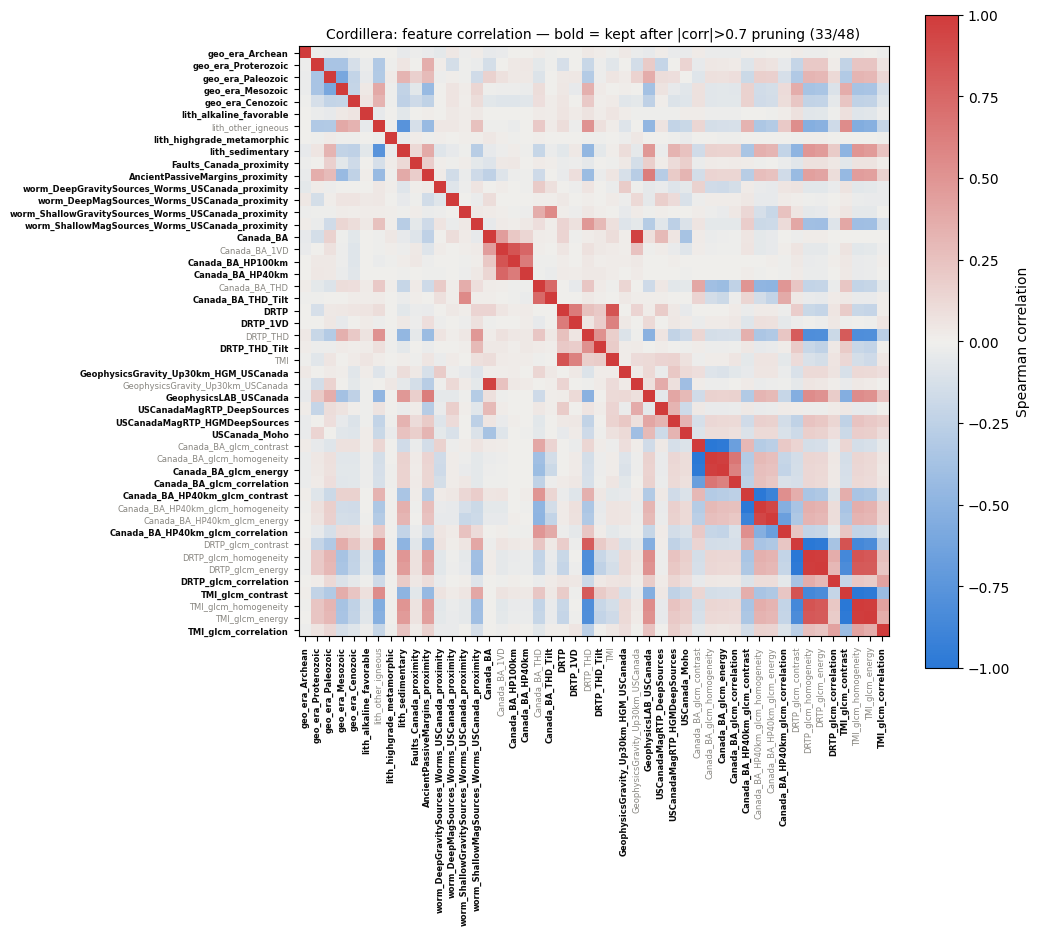

  [Cordillera] collinearity pruning: 48 -> 33 features
  positives=27  eval_near_negatives=3000  unlabeled_pool=5000  full_features=48
  model_cfg = {'hidden': 64, 'dropout': 0.3, 'weight_decay': 0.0001}
  [Cordillera] DevNet eval (full+pruned ablation) ≈ (n_repeats*5 + 5) * restarts * n_losses * 2 feature sets = 350 次训练
  -- RF [full, 48 feats, discriminative (positive vs. shared background, labeled negative)] --
    pooled OOF (5-fold):        AUC=0.897  AP=0.311
    repeated pooled OOF (5x6): median AUC=0.903  95% CI=[0.880, 0.933]
  -- RF [pruned, 33 feats, discriminative (positive vs. shared background, labeled negative)] --
    pooled OOF (5-fold):        AUC=0.918  AP=0.393
    repeated pooled OOF (5x6): median AUC=0.916  95% CI=[0.878, 0.933]
  -- DevNet(deviation) [full, 48 feats, semi-supervised (positive vs. shared background, left unlabeled)] --
    pooled OOF (5-fold):        AUC=0.874  AP=0.092
    repeated pooled OOF (5x6): median AUC=0.874  95% CI=[0.835, 0.888]
  -- De

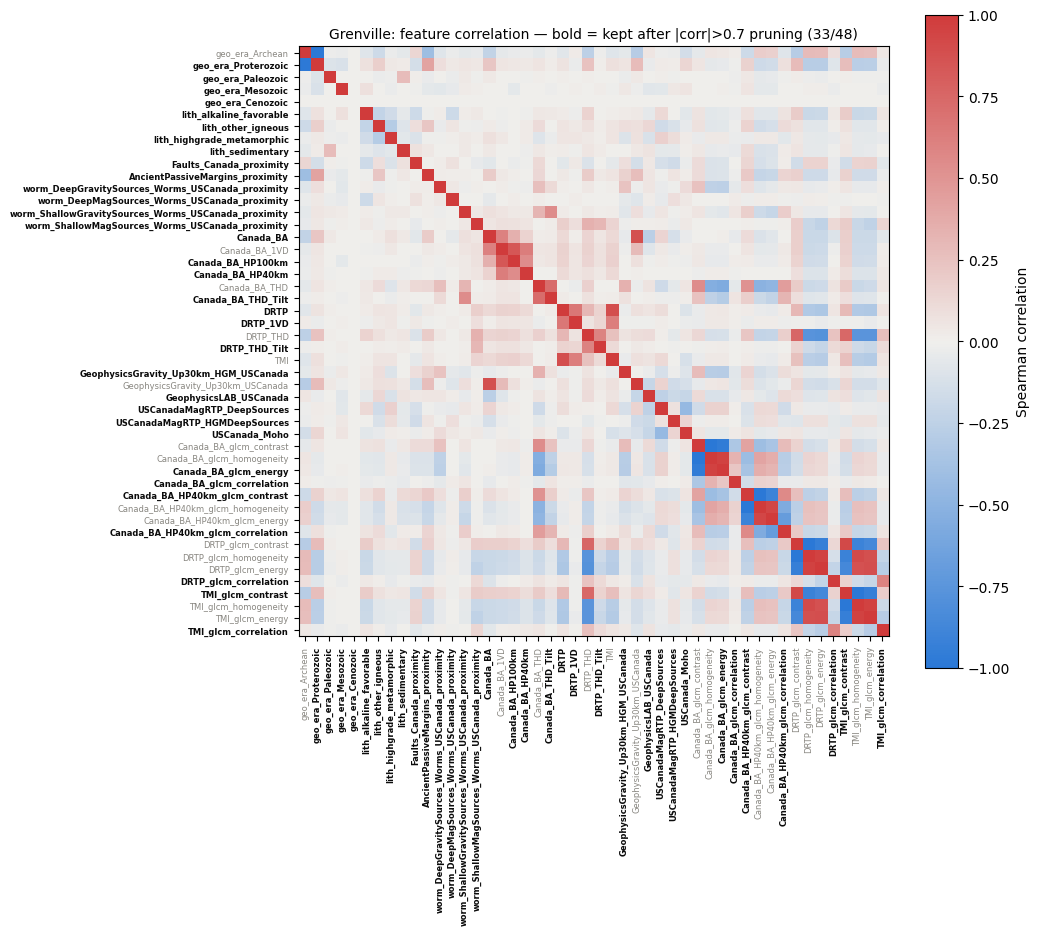

  [Grenville] collinearity pruning: 48 -> 33 features
  positives=12  eval_near_negatives=3000  unlabeled_pool=5000  full_features=48
  model_cfg = {'hidden': 32, 'dropout': 0.4, 'weight_decay': 0.001}
  [Grenville] DevNet eval (full+pruned ablation) ≈ (n_repeats*5 + 5) * restarts * n_losses * 2 feature sets = 350 次训练
  -- RF [full, 48 feats, discriminative (positive vs. shared background, labeled negative)] --
    pooled OOF (5-fold):        AUC=0.750  AP=0.123
    repeated pooled OOF (5x6): median AUC=0.859  95% CI=[0.761, 0.910]
  -- RF [pruned, 33 feats, discriminative (positive vs. shared background, labeled negative)] --
    pooled OOF (5-fold):        AUC=0.835  AP=0.223
    repeated pooled OOF (5x6): median AUC=0.840  95% CI=[0.798, 0.865]
  -- DevNet(deviation) [full, 48 feats, semi-supervised (positive vs. shared background, left unlabeled)] --
    pooled OOF (5-fold):        AUC=0.678  AP=0.050
    repeated pooled OOF (5x6): median AUC=0.702  95% CI=[0.678, 0.752]
  -- DevNe

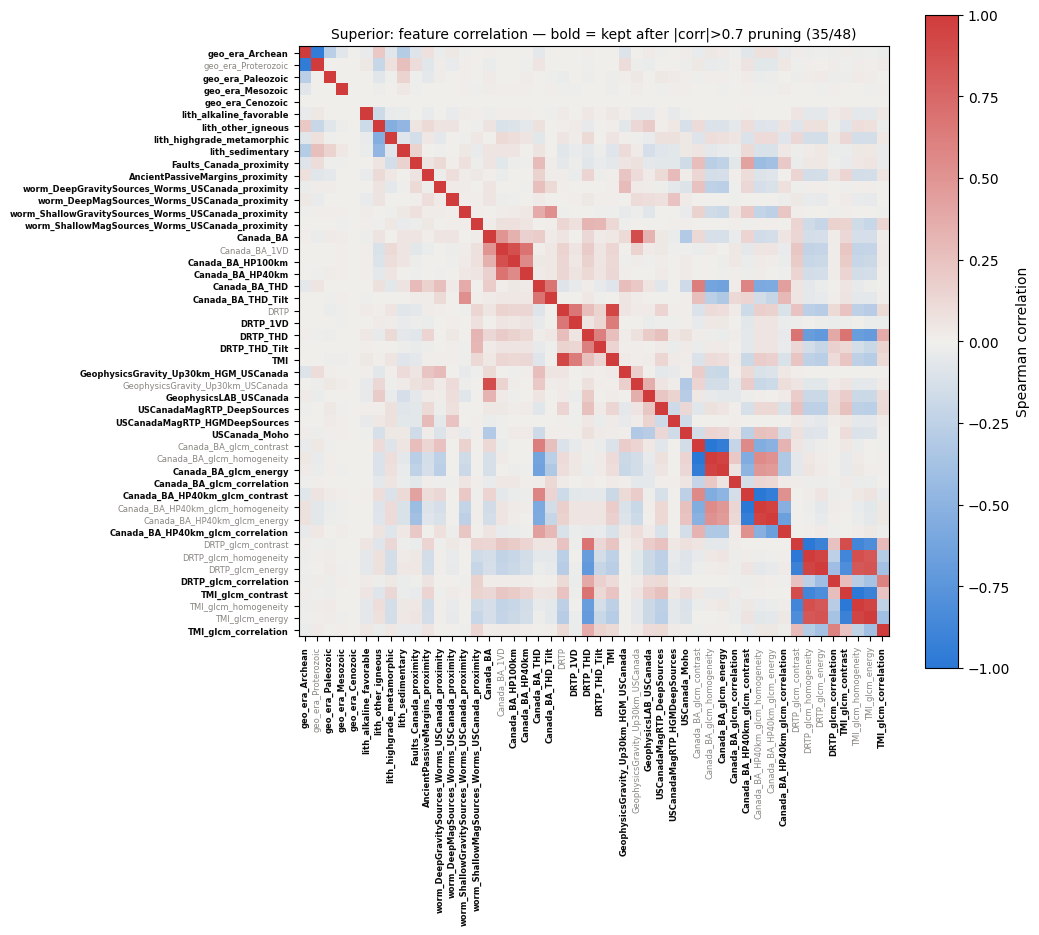

  [Superior] collinearity pruning: 48 -> 35 features
  positives=15  eval_near_negatives=3000  unlabeled_pool=5000  full_features=48
  model_cfg = {'hidden': 32, 'dropout': 0.4, 'weight_decay': 0.001}
  [Superior] DevNet eval (full+pruned ablation) ≈ (n_repeats*5 + 5) * restarts * n_losses * 2 feature sets = 350 次训练
  -- RF [full, 48 feats, discriminative (positive vs. shared background, labeled negative)] --
    pooled OOF (5-fold):        AUC=0.926  AP=0.210
    repeated pooled OOF (5x6): median AUC=0.958  95% CI=[0.927, 0.979]
  -- RF [pruned, 35 feats, discriminative (positive vs. shared background, labeled negative)] --
    pooled OOF (5-fold):        AUC=0.968  AP=0.202
    repeated pooled OOF (5x6): median AUC=0.969  95% CI=[0.913, 0.978]
  -- DevNet(deviation) [full, 48 feats, semi-supervised (positive vs. shared background, left unlabeled)] --
    pooled OOF (5-fold):        AUC=0.963  AP=0.411
    repeated pooled OOF (5x6): median AUC=0.956  95% CI=[0.927, 0.963]
  -- DevNet(

In [16]:
# Build point-feature KDTrees once (shared across all regions)
print('Building point-feature KDTrees ...')
_point_cfg = list(REGIONS.values())[0]['points']
WORM_TREES = build_worm_trees(_point_cfg)

REGION_PTS   = {}
REGION_FEATS = {}   # name -> pruned (collinearity-reduced) feature list
RESULTS      = {}   # name -> model -> feature_set('full'/'pruned') -> metrics
TRAINED      = {}   # name -> production models + top candidate targets

for name in RUN_REGIONS:
    cfg = REGIONS[name]
    print(f'\n{"="*70}\n[{name}]\n{"="*70}')
    pts = build_region(name, cfg, WORM_TREES)
    REGION_PTS[name] = pts

    pts_labeled   = pts[pts['pool'].isin(['positive', 'eval_neg'])].reset_index(drop=True)
    pts_unlabeled = pts[pts['pool'] == 'train_unlabeled'].reset_index(drop=True)

    feat_cols_full = feature_cols(pts)
    pruned_cols = prune_collinear(pts, feat_cols_full, thresh=COLLINEARITY_THRESH)
    REGION_FEATS[name] = pruned_cols
    plot_collinearity_heatmap(pts, feat_cols_full, pruned_cols, name, thresh=COLLINEARITY_THRESH)
    print(f'  [{name}] collinearity pruning: {len(feat_cols_full)} -> {len(pruned_cols)} features')

    X_full_labeled,   y, feat_cols_full_out = get_raw_features(pts_labeled)
    X_pruned_labeled, _, feat_cols_pruned   = get_raw_features(pts_labeled, feat_subset=pruned_cols)
    X_full_unlabeled,   _, _ = get_raw_features(pts_unlabeled)
    X_pruned_unlabeled, _, _ = get_raw_features(pts_unlabeled, feat_subset=pruned_cols)

    n_pos, n_eval_neg = int((y == 1).sum()), int((y == 0).sum())
    print(f'  positives={n_pos}  eval_near_negatives={n_eval_neg}  '
          f'unlabeled_pool={len(pts_unlabeled)}  full_features={len(feat_cols_full_out)}')

    model_cfg = REGION_MODEL_CFG.get(name, DEFAULT_MODEL_CFG)
    n_train_est = (CV_N_REPEATS * CV_N_SPLITS + CV_N_SPLITS) * DN_RESTARTS * len(RUN_LOSSES) * 2
    print(f'  model_cfg = {model_cfg}')
    print(f'  [{name}] DevNet eval (full+pruned ablation) ≈ (n_repeats*5 + 5) * restarts'
          f' * n_losses * 2 feature sets = {n_train_est} 次训练')

    RESULTS[name] = {}
    feature_sets = {
        'full':   (X_full_labeled,   feat_cols_full_out, X_full_unlabeled),
        'pruned': (X_pruned_labeled, feat_cols_pruned,   X_pruned_unlabeled),
    }
    for model_name in ['RF'] + [f'DevNet({lt})' for lt in RUN_LOSSES]:
        RESULTS[name][model_name] = {}
        for fs_name, (X_lab, cols_fs, X_unlab) in feature_sets.items():
            if model_name == 'RF':
                scorer = rf_shared_bg_fold_scorer_factory(X_unlab)
                paradigm = 'discriminative (positive vs. shared background, labeled negative)'
            else:
                scorer = devnet_semisup_fold_scorer_factory(X_unlab, model_cfg=model_cfg)
                paradigm = 'semi-supervised (positive vs. shared background, left unlabeled)'

            print(f'  -- {model_name} [{fs_name}, {len(cols_fs)} feats, {paradigm}] --')
            auc_oof, ap_oof, oof_rank = pooled_oof_eval(X_lab, y, scorer)
            print(f'    pooled OOF (5-fold):        AUC={auc_oof:.3f}  AP={ap_oof:.3f}')
            rep_aucs = repeated_pooled_auc(X_lab, y, scorer)
            med, lo, hi = np.median(rep_aucs), *np.percentile(rep_aucs, [2.5, 97.5])
            print(f'    repeated pooled OOF (5x{CV_N_REPEATS}): median AUC={med:.3f}  95% CI=[{lo:.3f}, {hi:.3f}]')
            RESULTS[name][model_name][fs_name] = {
                'n_features': len(cols_fs),
                'data_paradigm': paradigm,
                'oof_auc': auc_oof, 'oof_ap': ap_oof,
                'rep_aucs': rep_aucs, 'rep_median': med, 'rep_ci': (lo, hi),
                'oof_rank': oof_rank,
                'oof_y':    y,
            }

    # ── Production models: PRUNED feature set only, BOTH trained on the SAME
    # shared background locations (X_pruned_unlabeled) -- differing only in
    # label semantics, matching the CV evaluation protocol above exactly.
    # RF: all positives + shared background, labeled 0 (discriminative).
    X_pos_pruned_rf = X_pruned_labeled[y == 1]
    X_rf_train_raw  = np.vstack([X_pos_pruned_rf, X_pruned_unlabeled])
    y_rf_train      = np.concatenate([np.ones(len(X_pos_pruned_rf)), np.zeros(len(X_pruned_unlabeled))])
    rf_pipeline = make_rf_pipeline()
    rf_pipeline.fit(X_rf_train_raw, y_rf_train)

    # DevNet: ALL positives + the FULL shared background pool (semi-
    # supervised, same as its evaluation above) -- a DN_RESTARTS-model
    # rank-averaged ensemble, matching the protocol used to evaluate it.
    X_pos_pruned   = X_pruned_labeled[y == 1]
    X_dn_train_raw = np.vstack([X_pos_pruned, X_pruned_unlabeled])
    y_dn_train     = np.concatenate([np.ones(len(X_pos_pruned)), np.zeros(len(X_pruned_unlabeled))])
    dn_imputer = SimpleImputer(strategy='median').fit(X_dn_train_raw)
    dn_scaler  = StandardScaler().fit(dn_imputer.transform(X_dn_train_raw))
    X_dn_train = dn_scaler.transform(dn_imputer.transform(X_dn_train_raw))

    dn_ensemble, dn_losses = [], []
    for k in range(DN_RESTARTS):
        record = (k == 0)
        m, losses = train_devnet(X_dn_train, y_dn_train, 'deviation', seed=DN_SEED + k,
                                 model_cfg=model_cfg, record_losses=record)
        dn_ensemble.append(m)
        if record:
            dn_losses = losses

    # ── Score the unlabeled pool: DevNet's highest scorers among points it
    #    was told to treat as background are exactly the candidate new
    #    targets a semi-supervised setup is meant to surface. ────────────────
    X_unlab_scaled = dn_scaler.transform(dn_imputer.transform(X_pruned_unlabeled))
    unlab_scores = ensemble_score(dn_ensemble, X_unlab_scaled)
    top_idx = np.argsort(unlab_scores)[::-1][:TOP_N_TARGETS]
    top_targets = pts_unlabeled.iloc[top_idx][['lat', 'lon']].copy().reset_index(drop=True)
    top_targets['dn_score'] = unlab_scores[top_idx]
    top_targets.to_csv(f'{name}_top{TOP_N_TARGETS}_potential_targets_combined_dedup.csv', index=False)
    print(f'  [{name}] top {TOP_N_TARGETS} potential targets (highest DevNet score on the '
          f'unlabeled pool) -> {name}_top{TOP_N_TARGETS}_potential_targets_combined_dedup.csv')

    TRAINED[name] = {
        'pts': pts, 'feat_cols': pruned_cols,
        'rf_model':  rf_pipeline.named_steps['rf'],
        'rf_scaler': rf_pipeline.named_steps['scaler'],
        'rf_imp':    rf_pipeline.named_steps['imputer'],
        'dn_ensemble': dn_ensemble, 'dn_scaler': dn_scaler, 'dn_imp': dn_imputer,
        'dn_losses': dn_losses, 'model_cfg': model_cfg, 'top_targets': top_targets,
    }
    print(f'[{name}] evaluation + production fit complete '
          f'(RF and DevNet trained on the IDENTICAL shared background locations, '
          f'differing only in label -- 0 for RF, unlabeled for DevNet; both use pruned features).')

print(f'\nRegions evaluated: {RUN_REGIONS}  |  Losses: {RUN_LOSSES}')
print('Pruned feature sets in REGION_FEATS, results in RESULTS, production models in TRAINED.')

## 10. DevNet Training Loss Curve (production model)

Loss curve for the first member of the final full-data DevNet ensemble
(`LOSS_TYPE`, seed=`DN_SEED`) trained per region in Section 9 — should show
smooth, monotonic-ish convergence. The other `DN_RESTARTS - 1` ensemble
members are trained identically (different seeds) but without recording
their loss history.


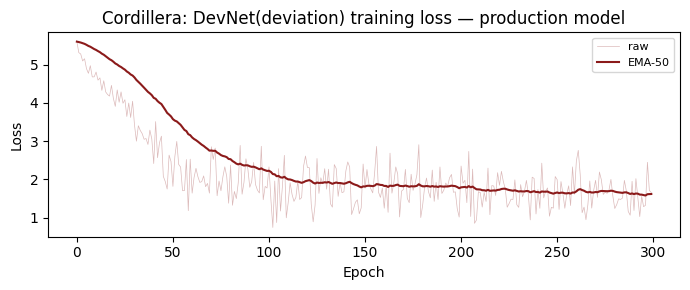

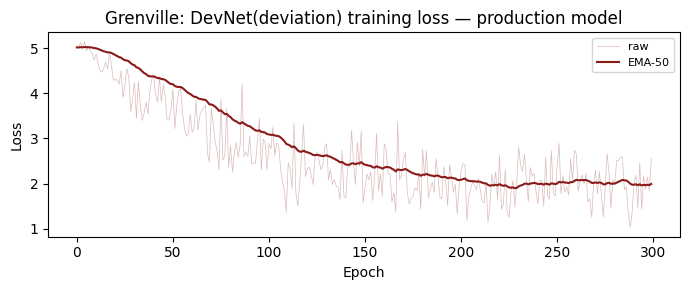

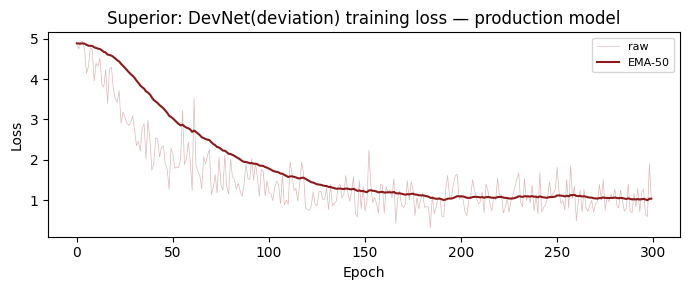

In [17]:
for name, t in TRAINED.items():
    losses = t['dn_losses']
    alpha = 2 / (50 + 1)
    ema = [losses[0]]
    for l in losses[1:]:
        ema.append(alpha * l + (1 - alpha) * ema[-1])
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.plot(losses, lw=0.5, alpha=0.3, color='#8b1a1a', label='raw')
    ax.plot(ema,    lw=1.5, color='#8b1a1a', label='EMA-50')
    ax.set_xlabel('Epoch'); ax.set_ylabel('Loss')
    ax.set_title(f'{name}: DevNet({LOSS_TYPE}) training loss — production model')
    ax.legend(fontsize=8); plt.tight_layout(); plt.show()


## 11. Comparison Table

Full-feature vs. pruned-feature ablation, exactly as in v4, plus a
**`data_paradigm`** column so RF and DevNet are never mistaken for having
been trained/evaluated on the same labels: RF is *discriminative*
(`positive` vs. `eval_neg`); DevNet is *semi-supervised*
(`positive` vs. `train_unlabeled` for training, scored against `eval_neg`).
With `FAST_MODE=True` the table only ever has the region(s) that were
actually evaluated, so it never indexes a combination that was never
computed.

**Caveat:** `eval_neg` is a random background subset of the candidate grid,
not confirmed barren ground -- it may contain a small number of undiscovered
deposits. Every AUC/AP below is therefore a conservative estimate (some
"false positives" scored against `eval_neg` could really be true positives
the survey hasn't found yet).


In [18]:
active_models = ['RF'] + [f'DevNet({lt})' for lt in RUN_LOSSES]
feature_set_names = ['full', 'pruned']

rows = []
for name in RUN_REGIONS:
    for model_name in active_models:
        for fs_name in feature_set_names:
            r = RESULTS[name][model_name][fs_name]
            rows.append({
                'region': name,
                'model': model_name,
                'data_paradigm': r['data_paradigm'],
                'feature_set': fs_name,
                'n_features': r['n_features'],
                'pooled_oof_auc': r['oof_auc'],
                'pooled_oof_ap':  r['oof_ap'],
                'repeatedCV_median_auc': r['rep_median'],
                'repeatedCV_ci_lo': r['rep_ci'][0],
                'repeatedCV_ci_hi': r['rep_ci'][1],
            })
comparison_df = pd.DataFrame(rows)

pd.set_option('display.width', 180)
print('Full vs. pruned feature-set ablation (pooled OOF / repeated-CV), by data paradigm:')
print(comparison_df.round(3).to_string(index=False))
print('\nCaveat: eval_neg is a random background subset, not confirmed barren ground -- '
      'it may contain a few undiscovered deposits, so the AUC/AP above are a conservative estimate.')


Full vs. pruned feature-set ablation (pooled OOF / repeated-CV), by data paradigm:
    region             model                                                     data_paradigm feature_set  n_features  pooled_oof_auc  pooled_oof_ap  repeatedCV_median_auc  repeatedCV_ci_lo  repeatedCV_ci_hi
Cordillera                RF discriminative (positive vs. shared background, labeled negative)        full          48           0.897          0.311                  0.903             0.880             0.933
Cordillera                RF discriminative (positive vs. shared background, labeled negative)      pruned          33           0.918          0.393                  0.916             0.878             0.933
Cordillera DevNet(deviation)  semi-supervised (positive vs. shared background, left unlabeled)        full          48           0.874          0.092                  0.874             0.835             0.888
Cordillera DevNet(deviation)  semi-supervised (positive vs. shared background, le

## 11b. DN_MARGIN Sensitivity Ablation

`DN_MARGIN=5` (the deviation loss's margin, `margin` in
`torch.clamp(margin - dev[labels==1], min=0)`) was carried over from Pang
et al. (2019)'s default and never actually validated on this data. This
section checks whether the main conclusions are sensitive to that choice.

**Scope (deliberately narrow to control compute):**
- `DN_MARGIN ∈ [2, 3, 5, 8]`.
- **DevNet(deviation) only** -- RF is never retrained (margin doesn't
  affect it at all).
- **Pruned feature set only** (`REGION_FEATS[name]`), not full.
- **Single `pooled_oof_eval`** (5-fold), not `repeated_pooled_auc` (30
  folds) -- this ablation doesn't need a confidence interval, just the
  point estimate's sensitivity to margin.
- `DN_RESTARTS` and all seeds (`RANDOM_SEED`, `DN_SEED`) are identical to
  the main experiment.

`train_devnet` and `devnet_semisup_fold_scorer_factory` (Section 8) both
take an optional `margin` parameter — `None` (the default, used everywhere
else in the notebook) falls back to `DN_MARGIN`; passing an explicit value
here overrides it for this ablation only, without touching the
`DN_MARGIN`/`_LOSS_MARGIN` globals the main experiment uses.

**Mandatory self-check:** the `margin=5` row below must reproduce Section
11's `DevNet(deviation)` / `pruned` row **exactly** (same seeds, same CV
splits, same data) -- if it doesn't, the ablation's call path has drifted
from the main experiment somewhere and the other margin values can't be
trusted; the cell raises rather than silently reporting numbers that don't
match.


In [19]:
DN_MARGIN_ABLATION_VALUES = [2, 3, 5, 8]

margin_ablation_rows = []
for name in RUN_REGIONS:
    pts         = REGION_PTS[name]
    feat_cols   = REGION_FEATS[name]
    model_cfg   = TRAINED[name]['model_cfg']

    pts_labeled   = pts[pts['pool'].isin(['positive', 'eval_neg'])].reset_index(drop=True)
    pts_unlabeled = pts[pts['pool'] == 'train_unlabeled'].reset_index(drop=True)
    X_lab,   y, _ = get_raw_features(pts_labeled,   feat_subset=feat_cols)
    X_unlab, _, _ = get_raw_features(pts_unlabeled, feat_subset=feat_cols)

    print(f'[{name}] DN_MARGIN sensitivity ({len(feat_cols)} pruned features, model_cfg={model_cfg}) ...')
    for margin in DN_MARGIN_ABLATION_VALUES:
        scorer = devnet_semisup_fold_scorer_factory(X_unlab, model_cfg=model_cfg, margin=margin)
        auc_oof, ap_oof, _ = pooled_oof_eval(X_lab, y, scorer)
        print(f'    margin={margin}: pooled OOF AUC={auc_oof:.3f}  AP={ap_oof:.3f}')
        margin_ablation_rows.append({'region': name, 'margin': margin,
                                     'oof_auc': auc_oof, 'oof_ap': ap_oof})

margin_ablation_df = pd.DataFrame(margin_ablation_rows)
pd.set_option('display.width', 140)
print('\n=== DN_MARGIN ablation table (pooled OOF, pruned, DevNet(deviation) only) ===')
print(margin_ablation_df.round(4).to_string(index=False))

[Cordillera] DN_MARGIN sensitivity (33 pruned features, model_cfg={'hidden': 64, 'dropout': 0.3, 'weight_decay': 0.0001}) ...
    margin=2: pooled OOF AUC=0.880  AP=0.124
    margin=3: pooled OOF AUC=0.880  AP=0.117
    margin=5: pooled OOF AUC=0.875  AP=0.095
    margin=8: pooled OOF AUC=0.871  AP=0.107
[Grenville] DN_MARGIN sensitivity (33 pruned features, model_cfg={'hidden': 32, 'dropout': 0.4, 'weight_decay': 0.001}) ...
    margin=2: pooled OOF AUC=0.639  AP=0.044
    margin=3: pooled OOF AUC=0.635  AP=0.037
    margin=5: pooled OOF AUC=0.625  AP=0.028
    margin=8: pooled OOF AUC=0.623  AP=0.026
[Superior] DN_MARGIN sensitivity (35 pruned features, model_cfg={'hidden': 32, 'dropout': 0.4, 'weight_decay': 0.001}) ...
    margin=2: pooled OOF AUC=0.960  AP=0.327
    margin=3: pooled OOF AUC=0.959  AP=0.331
    margin=5: pooled OOF AUC=0.955  AP=0.332
    margin=8: pooled OOF AUC=0.949  AP=0.326

=== DN_MARGIN ablation table (pooled OOF, pruned, DevNet(deviation) only) ===
    regi

In [20]:
print('=== Self-check: margin=5 must exactly match Section 11\'s DevNet(deviation)/pruned row ===')

# Paper-reported reference values (from this notebook's own completed
# main-experiment run) -- purely informational context printed alongside
# the LIVE Section-11 comparison, which is the actual pass/fail reference.
_MARGIN5_PAPER_REFERENCE = {
    'Cordillera': {'auc': 0.882, 'ap': 0.185},
    'Superior':    {'auc': 0.960, 'ap': 0.341},
    'Grenville':   {'auc': 0.687, 'ap': 0.020},
}

self_check_ok = True
for name in RUN_REGIONS:
    row = margin_ablation_df[(margin_ablation_df['region'] == name) &
                             (margin_ablation_df['margin'] == 5)].iloc[0]
    ref = RESULTS[name]['DevNet(deviation)']['pruned']
    match_auc = bool(np.isclose(row['oof_auc'], ref['oof_auc'], atol=1e-6))
    match_ap  = bool(np.isclose(row['oof_ap'],  ref['oof_ap'],  atol=1e-6))
    ok = match_auc and match_ap
    self_check_ok &= ok
    paper = _MARGIN5_PAPER_REFERENCE.get(name, {})
    print(f"  [{name}] ablation(margin=5): AUC={row['oof_auc']:.4f} AP={row['oof_ap']:.4f}  |  "
          f"Section 11: AUC={ref['oof_auc']:.4f} AP={ref['oof_ap']:.4f}  -> {'OK' if ok else 'MISMATCH'}"
          + (f"  (paper reference: AUC={paper['auc']}, AP={paper['ap']})" if paper else ''))

if not self_check_ok:
    raise RuntimeError(
        'DN_MARGIN ablation self-check FAILED: margin=5 does not reproduce Section 11\'s '
        'DevNet(deviation)/pruned row exactly. The ablation\'s call path (data, model_cfg, seeds, '
        'or CV split) has drifted from the main experiment -- fix that before trusting any of the '
        'other margin values above.')
print('\nSelf-check PASSED: the ablation call path is verified identical to the main experiment.')

=== Self-check: margin=5 must exactly match Section 11's DevNet(deviation)/pruned row ===
  [Cordillera] ablation(margin=5): AUC=0.8745 AP=0.0949  |  Section 11: AUC=0.8745 AP=0.0949  -> OK  (paper reference: AUC=0.882, AP=0.185)
  [Grenville] ablation(margin=5): AUC=0.6253 AP=0.0282  |  Section 11: AUC=0.6253 AP=0.0282  -> OK  (paper reference: AUC=0.687, AP=0.02)
  [Superior] ablation(margin=5): AUC=0.9550 AP=0.3315  |  Section 11: AUC=0.9550 AP=0.3315  -> OK  (paper reference: AUC=0.96, AP=0.341)

Self-check PASSED: the ablation call path is verified identical to the main experiment.


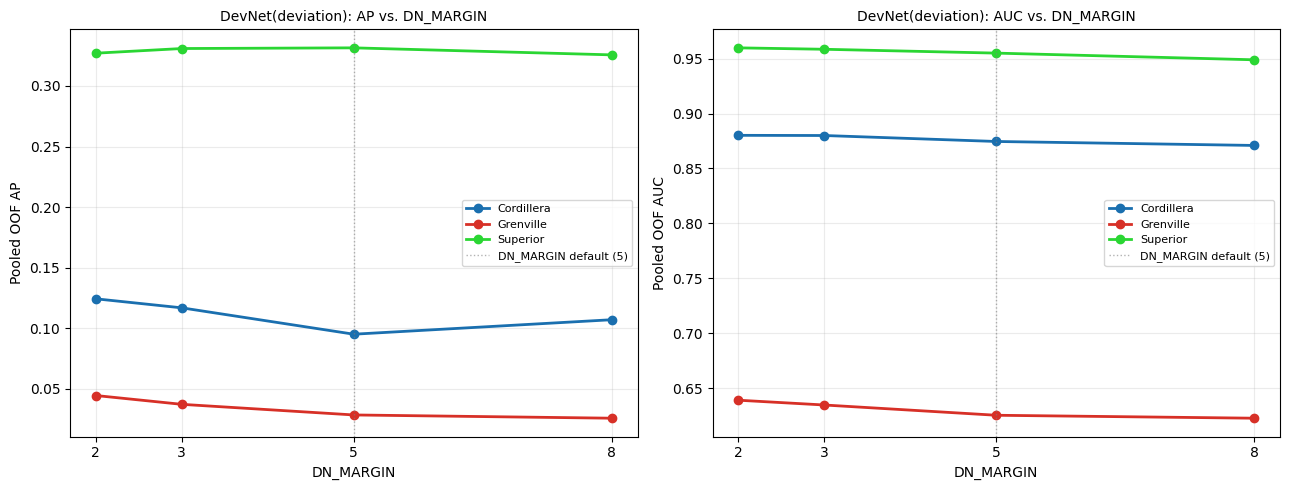

=== AP sensitivity to DN_MARGIN (max - min per region, across margin in [2, 3, 5, 8]) ===
  [Cordillera] AP range: 0.095 (margin=5)  -  0.124 (margin=2)   Δ=0.029
  [Grenville] AP range: 0.026 (margin=8)  -  0.044 (margin=2)   Δ=0.019
  [Superior] AP range: 0.326 (margin=8)  -  0.332 (margin=5)   Δ=0.006


In [21]:
_REGION_COLORS = {'Cordillera': '#1a6faf', 'Superior': '#2ad633', 'Grenville': '#d73027'}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in RUN_REGIONS:
    sub = margin_ablation_df[margin_ablation_df['region'] == name].sort_values('margin')
    c = _REGION_COLORS.get(name)
    axes[0].plot(sub['margin'], sub['oof_ap'],  marker='o', color=c, lw=2, label=name)
    axes[1].plot(sub['margin'], sub['oof_auc'], marker='o', color=c, lw=2, label=name)

axes[0].axvline(5, color='grey', ls=':', lw=1, alpha=0.6, label='DN_MARGIN default (5)')
axes[0].set_xlabel('DN_MARGIN'); axes[0].set_ylabel('Pooled OOF AP')
axes[0].set_title('DevNet(deviation): AP vs. DN_MARGIN', fontsize=10)
axes[0].set_xticks(DN_MARGIN_ABLATION_VALUES)
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.25); axes[0].set_axisbelow(True)

axes[1].axvline(5, color='grey', ls=':', lw=1, alpha=0.6, label='DN_MARGIN default (5)')
axes[1].set_xlabel('DN_MARGIN'); axes[1].set_ylabel('Pooled OOF AUC')
axes[1].set_title('DevNet(deviation): AUC vs. DN_MARGIN', fontsize=10)
axes[1].set_xticks(DN_MARGIN_ABLATION_VALUES)
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.25); axes[1].set_axisbelow(True)

plt.tight_layout(); plt.show()

print('=== AP sensitivity to DN_MARGIN (max - min per region, across margin in '
      f'{DN_MARGIN_ABLATION_VALUES}) ===')
for name in RUN_REGIONS:
    sub = margin_ablation_df[margin_ablation_df['region'] == name]
    ap_min, ap_max = sub['oof_ap'].min(), sub['oof_ap'].max()
    best_margin  = int(sub.loc[sub['oof_ap'].idxmax(), 'margin'])
    worst_margin = int(sub.loc[sub['oof_ap'].idxmin(), 'margin'])
    print(f'  [{name}] AP range: {ap_min:.3f} (margin={worst_margin})  -  '
          f'{ap_max:.3f} (margin={best_margin})   Δ={ap_max - ap_min:.3f}')

## 11c. Background-Sampling Sensitivity Analysis

**Theoretical basis:** Zuo, R. and Wang, J. (2020) identify the selection
of negative/unlabeled samples itself as a distinct source of uncertainty
in mineral prospectivity mapping, separate from model choice. Xiong, Y.
and Zuo, R. (2021) tested this with 10 random unlabeled-sampling repeats.

**What varies, what stays fixed:** only the background/unlabeled sampling
seed changes across the 5 draws below. The positive set is completely
fixed (same deposits, same dedup). Each draw independently redraws
`N_BACKGROUND` (eval_neg, affects RF -- RF is trained discriminatively
against `eval_neg`) and `N_UNLABELED` (train_unlabeled, affects
DevNet -- DevNet trains semi-supervised against `train_unlabeled`) as two
still-disjoint pools, so **both** models are exercised by the part of the
sampling process that actually touches them. Pruned feature set only, and
`REGION_FEATS[name]` (the main experiment's own collinearity-pruned list)
is reused as-is -- **not** recomputed per resample, to avoid introducing a
second variable alongside the sampling seed. A single `pooled_oof_eval`
(5-fold) is used per draw, not the repeated-CV protocol, to keep 5 draws
× 3 regions × 2 models affordable.

**Performance note:** feature extraction (proximity + raster + GLCM) for
the full A∧B-domain candidate pool is done **once per region** and
cached (`FULL_CANDIDATE_POOLS`, next cell). Every one of the 5 resamples
below only *selects different rows* from that cached, already-featured
table -- `add_glcm_features` is never called more than once per region.
Doing this per-resample instead would multiply the GLCM cost by 5.

**Mandatory reporting policy:** all 5 results are reported below --
table, per-region/model median/min/max summary, and a figure -- with
**no cherry-picking of the best run**. This is a deliberate departure
from Xiong & Zuo (2021), who report only the single highest-AUC run out
of 10 repeats; picking the best run inflates the reported performance,
which this analysis exists to avoid, not repeat.

In [22]:
BACKGROUND_SEEDS = [101, 102, 103, 104, 105]   # 5 independent sampling-seed draws;
                                                # distinct from RANDOM_SEED=42 used everywhere else


def build_full_candidate_pool_features(name, cfg, worm_trees):
    """Runs make_points + the SAME feature-extraction steps as build_region
    (terrane, line-feature proximity, point-feature proximity, rasters, GLCM), but
    WITHOUT build_region's N_BACKGROUND/N_UNLABELED subsampling -- returns
    ALL A∧B-domain candidates (label==-1) plus the positives (label==1),
    features already attached. Called ONCE per region (see the caching
    loop below); every seed in the sensitivity analysis then only
    resamples ROWS from this cached table -- add_glcm_features (the
    expensive step) is never called a second time for the same region.
    """
    rng = np.random.default_rng(RANDOM_SEED)   # unused inside make_points, kept for signature parity
    pts = make_points(cfg, rng, name)
    n_pos = int((pts['label'] == 1).sum())
    n_cand = int((pts['label'] == -1).sum())
    print(f'  [{name}] full A∧B candidate pool: {n_pos} positive, {n_cand} candidates')

    pts = add_terrane_h3(pts, CLIPPED_VECTORS[name].get('h3_grid'))
    pts = add_proximity_line_layers(pts, cfg['vectors'])
    pts = add_proximity_worms(pts, worm_trees)
    pts = add_rasters(pts, CLIPPED_RASTERS[name])
    print(f'  [{name}] extracting GLCM for the full candidate pool (one-time; every '
         f'resample below only selects rows from this table) ...')
    pts = add_glcm_features(pts, CLIPPED_RASTERS[name])

    raster_cols = list(CLIPPED_RASTERS[name].keys())
    pts = pts[pts[raster_cols].notna().any(axis=1)].reset_index(drop=True)
    return pts


FULL_CANDIDATE_POOLS = {}
for name in RUN_REGIONS:
    print(f'\n{"="*70}\n[{name}] one-time full-candidate-pool feature extraction\n{"="*70}')
    FULL_CANDIDATE_POOLS[name] = build_full_candidate_pool_features(name, REGIONS[name], WORM_TREES)



[Cordillera] one-time full-candidate-pool feature extraction
    'Lempriere' at (lat=52.4022, lon=-119.1383)
  Candidate grid: 22724 (>BUFFER_KM from any deposit) -> 16473 after A∧B sampleable-domain filter (72.5% kept)
  Positive: 27  |  Candidates: 16473
  [Cordillera] full A∧B candidate pool: 27 positive, 16473 candidates
  [Cordillera] extracting GLCM for the full candidate pool (one-time; every resample below only selects rows from this table) ...
    GLCM: Canada_BA → 4 texture features (nodata-aware)
    GLCM: Canada_BA_HP40km → 4 texture features (nodata-aware)
    GLCM: DRTP → 4 texture features (nodata-aware)
    GLCM: TMI → 4 texture features (nodata-aware)

[Grenville] one-time full-candidate-pool feature extraction
  All 12 positives confirmed inside the A∧B sampleable domain.
  Candidate grid: 8752 (>BUFFER_KM from any deposit) -> 8524 after A∧B sampleable-domain filter (97.4% kept)
  Positive: 12  |  Candidates: 8524
  [Grenville] full A∧B candidate pool: 12 positive, 8

In [23]:
def resample_background_pools(pts_full, seed):
    """Redraws N_BACKGROUND eval_neg + N_UNLABELED train_unlabeled (still
    disjoint) from the ALREADY-FEATURED full candidate pool `pts_full` --
    mirrors build_region's own disjoint-pool-construction block exactly
    (same select_negatives_random calls, same two-step disjointness
    logic), just parameterized by `seed` instead of hardcoded to
    RANDOM_SEED, and reading features from the cache instead of
    recomputing them. Only the sampling seed varies -- the positive set
    is completely fixed.
    """
    eval_tbl = select_negatives_random(pts_full, N_BACKGROUND, seed=seed)
    eval_neg_tbl = eval_tbl[eval_tbl['label'] == 0].reset_index(drop=True)

    cand_key = pd.MultiIndex.from_arrays([pts_full['lat'].values, pts_full['lon'].values])
    eval_key = pd.MultiIndex.from_arrays([eval_neg_tbl['lat'].values, eval_neg_tbl['lon'].values])
    is_eval_neg = pd.Series(cand_key.isin(eval_key), index=pts_full.index) & (pts_full['label'] == -1)
    pts_remaining = pts_full[(pts_full['label'] == 1) | ((pts_full['label'] == -1) & ~is_eval_neg)].reset_index(drop=True)

    unlabeled_tbl = select_negatives_random(pts_remaining, N_UNLABELED, seed=seed)
    unlabeled_neg_tbl = unlabeled_tbl[unlabeled_tbl['label'] == 0].reset_index(drop=True)

    pos_tbl = pts_full[pts_full['label'] == 1].reset_index(drop=True)
    pos_tbl = pos_tbl.copy();           pos_tbl['pool']           = 'positive'
    eval_neg_tbl = eval_neg_tbl.copy(); eval_neg_tbl['pool']      = 'eval_neg'
    unlabeled_neg_tbl = unlabeled_neg_tbl.copy(); unlabeled_neg_tbl['pool'] = 'train_unlabeled'
    return pd.concat([pos_tbl, eval_neg_tbl, unlabeled_neg_tbl], ignore_index=True)


bg_sensitivity_rows = []
for name in RUN_REGIONS:
    pts_full = FULL_CANDIDATE_POOLS[name]
    feat_cols = REGION_FEATS[name]              # fixed -- reused from the main experiment, never recomputed
    model_cfg = TRAINED[name]['model_cfg']

    print(f'\n{"="*70}\n[{name}] background-sampling sensitivity ({len(BACKGROUND_SEEDS)} reseeds)\n{"="*70}')
    for seed in BACKGROUND_SEEDS:
        pts_seed = resample_background_pools(pts_full, seed)
        pts_labeled   = pts_seed[pts_seed['pool'].isin(['positive', 'eval_neg'])].reset_index(drop=True)
        pts_unlabeled = pts_seed[pts_seed['pool'] == 'train_unlabeled'].reset_index(drop=True)

        X_lab,   y, _ = get_raw_features(pts_labeled,   feat_subset=feat_cols)
        X_unlab, _, _ = get_raw_features(pts_unlabeled, feat_subset=feat_cols)
        n_pos, n_eval = int((y == 1).sum()), int((y == 0).sum())
        print(f'  seed={seed}: positive={n_pos} eval_neg={n_eval} unlabeled={len(pts_unlabeled)}')

        rf_auc, rf_ap, _ = pooled_oof_eval(X_lab, y, rf_fold_scorer)
        dn_scorer = devnet_semisup_fold_scorer_factory(X_unlab, model_cfg=model_cfg)
        dn_auc, dn_ap, _ = pooled_oof_eval(X_lab, y, dn_scorer)
        print(f'    RF:                 AUC={rf_auc:.3f}  AP={rf_ap:.3f}')
        print(f'    DevNet(deviation):  AUC={dn_auc:.3f}  AP={dn_ap:.3f}')

        bg_sensitivity_rows.append({'region': name, 'model': 'RF', 'seed': seed,
                                    'oof_auc': rf_auc, 'oof_ap': rf_ap})
        bg_sensitivity_rows.append({'region': name, 'model': 'DevNet(deviation)', 'seed': seed,
                                    'oof_auc': dn_auc, 'oof_ap': dn_ap})

bg_sensitivity_df = pd.DataFrame(bg_sensitivity_rows)
print('\n=== Background-sampling sensitivity: all individual results (no cherry-picking) ===')
pd.set_option('display.width', 160)
print(bg_sensitivity_df.round(3).to_string(index=False))

bg_summary = bg_sensitivity_df.groupby(['region', 'model'])['oof_ap'].agg(
    median='median', min='min', max='max').reset_index()
print('\n=== Per-region/model AP summary across the 5 resamples ===')
print(bg_summary.round(3).to_string(index=False))



[Cordillera] background-sampling sensitivity (5 reseeds)
  random selection: kept 4000 / 16473 candidates
  random selection: kept 4000 / 12473 candidates
  seed=101: positive=27 eval_neg=4000 unlabeled=4000
    RF:                 AUC=0.931  AP=0.273
    DevNet(deviation):  AUC=0.876  AP=0.077
  random selection: kept 4000 / 16473 candidates
  random selection: kept 4000 / 12473 candidates
  seed=102: positive=27 eval_neg=4000 unlabeled=4000
    RF:                 AUC=0.929  AP=0.318
    DevNet(deviation):  AUC=0.879  AP=0.076
  random selection: kept 4000 / 16473 candidates
  random selection: kept 4000 / 12473 candidates
  seed=103: positive=27 eval_neg=4000 unlabeled=4000
    RF:                 AUC=0.934  AP=0.272
    DevNet(deviation):  AUC=0.881  AP=0.077
  random selection: kept 4000 / 16473 candidates
  random selection: kept 4000 / 12473 candidates
  seed=104: positive=27 eval_neg=4000 unlabeled=4000
    RF:                 AUC=0.910  AP=0.409
    DevNet(deviation):  AUC=0.

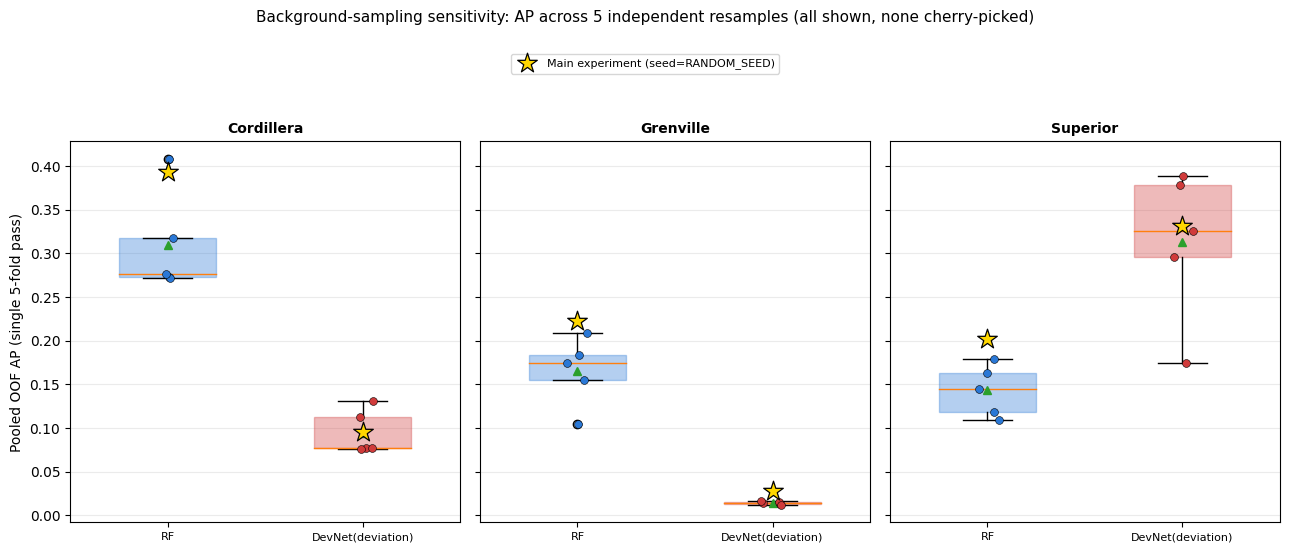


=== Mandatory reporting policy ===
All 5 resamples are reported above (table + summary + figure) -- none are cherry-picked.
This deliberately departs from Xiong & Zuo (2021)'s approach of reporting only the single highest-AUC run out of 10 repeats, which would inflate the reported performance.

=== Core question: is DevNet AP > RF AP in ALL 5 Superior background-sampling draws? ===
  seed=101: RF AP=0.109  DevNet AP=0.175  DevNet > RF: True
  seed=102: RF AP=0.118  DevNet AP=0.296  DevNet > RF: True
  seed=103: RF AP=0.163  DevNet AP=0.326  DevNet > RF: True
  seed=104: RF AP=0.179  DevNet AP=0.389  DevNet > RF: True
  seed=105: RF AP=0.145  DevNet AP=0.378  DevNet > RF: True

DevNet AP > RF AP in ALL 5 Superior resamples: True  (5/5)


In [24]:
def plot_bg_sensitivity(bg_sensitivity_df):
    """One panel per region: RF vs DevNet(deviation) AP distribution across
    the 5 background-sampling resamples (boxplot + individual seed
    points), with the main experiment's own pooled-OOF AP
    (RESULTS[name][model]['pruned']['oof_ap'], seed=RANDOM_SEED) overlaid
    as a gold-star reference -- so the spread here is judged against the
    number already reported in the comparison table, not in isolation.
    """
    colors = {'RF': '#2a78d6', 'DevNet(deviation)': '#d03b3b'}
    models = ['RF', 'DevNet(deviation)']
    fig, axes = plt.subplots(1, 3, figsize=(13, 4.8), sharey=True)
    rng_j = np.random.RandomState(0)

    for ax, name in zip(axes, RUN_REGIONS):
        data = [bg_sensitivity_df[(bg_sensitivity_df.region == name) &
                                  (bg_sensitivity_df.model == m)]['oof_ap'].values
               for m in models]
        bp = ax.boxplot(data, positions=[0, 1], widths=0.5, patch_artist=True,
                        showmeans=True, zorder=2)
        for i, box in enumerate(bp['boxes']):
            box.set(facecolor=colors[models[i]], alpha=0.35, edgecolor=colors[models[i]])

        for i, (m, vals) in enumerate(zip(models, data)):
            jitter = rng_j.uniform(-0.06, 0.06, size=len(vals))
            ax.scatter(np.full(len(vals), i) + jitter, vals, color=colors[m], s=32,
                      zorder=4, edgecolors='black', linewidths=0.4)
            main_ap = RESULTS[name][m]['pruned']['oof_ap']
            ax.scatter([i], [main_ap], marker='*', s=220, color='gold',
                      edgecolors='black', linewidths=0.9, zorder=5,
                      label='Main experiment (seed=RANDOM_SEED)' if i == 0 and name == RUN_REGIONS[0] else None)

        ax.set_xticks([0, 1]); ax.set_xticklabels(models, fontsize=8)
        ax.set_title(name, fontweight='bold', fontsize=10)
        ax.grid(axis='y', alpha=0.25); ax.set_axisbelow(True)
    axes[0].set_ylabel('Pooled OOF AP (single 5-fold pass)')

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', ncol=1, fontsize=8, bbox_to_anchor=(0.5, 1.06))
    fig.suptitle(f'Background-sampling sensitivity: AP across {len(BACKGROUND_SEEDS)} independent '
                f'resamples (all shown, none cherry-picked)', fontsize=11, y=1.14)
    plt.tight_layout()
    plt.show()


plot_bg_sensitivity(bg_sensitivity_df)

print('\n=== Mandatory reporting policy ===')
print('All 5 resamples are reported above (table + summary + figure) -- none are cherry-picked.')
print("This deliberately departs from Xiong & Zuo (2021)'s approach of reporting only the "
     "single highest-AUC run out of 10 repeats, which would inflate the reported performance.")

print('\n=== Core question: is DevNet AP > RF AP in ALL 5 Superior background-sampling draws? ===')
sup = bg_sensitivity_df[bg_sensitivity_df['region'] == 'Superior']
rf_sup = sup[sup['model'] == 'RF'].sort_values('seed').reset_index(drop=True)
dn_sup = sup[sup['model'] == 'DevNet(deviation)'].sort_values('seed').reset_index(drop=True)
comparison = dn_sup['oof_ap'].values > rf_sup['oof_ap'].values
for s, r, d, c in zip(rf_sup['seed'], rf_sup['oof_ap'], dn_sup['oof_ap'], comparison):
    print(f'  seed={s}: RF AP={r:.3f}  DevNet AP={d:.3f}  DevNet > RF: {c}')
print(f'\nDevNet AP > RF AP in ALL {len(BACKGROUND_SEEDS)} Superior resamples: '
     f'{bool(comparison.all())}  ({int(comparison.sum())}/{len(BACKGROUND_SEEDS)})')

## 11e. Cordillera Positive-Count Ablation — Small-Sample Regime (Repeated CV)

**Question:** as the number of available positives shrinks, does DevNet's
semi-supervised edge over RF grow? Since Section 9's shared-background-pool
design, RF and DevNet are both trained on the identical fixed
`train_unlabeled` background pool (RF labels it 0, DevNet leaves it
unlabeled) -- so BOTH models' background signal is fixed regardless of
positive count, and any AUC/AP gap that widens as positives shrink can be
attributed to the modeling paradigm itself, not to a difference in which
background points each model was trained on.

**Design:** Cordillera only, pruned feature set only. **Only the
positive set is subsampled** -- `eval_neg` and `train_unlabeled` are
reused byte-for-byte from the main experiment's own
`REGION_PTS['Cordillera']`, so the positive count is the sole variable
(not conflated with a different background draw, as in Section 11c). Both
models' fold-training uses `rf_shared_bg_fold_scorer_factory` /
`devnet_semisup_fold_scorer_factory` against the SAME `train_unlabeled`
pool, matching Section 9's design exactly -- only the labels differ. For
each positive-count level below the full set, 5 independent random
subsamples are drawn; each subsample is evaluated with repeated CV via
`repeated_pooled_auc_ap`, so both AUC and AP have a per-subsample
distribution rather than a single point -- every individual repeat value
is stored and reported, none cherry-picked. The floor is 5 positives,
since `StratifiedKFold(n_splits=CV_N_SPLITS=5)` needs at least one
positive per fold.

`POS_ABLATION_CV_REPEATS` / `POS_ABLATION_DN_RESTARTS` / `POS_ABLATION_REPEATS`
are speed knobs local to this ablation (main experiment untouched); lowering
`POS_ABLATION_REPEATS` (the number of random positive-subsamples drawn per
level) trades away some of the "don't cherry-pick a lucky small-N draw"
protection this ablation is specifically about.

The self-check below re-runs a single-pass `pooled_oof_eval` at the main
experiment's own settings (default `restarts`, one 5-fold pass,
`rf_shared_bg_fold_scorer_factory` for RF) to confirm the reused
`eval_neg`/`train_unlabeled` pools and scorer construction are
byte-identical to Section 9's -- it is expected to match exactly regardless
of how the sweep below is tuned for speed.


[Cordillera] full positive count = 27  |  eval_neg = 3000  |  train_unlabeled = 5000  (background pools held FIXED throughout)
Positive-count levels: [27, 20, 15, 10, 7, 5]  |  subsamples per non-full level: 5  |  CV: 5x3 repeated (main experiment uses 5x6)  |  DevNet restarts: 3 (main experiment uses 5)

--- n_pos=27 (full set, single deterministic subsample) ---
  rep=0 seed=full: RF AUC=0.918 AP=0.395  |  DevNet AUC=0.871 AP=0.119

--- n_pos=20 (5 random subsamples) ---
  rep=0 seed=4001: RF AUC=0.850 AP=0.134  |  DevNet AUC=0.813 AP=0.066
  rep=1 seed=4002: RF AUC=0.836 AP=0.295  |  DevNet AUC=0.846 AP=0.136
  rep=2 seed=4003: RF AUC=0.880 AP=0.178  |  DevNet AUC=0.888 AP=0.081
  rep=3 seed=4004: RF AUC=0.909 AP=0.295  |  DevNet AUC=0.881 AP=0.150
  rep=4 seed=4005: RF AUC=0.920 AP=0.376  |  DevNet AUC=0.891 AP=0.086

--- n_pos=15 (5 random subsamples) ---
  rep=0 seed=3501: RF AUC=0.848 AP=0.043  |  DevNet AUC=0.755 AP=0.033
  rep=1 seed=3502: RF AUC=0.841 AP=0.230  |  DevNet AUC=

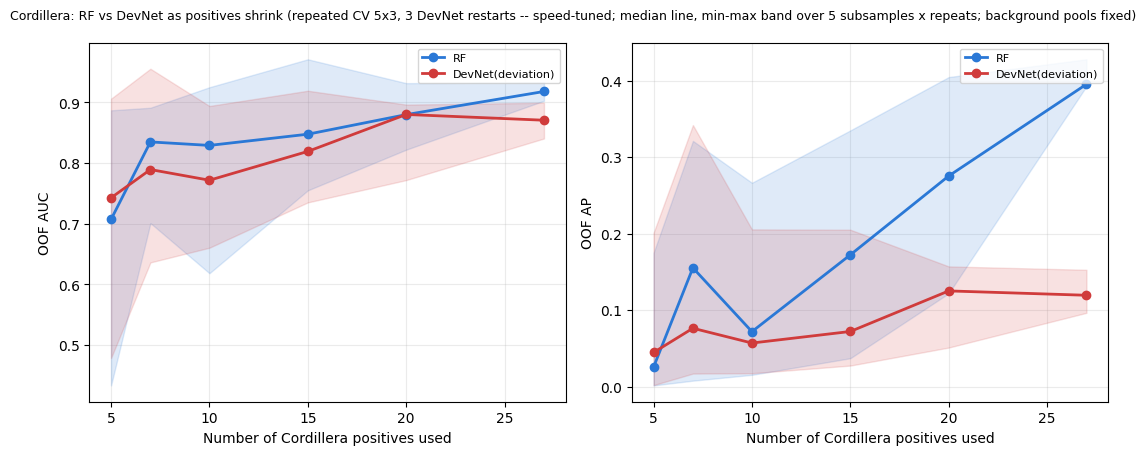

In [25]:
# ══════════════════════════════════════════════════════════════════════════
#  Cordillera positive-count ablation — REPEATED-CV version (speed-tuned)
#  Each (n_pos, subsample) is evaluated with repeated CV
#  (CV_N_SPLITS x POS_ABLATION_CV_REPEATS), returning BOTH AUC and AP
#  distributions. POS_ABLATION_CV_REPEATS / POS_ABLATION_DN_RESTARTS are
#  LOCAL overrides -- CV_N_REPEATS / DN_RESTARTS (used everywhere else in
#  the notebook) are untouched.
# ══════════════════════════════════════════════════════════════════════════

CORD_NAME   = 'Cordillera'
pts_cord    = REGION_PTS[CORD_NAME]
feat_cols   = REGION_FEATS[CORD_NAME]
model_cfg   = TRAINED[CORD_NAME]['model_cfg']

pos_full_tbl  = pts_cord[pts_cord['pool'] == 'positive'].reset_index(drop=True)
eval_neg_tbl  = pts_cord[pts_cord['pool'] == 'eval_neg'].reset_index(drop=True)
unlabeled_tbl = pts_cord[pts_cord['pool'] == 'train_unlabeled'].reset_index(drop=True)
N_POS_FULL = len(pos_full_tbl)
print(f'[{CORD_NAME}] full positive count = {N_POS_FULL}  |  eval_neg = {len(eval_neg_tbl)}  |  '
     f'train_unlabeled = {len(unlabeled_tbl)}  (background pools held FIXED throughout)')

N_POS_ABLATION_TARGETS = sorted(
    {n for n in [N_POS_FULL, 20, 15, 10, 7, 5] if CV_N_SPLITS <= n <= N_POS_FULL}, reverse=True)
POS_ABLATION_REPEATS     = 5     # random-subsample repeats per (non-full) level
POS_ABLATION_SEED0       = 2001
POS_ABLATION_CV_REPEATS  = 3     # LOCAL override of CV_N_REPEATS (6) -- speed only
POS_ABLATION_DN_RESTARTS = 3     # LOCAL override of DN_RESTARTS (5) -- speed only
print(f'Positive-count levels: {N_POS_ABLATION_TARGETS}  |  subsamples per non-full level: '
     f'{POS_ABLATION_REPEATS}  |  CV: {CV_N_SPLITS}x{POS_ABLATION_CV_REPEATS} repeated '
     f'(main experiment uses {CV_N_SPLITS}x{CV_N_REPEATS})  |  DevNet restarts: '
     f'{POS_ABLATION_DN_RESTARTS} (main experiment uses {DN_RESTARTS})')

# RF/DevNet shared background pool + scorers are independent of positive
# count -> build once. RF now uses rf_shared_bg_fold_scorer_factory (Section
# 9's design) instead of the plain rf_fold_scorer, so it is trained on the
# same fixed train_unlabeled pool as DevNet (labeled 0), matching how
# RESULTS[CORD_NAME]['RF'] was itself produced.
X_unlab, _, _ = get_raw_features(unlabeled_tbl, feat_subset=feat_cols)
rf_scorer_cord = rf_shared_bg_fold_scorer_factory(X_unlab)
dn_scorer_cord = devnet_semisup_fold_scorer_factory(
    X_unlab, model_cfg=model_cfg, restarts=POS_ABLATION_DN_RESTARTS)


def repeated_pooled_auc_ap(X_raw, y, fold_scorer, n_splits=CV_N_SPLITS,
                           n_repeats=POS_ABLATION_CV_REPEATS, seed=RANDOM_SEED):
    """Like repeated_pooled_auc but returns BOTH per-repeat pooled AUC and AP.
    Returns (aucs, aps), each an array of length n_repeats.
    """
    rskf = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=seed)
    n = len(y)
    aucs, aps = [], []
    oof_rank = np.full(n, np.nan)
    counter = 0
    for k, (tr_idx, va_idx) in enumerate(rskf.split(X_raw, y)):
        if k > 0 and k % n_splits == 0:
            aucs.append(roc_auc_score(y, oof_rank))
            aps.append(average_precision_score(y, oof_rank))
            oof_rank = np.full(n, np.nan)
        va_scores = fold_scorer(X_raw[tr_idx], y[tr_idx], X_raw[va_idx], seed_counter=counter)
        oof_rank[va_idx] = rankdata(va_scores) / len(va_scores)
        counter += 1
    aucs.append(roc_auc_score(y, oof_rank))
    aps.append(average_precision_score(y, oof_rank))
    return np.array(aucs), np.array(aps)


pos_ablation_rows = []
for n_pos in N_POS_ABLATION_TARGETS:
    is_full   = (n_pos == N_POS_FULL)
    n_subsamp = 1 if is_full else POS_ABLATION_REPEATS
    print(f'\n--- n_pos={n_pos} '
         f'({"full set, single deterministic subsample" if is_full else f"{n_subsamp} random subsamples"}) ---')
    for rep in range(n_subsamp):
        if is_full:
            pos_sub, seed_tag = pos_full_tbl, 'full'
        else:
            seed = POS_ABLATION_SEED0 + n_pos * 100 + rep
            idx = np.random.RandomState(seed).choice(N_POS_FULL, size=n_pos, replace=False)
            pos_sub, seed_tag = pos_full_tbl.iloc[idx].reset_index(drop=True), seed

        pts_labeled = pd.concat([pos_sub, eval_neg_tbl], ignore_index=True)
        X_lab, y, _ = get_raw_features(pts_labeled, feat_subset=feat_cols)

        # repeated CV (speed-tuned via POS_ABLATION_CV_REPEATS/DN_RESTARTS above)
        rf_aucs, rf_aps = repeated_pooled_auc_ap(X_lab, y, rf_scorer_cord)
        dn_aucs, dn_aps = repeated_pooled_auc_ap(X_lab, y, dn_scorer_cord)

        print(f'  rep={rep} seed={seed_tag}: '
             f'RF AUC={np.median(rf_aucs):.3f} AP={np.median(rf_aps):.3f}  |  '
             f'DevNet AUC={np.median(dn_aucs):.3f} AP={np.median(dn_aps):.3f}')

        # store EVERY per-repeat value (no aggregation yet -> no cherry-picking)
        for r_auc, r_ap in zip(rf_aucs, rf_aps):
            pos_ablation_rows.append({'n_pos': n_pos, 'is_full': is_full, 'subsample': rep,
                                      'model': 'RF', 'oof_auc': r_auc, 'oof_ap': r_ap})
        for d_auc, d_ap in zip(dn_aucs, dn_aps):
            pos_ablation_rows.append({'n_pos': n_pos, 'is_full': is_full, 'subsample': rep,
                                      'model': 'DevNet(deviation)', 'oof_auc': d_auc, 'oof_ap': d_ap})

pos_ablation_df = pd.DataFrame(pos_ablation_rows)


# ── Self-check: independent of the speed knobs above -- re-runs a single-pass
#    pooled_oof_eval at the MAIN experiment's own settings (default restarts,
#    one 5-fold pass) purely to confirm eval_neg/train_unlabeled were reused
#    byte-identical to Section 9. Always expected to match exactly. ──────────
print("\n=== Self-check: full positive set + reused pools reproduce Section 9's Cordillera pruned result ===")
pts_labeled_full = pd.concat([pos_full_tbl, eval_neg_tbl], ignore_index=True)
X_lab_full, y_full, _ = get_raw_features(pts_labeled_full, feat_subset=feat_cols)
check_rf_auc, _, _ = pooled_oof_eval(X_lab_full, y_full, rf_scorer_cord)
check_dn_auc, _, _ = pooled_oof_eval(X_lab_full, y_full,
                                     devnet_semisup_fold_scorer_factory(X_unlab, model_cfg=model_cfg))
ref_rf_auc = RESULTS[CORD_NAME]['RF']['pruned']['oof_auc']
ref_dn_auc = RESULTS[CORD_NAME]['DevNet(deviation)']['pruned']['oof_auc']
print(f'  RF     single-pass AUC: check={check_rf_auc:.4f}  vs  Section 9={ref_rf_auc:.4f}')
print(f'  DevNet single-pass AUC: check={check_dn_auc:.4f}  vs  Section 9={ref_dn_auc:.4f}')
if not (np.isclose(check_rf_auc, ref_rf_auc, atol=1e-9) and np.isclose(check_dn_auc, ref_dn_auc, atol=1e-9)):
    raise RuntimeError('Positive-count ablation does not reproduce Section 9 at the full-set level -- '
                       'check that eval_neg/train_unlabeled pools were reused unchanged.')
print('  OK -- matches exactly.')


# ── Summary table: median [min, max] over all subsamples x CV repeats, per n_pos x model ──
print('\n=== Median [min, max] over all subsamples x CV repeats (no cherry-picking) ===')
summary = (pos_ablation_df
          .groupby(['n_pos', 'model'])
          .agg(auc_med=('oof_auc', 'median'), auc_lo=('oof_auc', 'min'), auc_hi=('oof_auc', 'max'),
               ap_med =('oof_ap',  'median'), ap_lo =('oof_ap',  'min'), ap_hi =('oof_ap',  'max'))
          .reset_index()
          .sort_values(['n_pos', 'model'], ascending=[False, True]))
pd.set_option('display.width', 170)
print(summary.round(4).to_string(index=False))

# ── AUC crossover + AP variance report ──
print('\n=== Key read-outs ===')
piv_auc = summary.pivot(index='n_pos', columns='model', values='auc_med').sort_index(ascending=False)
cross = None
prev = None
for n_pos in piv_auc.index:
    rf_a, dn_a = piv_auc.loc[n_pos, 'RF'], piv_auc.loc[n_pos, 'DevNet(deviation)']
    lead = 'DevNet' if dn_a > rf_a else 'RF'
    if prev is not None and lead != prev:
        cross = n_pos
    prev = lead
print(f'  AUC leader by n_pos (high->low): '
     + ', '.join(f'{n}:{("DevNet" if piv_auc.loc[n,"DevNet(deviation)"]>piv_auc.loc[n,"RF"] else "RF")}'
                 for n in piv_auc.index))
print(f'  -> AUC crossover at n_pos = {cross}' if cross else '  -> no AUC crossover observed')

print('  AP spread (max-min) by n_pos, DevNet / RF:')
for n_pos in piv_auc.index:
    d = summary[(summary.n_pos == n_pos) & (summary.model == 'DevNet(deviation)')]
    r = summary[(summary.n_pos == n_pos) & (summary.model == 'RF')]
    dsp = float(d['ap_hi'].iloc[0] - d['ap_lo'].iloc[0])
    rsp = float(r['ap_hi'].iloc[0] - r['ap_lo'].iloc[0])
    print(f'    n_pos={n_pos:2d}:  DevNet spread={dsp:.3f}   RF spread={rsp:.3f}')


# ── Plot: AUC (left) and AP (right), median line + min-max band ──
def plot_pos_ablation(summary):
    colors = {'RF': '#2a78d6', 'DevNet(deviation)': '#d03b3b'}
    models = ['RF', 'DevNet(deviation)']
    levels = sorted(summary['n_pos'].unique())
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
    for (metric, mlo, mhi), ax in zip(
            [('auc_med', 'auc_lo', 'auc_hi'), ('ap_med', 'ap_lo', 'ap_hi')], axes):
        for m in models:
            s = summary[summary.model == m].set_index('n_pos').loc[levels]
            ax.plot(levels, s[metric], color=colors[m], lw=2, marker='o', label=m)
            ax.fill_between(levels, s[mlo], s[mhi], color=colors[m], alpha=0.15)
        ax.set_xlabel('Number of Cordillera positives used')
        ax.set_ylabel('OOF ' + ('AUC' if 'auc' in metric else 'AP'))
        ax.grid(alpha=0.25); ax.set_axisbelow(True); ax.legend(fontsize=8)
    fig.suptitle(f'{CORD_NAME}: RF vs DevNet as positives shrink '
                f'(repeated CV {CV_N_SPLITS}x{POS_ABLATION_CV_REPEATS}, {POS_ABLATION_DN_RESTARTS} DevNet '
                f'restarts -- speed-tuned; median line, min-max band over {POS_ABLATION_REPEATS} '
                f'subsamples x repeats; background pools fixed)', fontsize=9)
    plt.tight_layout(); plt.show()

plot_pos_ablation(summary)

## 12. Prediction Map

DevNet's panel is labeled "semi-supervised" so the two panels' data
paradigms are visible at a glance, and marks each region's top
`TOP_N_TARGETS` scored unlabeled points (`TRAINED[name]['top_targets']`) as
candidate new targets, distinct from the known-deposit markers both panels
already show. Both panels score the grid using `TRAINED[name]['feat_cols']`
(the region's pruned feature set), so training and the prediction map are
never on different feature sets.


In [26]:
from scipy.interpolate import griddata as _griddata
from rasterio.transform import Affine as _Affine
from rasterio.transform import rowcol as _rowcol
from rasterio.features import geometry_mask as _geomask
from pyproj import Transformer as _Transformer
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches

_PROSP_COLORS = ["#1a6faf", "#42c4e8", "#f5e21a", "#d73027"]

# Known-deposit confidence: same ordinal scale/colors as
# cordilleran_positive_dedup.ipynb's dep_type map -- dark = most confirmed.
# cfg['dep'] here is the combined+deduped CSV, which already carries a
# dep_type column (Deposit/Prospect / Showing / Occurrence); falls back to
# 'Unknown' (grey) if a dep source without that column is ever swapped in.
DEP_TYPE_ORDER = ['Deposit/Prospect', 'Showing', 'Occurrence']
COLOR_DEP_TYPE = {
    'Deposit/Prospect': "#811010",
    'Showing':          "#2ad633",
    'Occurrence':       '#86b6ef',
    'Unknown':          '#898781',
}

# ── True-scale cartography (fixed 1:20,000,000 across every region) ────────
MAP_SCALE_DENOM = 20_000_000   # 1:20,000,000, fixed across all regions/panels
_INCH_M = 0.0254               # metres per inch


def _true_scale_size_in(extent_m, scale_denom=MAP_SCALE_DENOM):
    """Physical panel size (inches) for a ground extent (metres) at a fixed
    map scale -- 1 inch of paper == scale_denom inches == scale_denom *
    _INCH_M metres of ground."""
    return extent_m / (scale_denom * _INCH_M)


def _draw_bnd(ax, bnd_proj):
    """Draw boundary without triggering geopandas autoscale."""
    for geom in bnd_proj.geometry:
        polys = [geom] if geom.geom_type == 'Polygon' else list(geom.geoms)
        for poly in polys:
            xs, ys = poly.exterior.xy
            ax.plot(xs, ys, 'k-', lw=1.2, zorder=3)


_LONLAT_TO_PROJ = _Transformer.from_crs('EPSG:4326', PROJECTED_CRS, always_xy=True)
_PROJ_TO_LONLAT = _Transformer.from_crs(PROJECTED_CRS, 'EPSG:4326', always_xy=True)


def _draw_graticule(ax, lon_step=10, lat_step=10, n_seg=60):
    """Lat/lon graticule with edge-degree labels, drawn directly in the
    axes' PROJECTED_CRS (EPSG:3978) data coordinates."""
    bx0, bx1 = ax.get_xlim()
    by0, by1 = ax.get_ylim()

    corner_x = [bx0, bx1, bx0, bx1, (bx0 + bx1) / 2, (bx0 + bx1) / 2, bx0, bx1]
    corner_y = [by0, by0, by1, by1, by0, by1, (by0 + by1) / 2, (by0 + by1) / 2]
    lons, lats = _PROJ_TO_LONLAT.transform(corner_x, corner_y)
    lon_min, lon_max = min(lons), max(lons)
    lat_min, lat_max = min(lats), max(lats)

    lon_lines = np.arange(np.ceil(lon_min / lon_step) * lon_step, lon_max + lon_step, lon_step)
    lat_lines = np.arange(np.ceil(lat_min / lat_step) * lat_step, lat_max + lat_step, lat_step)

    for lon in lon_lines:
        lat_seg = np.linspace(lat_min - lat_step, lat_max + lat_step, n_seg)
        xs, ys = _LONLAT_TO_PROJ.transform(np.full(n_seg, lon), lat_seg)
        xs, ys = np.asarray(xs), np.asarray(ys)
        ax.plot(xs, ys, color='grey', lw=0.5, ls=':', alpha=0.55, zorder=2)
        j = np.argmin(np.abs(ys - by1))
        if bx0 <= xs[j] <= bx1:
            ax.text(xs[j], by1, f'{lon:.0f}\xb0', ha='center', va='bottom',
                   fontsize=7, color='#333333', clip_on=False)

    for lat in lat_lines:
        lon_seg = np.linspace(lon_min - lon_step, lon_max + lon_step, n_seg)
        xs, ys = _LONLAT_TO_PROJ.transform(lon_seg, np.full(n_seg, lat))
        xs, ys = np.asarray(xs), np.asarray(ys)
        ax.plot(xs, ys, color='grey', lw=0.5, ls=':', alpha=0.55, zorder=2)
        i = np.argmin(np.abs(xs - bx0))
        if by0 <= ys[i] <= by1:
            ax.text(bx0, ys[i], f'{lat:.0f}\xb0', ha='right', va='center',
                   fontsize=7, color='#333333', clip_on=False)


def _draw_north_arrow(ax, xy_frac=(0.93, 0.90), size_frac=0.07):
    """Simple annotate-based north arrow, positioned in axes-fraction
    coordinates so it stays in the same relative corner."""
    x, y = xy_frac
    ax.annotate('N', xy=(x, y), xytext=(x, y - size_frac),
               xycoords='axes fraction', textcoords='axes fraction',
               ha='center', va='center', fontsize=11, fontweight='bold', zorder=9,
               arrowprops=dict(facecolor='black', edgecolor='black', width=3.5,
                              headwidth=11, headlength=9, shrink=0.02))


def _draw_scale_bar(ax, length_km=500, x_frac=0.55, y_frac=0.06):
    """Graphic scale bar drawn in DATA coordinates (metres), so its length is
    a true fraction of the axes' real-world extent."""
    bx0, bx1 = ax.get_xlim()
    by0, by1 = ax.get_ylim()
    length_m = length_km * 1000.0
    x0 = bx0 + x_frac * (bx1 - bx0)
    y0 = by0 + y_frac * (by1 - by0)
    tick_h = (by1 - by0) * 0.012
    ax.plot([x0, x0 + length_m], [y0, y0], color='black', lw=2.2,
           solid_capstyle='butt', zorder=8)
    for xt in (x0, x0 + length_m / 2, x0 + length_m):
        ax.plot([xt, xt], [y0 - tick_h, y0 + tick_h], color='black', lw=1.4, zorder=8)
    ax.text(x0 + length_m / 2, y0 + tick_h * 2.2, f'{length_km} km',
           ha='center', va='bottom', fontsize=8, zorder=8)


def _draw_study_area_label(ax, name, x_frac=0.03, y_frac=0.03):
    ax.text(x_frac, y_frac, f'Study Area: {name}', transform=ax.transAxes,
           fontsize=9, ha='left', va='bottom', zorder=9,
           bbox=dict(facecolor='white', edgecolor='#999999', alpha=0.85, boxstyle='round,pad=0.3'))


def _sampleable_grid_mask(name, Xi, Yi):
    """Boolean mask, same shape as Xi/Yi, True where the plotting-grid cell
    falls inside region `name`'s A∧B sampleable domain (Section 3h)."""
    info = SAMPLEABLE[name]
    ref_tf, ref_shape, mask = info['ref_tf'], info['ref_shape'], info['sampleable']
    rows, cols = _rowcol(ref_tf, Xi.ravel(), Yi.ravel())
    rows = np.asarray(rows).reshape(Xi.shape)
    cols = np.asarray(cols).reshape(Xi.shape)
    H, W = ref_shape
    in_bounds = (rows >= 0) & (rows < H) & (cols >= 0) & (cols < W)
    out = np.zeros(Xi.shape, dtype=bool)
    out[in_bounds] = mask[rows[in_bounds], cols[in_bounds]]
    return out


def _prosp_panel(ax, proba, xs_p, ys_p, bnd_proj, dep_proj, model_name, name,
                 extra_pts_proj=None, extra_label='Potential target',
                 show_title=True):
    """P90/P95/P99 upper-tail classification panel. When show_title is False
    the per-axes title is suppressed (the figure-level title is used instead,
    to avoid mis-centring over a narrow single-column panel)."""
    valid = proba[np.isfinite(proba)]

    bx0, by0, bx1, by1 = bnd_proj.total_bounds
    res = 5000

    y_range = np.arange(by1, by0, -res)
    x_range = np.arange(bx0, bx1,  res)
    Xi, Yi  = np.meshgrid(x_range, y_range)

    Z   = _griddata(np.column_stack([xs_p, ys_p]), proba, (Xi, Yi), method='linear')
    tfm = _Affine.translation(bx0, by1) * _Affine.scale(res, -res)
    outline_msk    = _geomask(bnd_proj.geometry, out_shape=Z.shape, transform=tfm, invert=True)
    sampleable_msk = _sampleable_grid_mask(name, Xi, Yi)
    msk = outline_msk & sampleable_msk
    Z   = np.where(msk, Z, np.nan)

    ext  = [bx0, bx1, by0, by1]
    bks  = [0.0,
            float(np.percentile(valid, 90)),
            float(np.percentile(valid, 95)),
            float(np.percentile(valid, 99)), 1.0]
    cmap = mcolors.ListedColormap(_PROSP_COLORS)
    norm = mcolors.BoundaryNorm(bks, len(_PROSP_COLORS))

    ax.imshow(np.ma.masked_invalid(Z), extent=ext, origin='upper',
              cmap=cmap, norm=norm, aspect='equal', zorder=1)
    ax.set_xlim(bx0, bx1); ax.set_ylim(by0, by1)
    ax.set_aspect('equal')
    _draw_bnd(ax, bnd_proj)
    _draw_graticule(ax)
    dep_type_vals = (dep_proj['dep_type'].fillna('Unknown').values
                     if 'dep_type' in dep_proj.columns
                     else np.array(['Unknown'] * len(dep_proj)))
    dep_types_present = []
    for _t in DEP_TYPE_ORDER + ['Unknown']:
        _sub = dep_proj[dep_type_vals == _t]
        if len(_sub) == 0:
            continue
        ax.scatter(_sub.geometry.x, _sub.geometry.y,
                   c=COLOR_DEP_TYPE.get(_t, '#898781'), s=130, marker='*', alpha=0.85,
                   zorder=5, linewidths=0.5, edgecolors='black')
        dep_types_present.append((_t, len(_sub)))
    if extra_pts_proj is not None and len(extra_pts_proj) > 0:
        ax.scatter(extra_pts_proj.geometry.x, extra_pts_proj.geometry.y,
                   facecolors='none', edgecolors='#eda100', s=200, marker='D',
                   linewidths=2.0, zorder=6)

    _PRIORITY_LABELS = ['Background (lower 90%)',
                        'Priority 3 — top 10% of area',
                        'Priority 2 — top 5% of area',
                        'Priority 1 — top 1% of area']
    patches = [mpatches.Patch(facecolor=_PROSP_COLORS[i], edgecolor='grey', lw=0.5,
               label=_PRIORITY_LABELS[i])
               for i in range(4)]
    for _t, _n in dep_types_present:
        patches.append(plt.Line2D([0], [0], marker='*', color='w',
                                   markerfacecolor=COLOR_DEP_TYPE.get(_t, '#898781'),
                                   markeredgecolor='black', markeredgewidth=0.5,
                                   markersize=11, alpha=0.85, label=f'Known REE: {_t} (n={_n})'))
    if extra_pts_proj is not None and len(extra_pts_proj) > 0:
        patches.append(plt.Line2D([0], [0], marker='D', color='w',
                                   markerfacecolor='none', markeredgecolor='#eda100',
                                   markeredgewidth=2.0, markersize=10,
                                   alpha=0.9, label=extra_label))
    # Legend OUTSIDE the axes (to the right); the figure reserves LEGEND_W_IN
    # of width for exactly this, so it never overlaps the map.
    ax.legend(handles=patches, loc='upper left', bbox_to_anchor=(1.02, 1.0),
              bbox_transform=ax.transAxes, fontsize=8, title='Legend',
              title_fontsize=9, framealpha=0.9, borderaxespad=0.)
    if show_title:
        ax.set_title(model_name, fontsize=11, fontweight='bold')
    ax.set_xticks([]); ax.set_yticks([])   # graticule replaces metre-based ticks
    ax.set_xlim(bx0, bx1); ax.set_ylim(by0, by1)

    _draw_north_arrow(ax)
    _draw_scale_bar(ax)
    _draw_study_area_label(ax, name)


def _make_prosp_figure(proba, xs_p, ys_p, bnd_proj, dep_in, name,
                       model_short, model_desc,
                       extra_pts_proj=None, extra_label='Potential target'):
    """Build ONE standalone, true-scale prospectivity figure: a single map
    with its legend to the right and a clean three-tier title block. The
    panel is sized in real inches by _true_scale_size_in, so the fixed
    1:MAP_SCALE_DENOM scale is unchanged from the old combined layout."""
    bx0, by0, bx1, by1 = bnd_proj.total_bounds
    panel_w_in = _true_scale_size_in(bx1 - bx0)
    panel_h_in = _true_scale_size_in(by1 - by0)

    LEFT_MARGIN_IN, LEGEND_W_IN, RIGHT_PAD_IN = 0.6, 2.6, 0.25
    TOP_MARGIN_IN, BOTTOM_MARGIN_IN = 1.2, 0.35

    fig_w_in = LEFT_MARGIN_IN + panel_w_in + LEGEND_W_IN + RIGHT_PAD_IN
    fig_h_in = TOP_MARGIN_IN + panel_h_in + BOTTOM_MARGIN_IN

    fig = plt.figure(figsize=(fig_w_in, fig_h_in))

    ax_left   = LEFT_MARGIN_IN / fig_w_in
    ax_bottom = BOTTOM_MARGIN_IN / fig_h_in
    ax_w      = panel_w_in / fig_w_in
    ax_h      = panel_h_in / fig_h_in
    ax = fig.add_axes([ax_left, ax_bottom, ax_w, ax_h])

    # Title centred over the MAP only (the legend occupies the right side).
    title_x = ax_left + ax_w / 2.0
    fig.text(title_x, 1 - 0.30 / fig_h_in, f'{name} — {model_short}',
             ha='center', va='top', fontsize=13, fontweight='bold')
    fig.text(title_x, 1 - 0.62 / fig_h_in,
             f'REE Prospectivity  ·  EPSG:3978  ·  1:{MAP_SCALE_DENOM:,}',
             ha='center', va='top', fontsize=8.5, color='#444444')
    fig.text(title_x, 1 - 0.83 / fig_h_in, model_desc,
             ha='center', va='top', fontsize=7.5, color='#666666', style='italic')

    _prosp_panel(ax, proba, xs_p, ys_p, bnd_proj, dep_in, model_short, name,
                 extra_pts_proj=extra_pts_proj, extra_label=extra_label,
                 show_title=False)
    return fig


def build_grid(cfg, name):
    """Regular prediction grid within the study area (EPSG:4326), restricted
    to the A∧B sampleable domain (SAMPLEABLE[name], Section 3h)."""
    boundary   = gpd.read_file(cfg['outline']).to_crs('EPSG:4326')
    study_area = boundary.unary_union
    xmin, ymin, xmax, ymax = boundary.total_bounds
    xs = np.arange(xmin, xmax, GRID_DEG)
    ys = np.arange(ymin, ymax, GRID_DEG)
    xx, yy = np.meshgrid(xs, ys)
    gdf = gpd.GeoDataFrame(
        geometry=gpd.points_from_xy(xx.ravel(), yy.ravel()), crs='EPSG:4326')
    gdf = gdf[gdf.within(study_area)].copy()
    gdf['lat'] = gdf.geometry.y
    gdf['lon'] = gdf.geometry.x

    n_before = len(gdf)
    in_dom = sampleable_lookup(gdf['lat'].values, gdf['lon'].values, name)
    gdf = gdf[in_dom].reset_index(drop=True)
    print(f'  [{name}] prediction grid: {n_before} (within outline) -> {len(gdf)} '
          f'after A∧B sampleable-domain filter ({len(gdf)/n_before*100:.1f}% kept)')
    return gdf, boundary


def predict_grid(cfg, name, rf_model, rf_scaler, rf_imputer, feat_cols,
                 dn_ensemble, dn_scaler, dn_imputer, worm_trees, top_targets=None):
    print(f'[{name}] building prediction grid ...')
    grid, boundary = build_grid(cfg, name)

    pts = pd.DataFrame({'lat': grid['lat'], 'lon': grid['lon']})
    pts = add_terrane_h3(pts, CLIPPED_VECTORS[name].get('h3_grid'))
    pts = add_proximity_line_layers(pts, cfg['vectors'])
    pts = add_proximity_worms(pts, worm_trees)
    pts = add_rasters(pts, CLIPPED_RASTERS[name])

    print(f'  extracting GLCM texture features for prediction grid ...')
    pts = add_glcm_features(pts, CLIPPED_RASTERS[name])

    X = pts.reindex(columns=feat_cols).astype(float).values

    X_rf     = rf_scaler.transform(rf_imputer.transform(X))
    rf_proba = rf_model.predict_proba(X_rf)[:, 1]

    X_dn = dn_scaler.transform(dn_imputer.transform(X))
    dn_proba = ensemble_score(dn_ensemble, X_dn)  # rank-averaged ensemble, already ~[0, 1]

    if top_targets is not None and len(top_targets) > 0:
        print(f'  [{name}] top-{TOP_N_TARGETS} target percentiles within the prediction grid:')
        for _, r in top_targets.iterrows():
            pct = (dn_proba < r['dn_score']).mean() * 100
            print(f"    ({r['lat']:.4f}, {r['lon']:.4f})  grid percentile = {pct:.2f}")

    grid['rf_proba'] = rf_proba
    grid['dn_proba'] = dn_proba
    grid.to_file(f'{name}_prospectivity_combined_dedup.geojson', driver='GeoJSON')
    print(f'  saved → {name}_prospectivity_combined_dedup.geojson')

    grid_proj = gpd.GeoDataFrame(
        geometry=gpd.points_from_xy(grid['lon'], grid['lat']), crs='EPSG:4326'
    ).to_crs(PROJECTED_CRS)
    xs_p = grid_proj.geometry.x.values
    ys_p = grid_proj.geometry.y.values

    bnd_proj = boundary.to_crs(PROJECTED_CRS)
    dep      = pd.read_csv(cfg['dep']).dropna(subset=['Latitude', 'Longitude'])
    dep_gdf  = gpd.GeoDataFrame(
        dep,
        geometry=gpd.points_from_xy(dep['Longitude'], dep['Latitude']),
        crs='EPSG:4326',
    ).to_crs(PROJECTED_CRS)
    dep_in   = dep_gdf[dep_gdf.within(bnd_proj.unary_union)]

    top_targets_proj = None
    if top_targets is not None and len(top_targets) > 0:
        top_targets_proj = gpd.GeoDataFrame(
            top_targets,
            geometry=gpd.points_from_xy(top_targets['lon'], top_targets['lat']),
            crs='EPSG:4326',
        ).to_crs(PROJECTED_CRS)

    # ── Two separate, vertically stacked figures (RF then DevNet), each a
    # standalone true-scale map, saved individually as PNG for the report.
    fig_rf = _make_prosp_figure(
        rf_proba, xs_p, ys_p, bnd_proj, dep_in, name,
        'Random Forest', 'positive vs. shared background (labeled negative)')
    fig_rf.savefig(f'{name}_prospectivity_RF.png', dpi=300, facecolor='white')
    plt.show()

    fig_dn = _make_prosp_figure(
        dn_proba, xs_p, ys_p, bnd_proj, dep_in, name,
        'DevNet', 'semi-supervised: positive vs. shared background (unlabeled)',
        extra_pts_proj=top_targets_proj,
        extra_label=f'Top-{TOP_N_TARGETS} unlabeled (potential target)')
    fig_dn.savefig(f'{name}_prospectivity_DevNet.png', dpi=300, facecolor='white')
    plt.show()

    return grid

### Generate prediction maps for regions in RUN_REGIONS


[Cordillera] building prediction grid ...


  [Cordillera] prediction grid: 22796 (within outline) -> 16544 after A∧B sampleable-domain filter (72.6% kept)
  extracting GLCM texture features for prediction grid ...
    GLCM: Canada_BA → 4 texture features (nodata-aware)
    GLCM: Canada_BA_HP40km → 4 texture features (nodata-aware)
    GLCM: DRTP → 4 texture features (nodata-aware)
    GLCM: TMI → 4 texture features (nodata-aware)
  [Cordillera] top-5 target percentiles within the prediction grid:
    (53.3977, -119.5123)  grid percentile = 99.99
    (52.3977, -119.3123)  grid percentile = 99.96
    (52.2977, -118.7123)  grid percentile = 99.96
    (52.4977, -119.4123)  grid percentile = 99.93
    (50.2977, -116.5123)  grid percentile = 99.93
  saved → Cordillera_prospectivity_combined_dedup.geojson


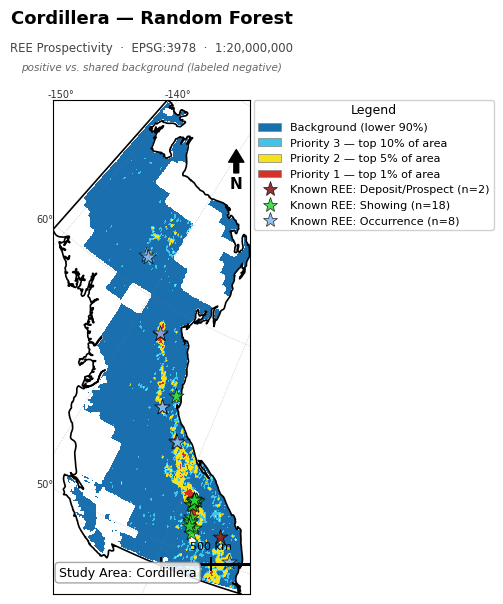

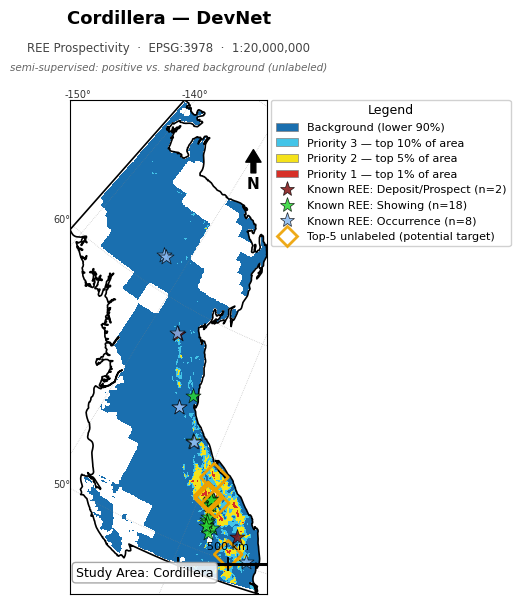

[Grenville] building prediction grid ...
  [Grenville] prediction grid: 8784 (within outline) -> 8555 after A∧B sampleable-domain filter (97.4% kept)
  extracting GLCM texture features for prediction grid ...
    GLCM: Canada_BA → 4 texture features (nodata-aware)
    GLCM: Canada_BA_HP40km → 4 texture features (nodata-aware)
    GLCM: DRTP → 4 texture features (nodata-aware)
    GLCM: TMI → 4 texture features (nodata-aware)
  [Grenville] top-5 target percentiles within the prediction grid:
    (44.3998, -76.3333)  grid percentile = 99.99
    (44.3998, -76.4333)  grid percentile = 99.98
    (45.4998, -76.8333)  grid percentile = 99.96
    (44.5998, -78.3333)  grid percentile = 99.95
    (44.4998, -77.3333)  grid percentile = 99.89
  saved → Grenville_prospectivity_combined_dedup.geojson


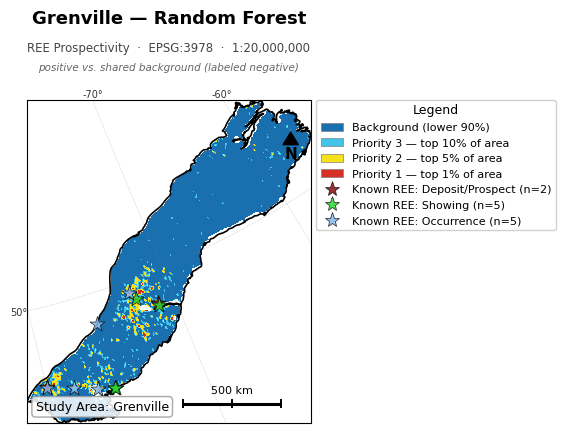

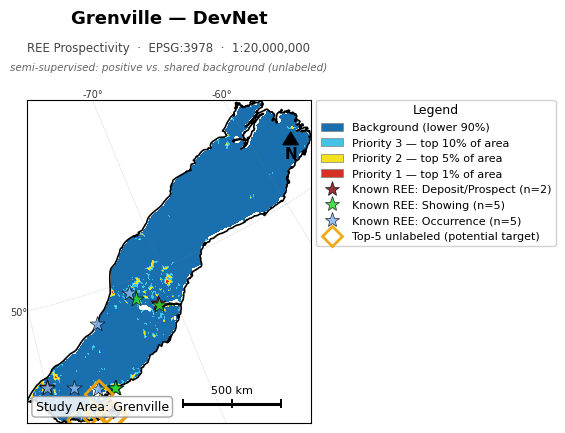

[Superior] building prediction grid ...
  [Superior] prediction grid: 19748 (within outline) -> 19417 after A∧B sampleable-domain filter (98.3% kept)
  extracting GLCM texture features for prediction grid ...
    GLCM: Canada_BA → 4 texture features (nodata-aware)
    GLCM: Canada_BA_HP40km → 4 texture features (nodata-aware)
    GLCM: DRTP → 4 texture features (nodata-aware)
    GLCM: TMI → 4 texture features (nodata-aware)
  [Superior] top-5 target percentiles within the prediction grid:
    (49.2271, -78.2443)  grid percentile = 99.98
    (49.2271, -96.2443)  grid percentile = 99.96
    (55.2271, -93.5443)  grid percentile = 99.94
    (55.0271, -76.8443)  grid percentile = 99.92
    (50.9271, -95.2443)  grid percentile = 99.91
  saved → Superior_prospectivity_combined_dedup.geojson


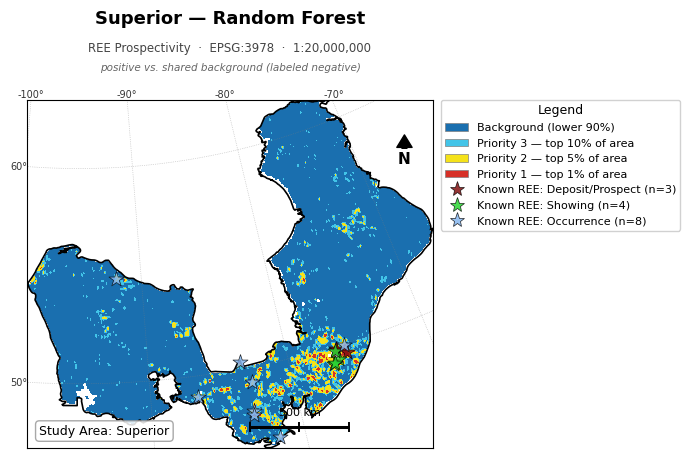

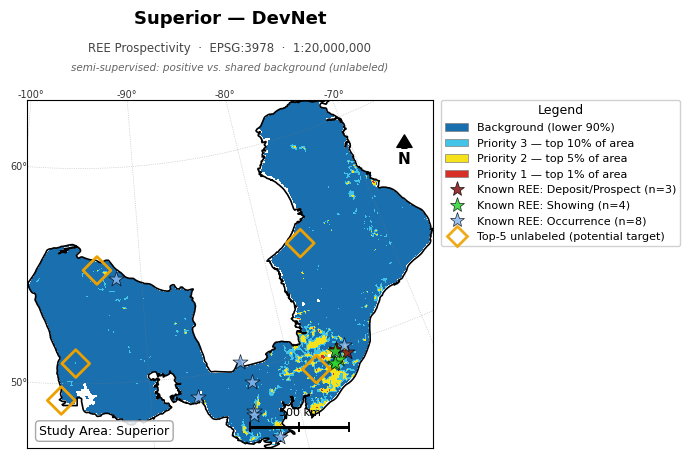

In [27]:
GRID_SCORES = {}   # name -> {'RF': array, 'DevNet(deviation)': array} -- A∧B grid production-model
                   # scores, used by the P-A plot below as the spatial "area" data source
                   # (distinct from the labeled positives' pooled-OOF scores).

for name in RUN_REGIONS:
    cfg = REGIONS[name]
    t = TRAINED[name]
    grid = predict_grid(
        cfg, name,
        t['rf_model'], t['rf_scaler'], t['rf_imp'], t['feat_cols'],
        t['dn_ensemble'], t['dn_scaler'], t['dn_imp'],
        WORM_TREES, top_targets=t.get('top_targets'),
    )
    TRAINED[name]['grid'] = grid
    GRID_SCORES[name] = {'RF': grid['rf_proba'].values,
                         'DevNet(deviation)': grid['dn_proba'].values}

## 12b. Capture-Rate Curve & Table (OOF, leakage-free)

This reports a capture-rate curve rather than a Prediction–Area (P–A) plot
(Yousefi & Carranza, 2015): a P–A plot needs to locate a crossing point and
draw an area-rate line, both of which are prone to degenerate cases
(no-crossing, near-flat curves) with a dataset this small. A capture-rate
curve avoids both constructions entirely while answering the same practical
question -- how much of the known deposit inventory sits inside the
top-ranked share of the study area.

### Capture-rate curve

Same leakage-free data source as the capture-rate table just below it --
`RESULTS[name][model]['pruned']['oof_rank']` / `['oof_y']` (pooled
out-of-fold scores; a positive's score is never produced by a model
trained on that positive).

- **x-axis**: the top X% of the labeled pool (positive + `eval_neg`),
  ranked by OOF score, X ∈ [0, 20]. Since the labeled pool is dominated
  by a random background sample (`eval_neg`), this is a *proxy* for
  search area, not the true A∧B grid area -- the same caveat the
  capture-rate table already carries.
- **y-axis**: fraction of known positives captured within that top X%.
- Truncated to 0–20% (rather than the full 0–100%) to focus on the
  exploration-actionable, high-priority range -- most of the curve's
  informative structure is in the first fifth of the ranked pool.
- One panel per region, RF and DevNet(deviation) as solid lines, plus a
  `y = x` dashed diagonal as the random-selection baseline. Dots at
  x = 1%, 5%, 10% are read directly from the capture-rate table below,
  so they match its numbers exactly.

**Citations**: Chung, C.J.F. and Fabbri, A.G. (1999). *Probabilistic
prediction models for landslide hazard mapping.* Photogrammetric
Engineering and Remote Sensing, 65(12), pp. 1389–1399. Agterberg, F.P.
and Bonham-Carter, G.F. (2005). *Measuring the performance of mineral-
potential maps.* Natural Resources Research, 14, pp. 1–17.

### Capture-rate table

**Primary, sample-stable metric:** `capture_rate_at_area_oof` -- ranks
the labeled pool by OOF score, takes the count-based top 1/5/10/20% (by
pool size, `eval_neg`-dominated so this approximates "area"), and reports
what fraction of *known positives* fall in that top slice. Same
OOF-only, no-production-model discipline as the curve above.



=== OOF capture rate at fixed labeled-pool rank thresholds (primary metric, leakage-free) ===
area_pct                       1.0    2.0    3.0    4.0    5.0    10.0
region     model                                                      
Cordillera DevNet(deviation)  0.185  0.296  0.333  0.370  0.444  0.630
           RF                 0.444  0.630  0.667  0.667  0.704  0.815
Grenville  DevNet(deviation)  0.083  0.083  0.167  0.250  0.250  0.417
           RF                 0.417  0.417  0.417  0.417  0.500  0.583
Superior   DevNet(deviation)  0.467  0.667  0.800  0.800  0.800  0.867
           RF                 0.467  0.667  0.667  0.733  0.733  0.867
save to: capture_curves_600dpi.png (600 DPI)


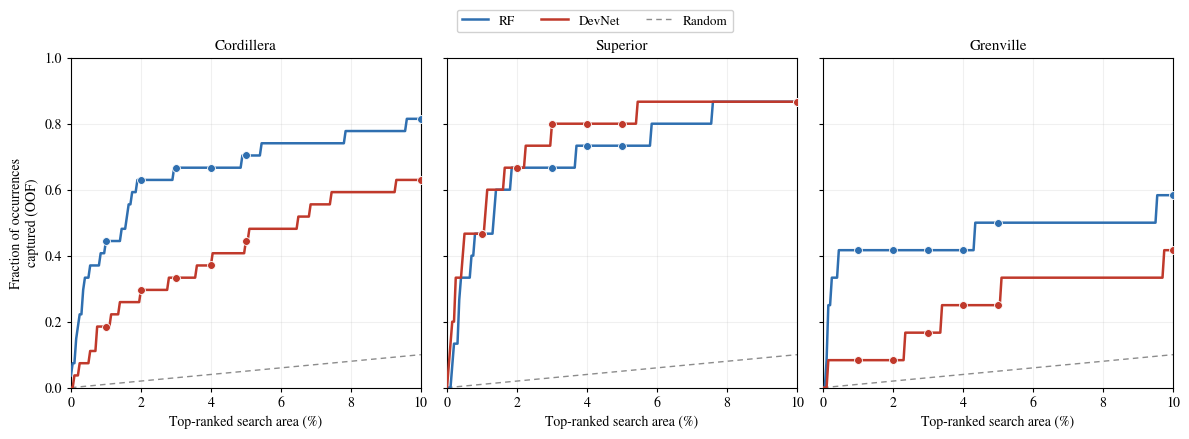

In [52]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd


def capture_rate_at_area_oof(oof_rank, oof_y, area_fracs=(0.01, 0.02, 0.03, 0.04, 0.05, 0.10)):
    """Primary exploration-efficiency metric, OOF-only. Ranks the labeled
    pool (positive + eval_neg) by pooled-OOF score, takes the count-based
    top area_frac fraction of that pool (eval_neg-dominated, so this
    approximates 'top area_frac of the mapped area'), and reports what
    fraction of KNOWN POSITIVES land inside that top slice. No production
    model involved -- can't leak, can't degenerate the way a crossing-point
    search can under a small sample.
    """
    m = np.isfinite(oof_rank)
    r, y = np.asarray(oof_rank)[m], np.asarray(oof_y)[m].astype(int)
    n_total = len(r)
    n_pos_total = int((y == 1).sum())
    order = np.argsort(-r)   # descending by OOF score
    y_sorted = y[order]

    rows = []
    for a in area_fracs:
        k = max(1, int(round(a * n_total)))
        n_pos_in_top = int((y_sorted[:k] == 1).sum())
        capture = n_pos_in_top / n_pos_total if n_pos_total > 0 else float('nan')
        rows.append({'area_pct': a * 100, 'n_top': k, 'n_pos_captured': n_pos_in_top,
                    'n_pos_total': n_pos_total, 'capture_rate': capture})
    return rows


def capture_curve_oof(oof_rank, oof_y, x_max_pct=20.0, n_points=201):
    """Continuous capture-rate CURVE over x in [0, x_max_pct]%. Same OOF-only,
    leakage-free data source and same count-based top-k selection rule as
    capture_rate_at_area_oof -- just swept over a fine grid of x instead of
    the table's four fixed thresholds. x = top-x% of the labeled pool by
    OOF score (eval_neg-dominated, so a proxy for search area); y =
    fraction of known positives captured in that top-x%. No intersection,
    no area-rate line -- those two constructions were the source of every
    P-A plot artifact above, so this curve never computes either.
    """
    m = np.isfinite(oof_rank)
    r, y = np.asarray(oof_rank)[m], np.asarray(oof_y)[m].astype(int)
    n_total = len(r)
    n_pos_total = int((y == 1).sum())
    order = np.argsort(-r)
    y_sorted = y[order]
    cum_pos = np.cumsum(y_sorted == 1)

    x_vals = np.linspace(0.0, x_max_pct, n_points)
    k_vals = np.clip(np.round(x_vals / 100.0 * n_total).astype(int), 1, n_total)
    if n_pos_total > 0:
        capture = cum_pos[k_vals - 1] / n_pos_total
    else:
        capture = np.full(n_points, np.nan)
    return x_vals, capture


def plot_capture_curves(capture_df, x_max_pct=10.0, save_path="capture_curves_600dpi.png"):
    """Publication-quality capture-rate curves with top-centered legend and 600 DPI output."""
    colors = {'RF': '#2f6fb0', 'DevNet(deviation)': '#c0392b'}
    mark_pcts = [1, 2, 3, 4, 5, 10]

    # 子图展示顺序：Superior 放中间（不改动 RUN_REGIONS 本身）
    plot_regions = ['Cordillera', 'Superior', 'Grenville']

    plt.rcParams.update({'font.size': 10, 'axes.linewidth': 0.8})
    fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), sharey=True)

    for ax, name in zip(axes, plot_regions):
        for model in RESULTS[name].keys():
            res = RESULTS[name][model].get('pruned')
            if res is None or 'oof_rank' not in res:
                continue
            c = colors.get(model, '#444444')
            x_vals, capture = capture_curve_oof(res['oof_rank'], res['oof_y'],
                                                x_max_pct=x_max_pct)
            ax.plot(x_vals, capture, color=c, lw=1.8, zorder=3)
            sub = capture_df[(capture_df['region'] == name) &
                             (capture_df['model'] == model)]
            for pct in mark_pcts:
                row = sub[sub['area_pct'] == pct]
                if len(row):
                    ax.scatter(row['area_pct'], row['capture_rate'], color=c, s=32,
                               zorder=4, edgecolors='white', linewidths=0.6)
        ax.plot([0, x_max_pct], [0, x_max_pct / 100.0], color='0.55', lw=1.0,
                ls=(0, (4, 3)), zorder=2)
        ax.set_xlim(0, x_max_pct)
        ax.set_ylim(0, 1.0)
        ax.set_xlabel('Top-ranked search area (%)')
        ax.set_title(name, fontsize=11)
        ax.grid(alpha=0.18, zorder=0)
        ax.set_axisbelow(True)
        ax.tick_params(length=3)

    axes[0].set_ylabel('Fraction of occurrences\ncaptured (OOF)')

    handles = [Line2D([], [], color=colors['RF'], lw=1.8, label='RF'),
               Line2D([], [], color=colors['DevNet(deviation)'], lw=1.8, label='DevNet'),
               Line2D([], [], color='0.55', lw=1.0, ls=(0, (4, 3)), label='Random')]

    fig.legend(handles=handles, fontsize=9.5, loc='upper center',
               bbox_to_anchor=(0.5, 1.05), ncol=3, frameon=True,
               framealpha=0.9, edgecolor='0.8')

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=600, bbox_inches='tight')
        print(f"save to: {save_path} (600 DPI)")

    plt.show()


CAPTURE_AREA_FRACS = (0.01, 0.02, 0.03, 0.04, 0.05, 0.10)
capture_rows = []
for name in RUN_REGIONS:
    for model in RESULTS[name].keys():
        res = RESULTS[name][model].get('pruned')
        if res is None or 'oof_rank' not in res:
            continue
        for row in capture_rate_at_area_oof(res['oof_rank'], res['oof_y'], CAPTURE_AREA_FRACS):
            capture_rows.append({'region': name, 'model': model, **row})

capture_df = pd.DataFrame(capture_rows)
print('\n=== OOF capture rate at fixed labeled-pool rank thresholds (primary metric, leakage-free) ===')
pd.set_option('display.width', 160)
pivot = capture_df.pivot_table(index=['region', 'model'], columns='area_pct', values='capture_rate')
print(pivot.round(3).to_string())

plot_capture_curves(capture_df)

## 13. SHAP Feature-Attribution Analysis

This section is purely **explanatory** -- it does not touch the data
pipeline, the evaluation protocol, or training logic above. It answers a
different question than Sections 9-12: not "how good is each model" but
"what did each model actually learn to pay attention to, and do RF and
DevNet agree?"

**Method:**

- **RF** -- `shap.TreeExplainer` (TreeSHAP), not impurity/Gini importance.
  Impurity importance is biased toward high-cardinality continuous features
  and isn't on a comparable scale to a neural net's attributions; TreeSHAP
  is exact for tree ensembles and produces per-sample, signed attributions
  just like DevNet's explainer does, which is what makes a fair comparison
  possible at all.
- **DevNet** -- `shap.DeepExplainer`, falling back to `GradientExplainer`
  then `KernelExplainer` if the former errors (PyTorch/SHAP version
  compatibility is fragile across releases -- see Section 13a). Only the
  **first ensemble member** (`dn_ensemble[0]`, trained with `seed=DN_SEED`)
  is explained -- it stands in for the full `DN_RESTARTS`-model ensemble
  used elsewhere in this notebook, not a separately-trained model.
- **Same features, same explain-set, model-appropriate preprocessing** --
  both models are explained on `TRAINED[name]['feat_cols']` (the region's
  pruned feature set, identical to what each model was actually trained on)
  and on the **same underlying points** (positives + a sample of `eval_neg`).
  Each model's own production `imputer`/`scaler` transforms those raw points
  before SHAP runs -- RF's `rf_imp`/`rf_scaler`, DevNet's `dn_imp`/`dn_scaler`
  -- since those were fit on different pools (RF: positive+eval_neg,
  DevNet: positive+unlabeled) and running SHAP on unprocessed raw features
  would silently mismatch what each model actually sees at inference time.

**Caveat worth keeping in mind when comparing magnitudes:** because RF's and
DevNet's scalers were fit on different underlying pools, the *numeric scale*
of "one standard deviation" differs slightly between the two models even for
the same raw feature. This does not affect within-model feature ranking or
sign/direction, which is what the comparisons below actually rely on, but it
means a strict "is RF's SHAP value 3x DevNet's" magnitude comparison isn't
perfectly apples-to-apples -- rank and direction are the meaningful part.

`FAST_MODE` controls compute here too: `True` runs SHAP on only
`RUN_REGIONS[0]` with small background/explain samples; `False` runs it for
every region in `RUN_REGIONS` with larger samples.


In [29]:
try:
    import shap
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'shap'])
    import shap

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

if FAST_MODE:
    SHAP_REGIONS   = [RUN_REGIONS[0]]
    SHAP_BG_N      = 50    # background sample size for DevNet's explainer
    SHAP_EXPLAIN_N = 60    # points (positives + eval_neg sample) SHAP is computed for
else:
    SHAP_REGIONS   = list(RUN_REGIONS)
    SHAP_BG_N      = 100
    SHAP_EXPLAIN_N = 200

print(f'shap {shap.__version__}')
print(f'SHAP_REGIONS={SHAP_REGIONS}  SHAP_BG_N={SHAP_BG_N}  SHAP_EXPLAIN_N={SHAP_EXPLAIN_N}')

# Where SHAP figures get saved (high-res, 600 dpi, for the final write-up).
# A new folder living right next to this notebook.
SHAP_FIG_DIR = os.path.join(os.getcwd(), 'shap_figures')
os.makedirs(SHAP_FIG_DIR, exist_ok=True)
SHAP_FIG_DPI = 600
print(f'SHAP figures will be saved to: {SHAP_FIG_DIR} (dpi={SHAP_FIG_DPI})')


shap 0.46.0
SHAP_REGIONS=['Cordillera', 'Grenville', 'Superior']  SHAP_BG_N=100  SHAP_EXPLAIN_N=200
SHAP figures will be saved to: /home/mt125/IRP_code/code_miaozhou/notebooks/shap_figures (dpi=600)


### 13a. Explainers

`DevNet.forward()` returns a **squeezed** `(N,)` tensor (`self.net(x).squeeze(-1)`)
-- fine for training, but it breaks `shap.DeepExplainer`/`GradientExplainer`
on this environment's PyTorch/SHAP versions (`IndexError` inside SHAP's
internals, confirmed by testing before writing this cell). `_DevNetSHAPWrapper`
below calls `base_model.net(x)` directly, skipping the squeeze so the output
stays `(N, 1)`, which both explainers expect. This changes nothing about the
model's actual predictions -- it's purely a shape adapter for SHAP.

`explain_devnet` tries `DeepExplainer` first, then `GradientExplainer`, then
falls back to the fully model-agnostic (but much slower) `KernelExplainer`
if both gradient-based explainers raise. `explain_rf` uses `TreeExplainer`
with SHAP's default `tree_path_dependent` perturbation, which needs no
explicit background sample (it uses the tree structure itself) -- simpler
and exact for tree ensembles.


In [30]:
class _DevNetSHAPWrapper(nn.Module):
    """Adapts a trained DevNet for SHAP: keeps the (N,1) output shape that
    DeepExplainer/GradientExplainer need instead of DevNet.forward()'s
    squeezed (N,) shape. Does not change what the model predicts."""
    def __init__(self, base_model):
        super().__init__()
        self.base_model = base_model
    def forward(self, x):
        return self.base_model.net(x)


def explain_rf(rf_model, X_explain):
    """TreeSHAP for the RF production model. Returns (shap_values, expected_value)
    for the positive class, shape (n_explain, n_features)."""
    explainer = shap.TreeExplainer(rf_model)
    sv = np.array(explainer.shap_values(X_explain))
    ev = explainer.expected_value
    if sv.ndim == 3:            # (n, n_features, n_classes) -- keep positive class
        sv = sv[:, :, 1]
        ev = ev[1] if np.ndim(ev) > 0 else ev
    return sv, float(np.ravel(ev)[0])


def explain_devnet(model, X_bg, X_explain, base_seed=DN_SEED):
    """DeepExplainer -> GradientExplainer -> KernelExplainer fallback chain
    for one DevNet model. Returns (shap_values, expected_value, method_name),
    shap_values shape (n_explain, n_features)."""
    torch.manual_seed(base_seed)
    wrapped = _DevNetSHAPWrapper(model).to(DEVICE).eval()
    X_bg_t = torch.tensor(X_bg, dtype=torch.float32, device=DEVICE)
    X_ex_t = torch.tensor(X_explain, dtype=torch.float32, device=DEVICE)

    for method_name, build in [
        ('DeepExplainer',     lambda: shap.DeepExplainer(wrapped, X_bg_t)),
        ('GradientExplainer', lambda: shap.GradientExplainer(wrapped, X_bg_t)),
    ]:
        try:
            explainer = build()
            sv = np.array(explainer.shap_values(X_ex_t))
            if sv.ndim == 3:
                sv = sv[..., 0]
            ev = float(np.ravel(explainer.expected_value)[0])
            return sv, ev, method_name
        except Exception as e:
            print(f'    {method_name} failed ({type(e).__name__}: {str(e)[:150]}), falling back ...')

    print('    using KernelExplainer (model-agnostic, slower) ...')
    def _f(x):
        wrapped.eval()
        with torch.no_grad():
            out = wrapped(torch.tensor(x, dtype=torch.float32, device=DEVICE))
        return out.cpu().numpy().reshape(-1)
    bg_summary = shap.kmeans(X_bg, min(10, len(X_bg)))
    explainer = shap.KernelExplainer(_f, bg_summary)
    sv = np.array(explainer.shap_values(X_explain, nsamples=100))
    if sv.ndim == 3:
        sv = sv[..., 0]
    ev = float(np.ravel(explainer.expected_value)[0])
    return sv, ev, 'KernelExplainer'


### 13b. Per-Region SHAP Computation

Explain-set construction per region: **all positives** (rare, most
interesting) plus a random sample of `eval_neg` up to `SHAP_EXPLAIN_N` total
-- the same underlying points are used for both models. DevNet's background
sample is drawn separately from the region's `train_unlabeled` pool (its own
training distribution); RF needs no explicit background (see 13a).


In [31]:
SHAP_RESULTS = {}

for name in SHAP_REGIONS:
    print(f'\n[{name}] computing SHAP ...')
    t = TRAINED[name]
    feat_cols = t['feat_cols']            # region's pruned feature set (== REGION_FEATS[name])
    pts_all = t['pts']

    pos_rows = pts_all[pts_all['pool'] == 'positive']
    eval_rows = pts_all[pts_all['pool'] == 'eval_neg']
    n_eval_needed = max(0, SHAP_EXPLAIN_N - len(pos_rows))
    eval_sample = eval_rows.sample(n=min(n_eval_needed, len(eval_rows)), random_state=RANDOM_SEED)
    explain_pts = pd.concat([pos_rows, eval_sample], ignore_index=True)

    unlabeled_rows = pts_all[pts_all['pool'] == 'train_unlabeled']
    bg_pts = unlabeled_rows.sample(n=min(SHAP_BG_N, len(unlabeled_rows)), random_state=RANDOM_SEED)

    X_explain_raw, y_explain, _ = get_raw_features(explain_pts, feat_subset=feat_cols)
    X_bg_raw, _, _ = get_raw_features(bg_pts, feat_subset=feat_cols)
    print(f'  explain set: {len(explain_pts)} points ({int((y_explain==1).sum())} positive, '
          f'{int((y_explain==0).sum())} eval_neg)  |  DevNet background: {len(bg_pts)} unlabeled points')

    # RF: same explain points, RF's own production imputer/scaler
    X_explain_rf = t['rf_scaler'].transform(t['rf_imp'].transform(X_explain_raw))
    shap_rf, ev_rf = explain_rf(t['rf_model'], X_explain_rf)

    # DevNet: same explain points (raw), but DevNet's own imputer/scaler for
    # both the explain set and the background -- and only the representative
    # ensemble member (dn_ensemble[0], seed=DN_SEED).
    X_explain_dn = t['dn_scaler'].transform(t['dn_imp'].transform(X_explain_raw))
    X_bg_dn      = t['dn_scaler'].transform(t['dn_imp'].transform(X_bg_raw))
    shap_dn, ev_dn, method_dn = explain_devnet(t['dn_ensemble'][0], X_bg_dn, X_explain_dn)
    print(f'  DevNet explainer used: {method_dn}')

    SHAP_RESULTS[name] = {
        'feat_cols': feat_cols,
        'X_explain_rf': X_explain_rf, 'shap_rf': shap_rf, 'expected_value_rf': ev_rf,
        'X_explain_dn': X_explain_dn, 'shap_dn': shap_dn, 'expected_value_dn': ev_dn,
        'devnet_method': method_dn,
        'X_bg_dn': X_bg_dn,
        'explain_pts': explain_pts,
    }

print('\nSHAP computed for:', list(SHAP_RESULTS.keys()))



[Cordillera] computing SHAP ...
  explain set: 200 points (27 positive, 173 eval_neg)  |  DevNet background: 100 unlabeled points
  DevNet explainer used: DeepExplainer

[Grenville] computing SHAP ...
  explain set: 200 points (12 positive, 188 eval_neg)  |  DevNet background: 100 unlabeled points
  DevNet explainer used: DeepExplainer

[Superior] computing SHAP ...
  explain set: 200 points (15 positive, 185 eval_neg)  |  DevNet background: 100 unlabeled points
  DevNet explainer used: DeepExplainer

SHAP computed for: ['Cordillera', 'Grenville', 'Superior']


### 13c. SHAP Summary (Beeswarm) Plots

One beeswarm per model per region: each dot is one explained point, its
x-position is that point's SHAP value for the feature (row), and color is
the (scaled) feature value -- so besides magnitude, these show *direction*
per point (e.g. "high gravity anomaly pushes the prediction up, consistently,
across most points" vs. "sign flips depending on some other factor").


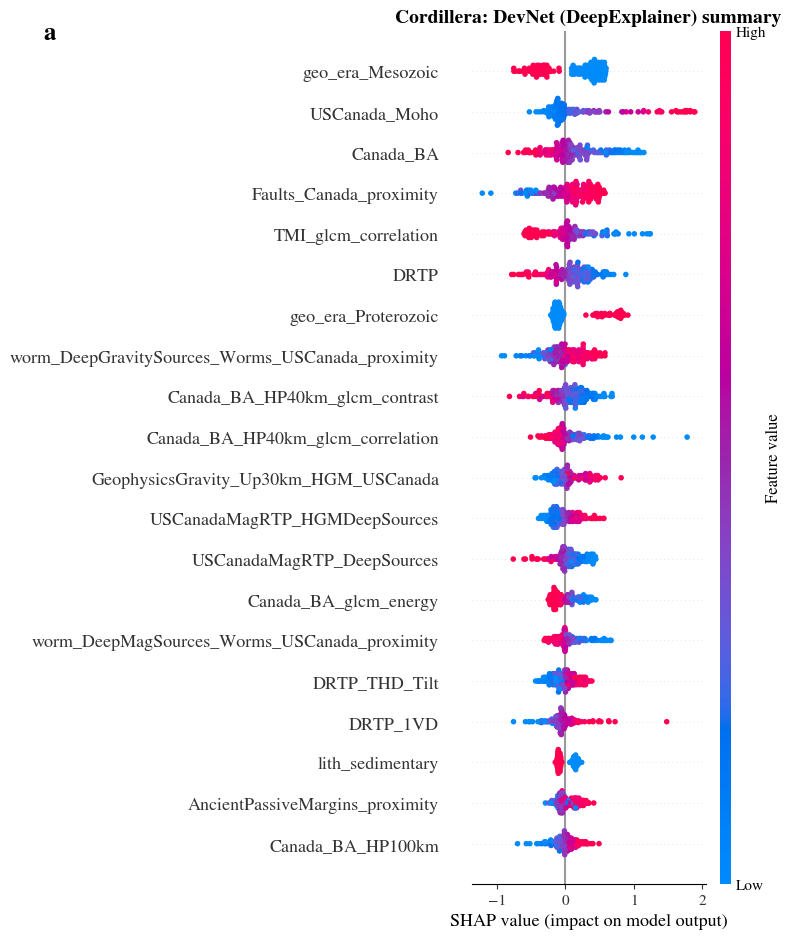

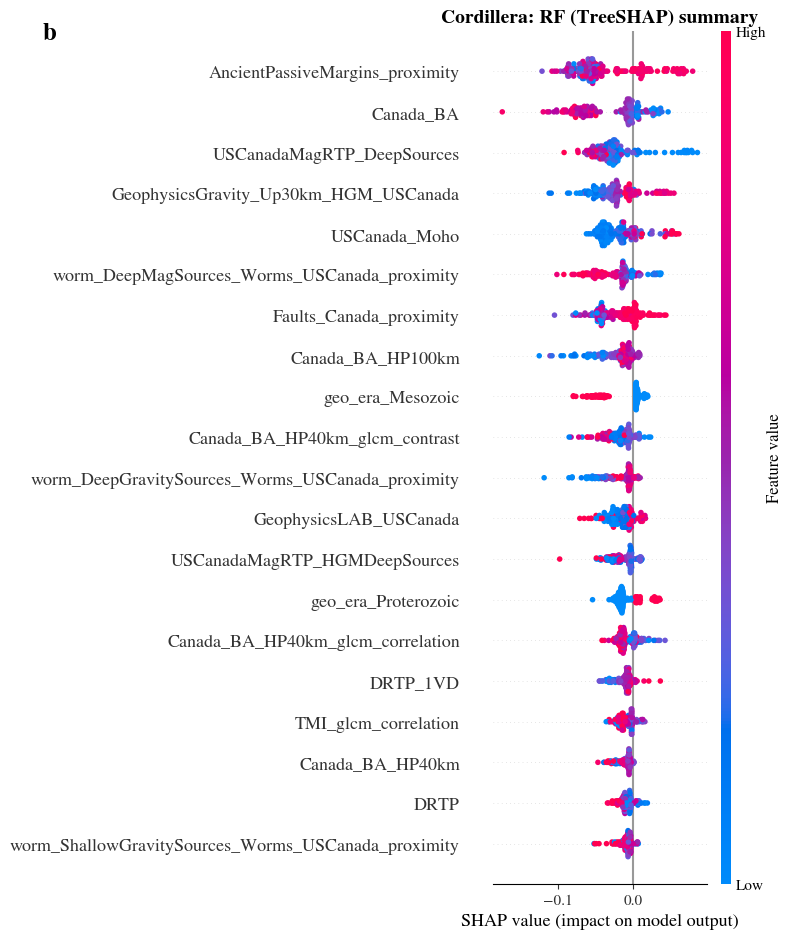

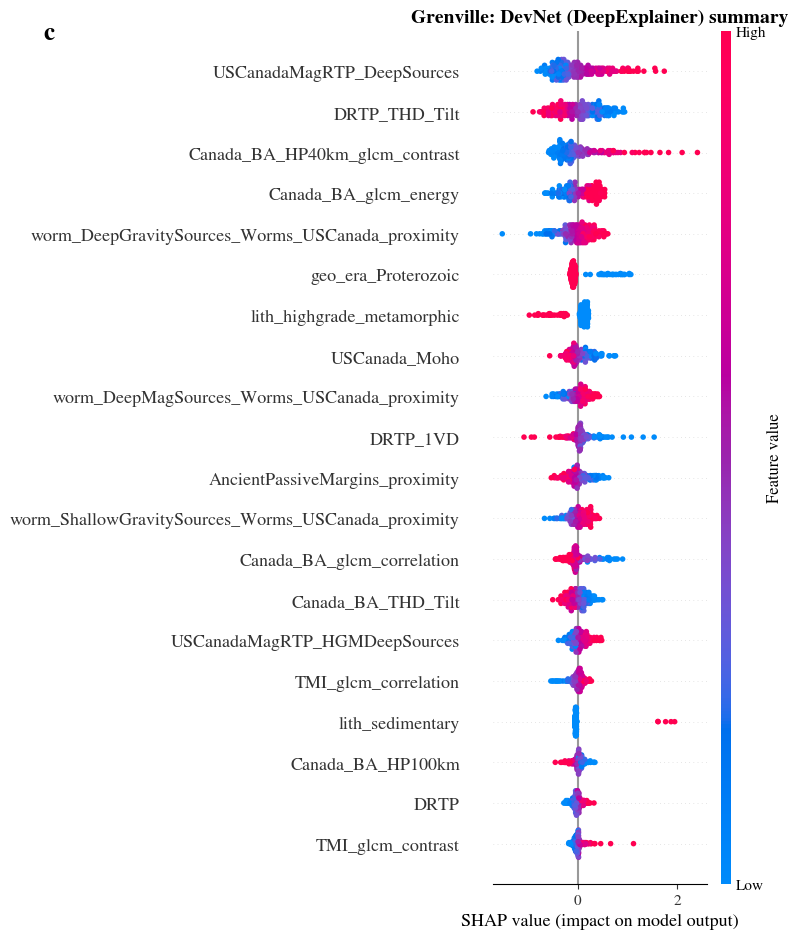

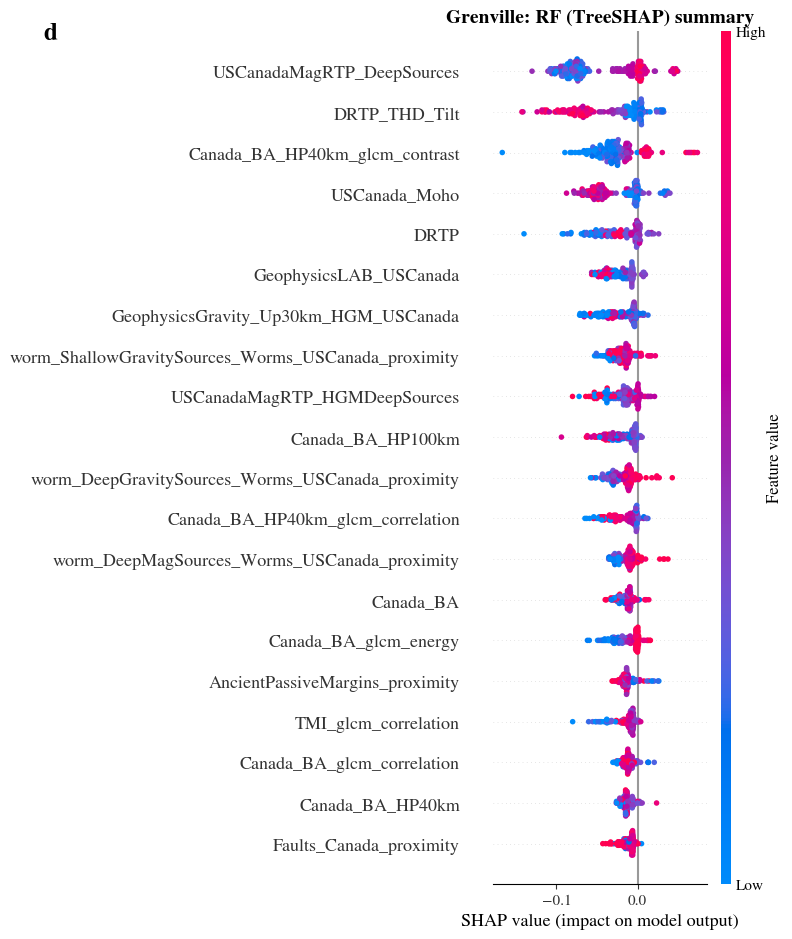

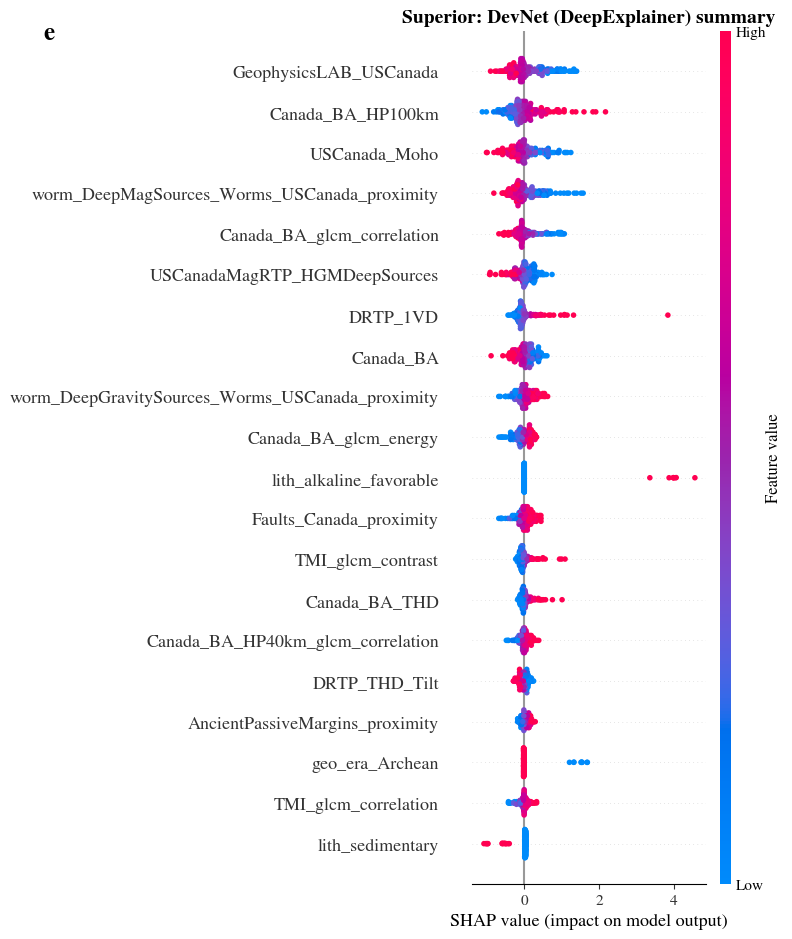

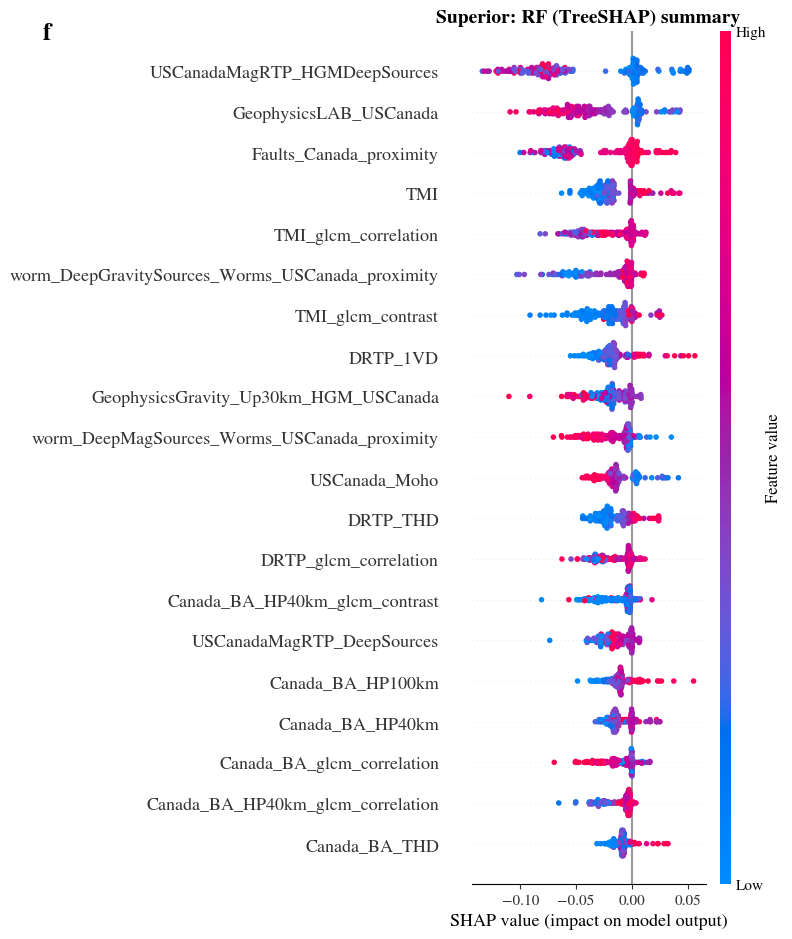

In [32]:
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['mathtext.fontset'] = 'stix'
TITLE_FONTSIZE = 14
PANEL_LABEL_FONTSIZE = 18

# Panel letters for the combined figure these outputs feed into:
# (a, b) Cordillera, (c, d) Superior, (e, f) Grenville -- DevNet left
# column, RF right column.
_LETTER_PAIRS = [('a', 'b'), ('c', 'd'), ('e', 'f')]


def _label_panel(ax, letter):
    """Stamp the panel letter in the top-left corner of the whole figure."""
    ax.figure.text(0.06, 0.97, f'{letter}',
                   fontsize=PANEL_LABEL_FONTSIZE, fontweight='bold',
                   va='top', ha='left')


for idx, name in enumerate(SHAP_REGIONS):
    r = SHAP_RESULTS[name]
    dn_letter, rf_letter = _LETTER_PAIRS[idx]

    plt.figure()
    shap.summary_plot(r['shap_dn'], r['X_explain_dn'], feature_names=r['feat_cols'], show=False)
    plt.title(f'{name}: DevNet ({r["devnet_method"]}) summary', fontsize=TITLE_FONTSIZE, fontweight='bold')
    _label_panel(plt.gca(), dn_letter)
    plt.tight_layout()
    plt.savefig(os.path.join(SHAP_FIG_DIR, f'{name}_DevNet_summary.png'),
                dpi=SHAP_FIG_DPI, bbox_inches='tight', pad_inches=0.2)
    plt.show()

    plt.figure()
    shap.summary_plot(r['shap_rf'], r['X_explain_rf'], feature_names=r['feat_cols'], show=False)
    plt.title(f'{name}: RF (TreeSHAP) summary', fontsize=TITLE_FONTSIZE, fontweight='bold')
    _label_panel(plt.gca(), rf_letter)
    plt.tight_layout()
    plt.savefig(os.path.join(SHAP_FIG_DIR, f'{name}_RF_summary.png'),
                dpi=SHAP_FIG_DPI, bbox_inches='tight', pad_inches=0.2)
    plt.show()

### 13e. Direction-Consistency Check

For the features that matter most to *either* model (ranked by combined
importance), this table reports each model's **average SHAP sign** --
whether a higher value of that feature pushes the prediction toward "more
prospective" or "less prospective" on average -- and flags whether the two
models agree. This is the table to check against geological intuition (e.g.
"higher gravity/magnetic anomaly should push toward more prospective" for a
carbonatite-hosted REE system) -- `direction_agree=False` rows are the
interesting ones, either a modeling artifact or a genuine RF/DevNet
disagreement worth digging into.

Caveat: "average sign" is a simplification -- a feature's effect need not be
monotonic for every point. Treat this as a summary, not a proof of
monotonic behavior.


In [33]:
def direction_consistency_table(shap_rf, shap_dn, feat_cols, top_k=10):
    imp_rf = np.abs(shap_rf).mean(axis=0)
    imp_dn = np.abs(shap_dn).mean(axis=0)
    norm_rf = imp_rf / imp_rf.max() if imp_rf.max() > 0 else imp_rf
    norm_dn = imp_dn / imp_dn.max() if imp_dn.max() > 0 else imp_dn
    top_idx = np.argsort(-(norm_rf + norm_dn))[:top_k]

    mean_rf = shap_rf.mean(axis=0)
    mean_dn = shap_dn.mean(axis=0)

    rows = []
    for i in top_idx:
        dir_rf = 'higher -> more prospective' if mean_rf[i] > 0 else 'higher -> less prospective'
        dir_dn = 'higher -> more prospective' if mean_dn[i] > 0 else 'higher -> less prospective'
        rows.append({
            'feature': feat_cols[i],
            'RF_importance': round(imp_rf[i], 4), 'RF_direction': dir_rf,
            'DevNet_importance': round(imp_dn[i], 4), 'DevNet_direction': dir_dn,
            'direction_agree': (mean_rf[i] > 0) == (mean_dn[i] > 0),
        })
    return pd.DataFrame(rows)


pd.set_option('display.width', 160)
for name in SHAP_REGIONS:
    r = SHAP_RESULTS[name]
    table = direction_consistency_table(r['shap_rf'], r['shap_dn'], r['feat_cols'])
    n_agree = int(table['direction_agree'].sum())
    print(f'\n[{name}] top {len(table)} jointly-important features -- '
          f'{n_agree}/{len(table)} agree on direction:')
    print(table.to_string(index=False))



[Cordillera] top 10 jointly-important features -- 0/10 agree on direction:
                              feature  RF_importance               RF_direction  DevNet_importance           DevNet_direction  direction_agree
                            Canada_BA         0.0369 higher -> less prospective             0.3020 higher -> more prospective            False
                     geo_era_Mesozoic         0.0214 higher -> less prospective             0.3870 higher -> more prospective            False
                        USCanada_Moho         0.0269 higher -> less prospective             0.3229 higher -> more prospective            False
      AncientPassiveMargins_proximity         0.0530 higher -> less prospective             0.1144 higher -> more prospective            False
              Faults_Canada_proximity         0.0253 higher -> less prospective             0.2786 higher -> more prospective            False
           USCanadaMagRTP_DeepSources         0.0353 higher -> les

### 13e-2. geo_era: Occurrence and SHAP Importance by Region

`geo_era` is a full one-hot (Section 3e, `ERA_DUMMY_GROUPS`) -- every one
of the 5 eras gets its own column, none dropped as a reference, precisely
so each era's own SHAP contribution can be read off directly and compared
across regions. This cell does two things, reusing `SHAP_RESULTS` as-is
(no new SHAP computation):

1. **Occurrence rate** per region for all 5 eras, over the full candidate
   + positive pool (`TRAINED[name]['pts']`) -- an era with 0 occurrences
   in a region is a zero-variance column there (Section 5a's
   `prune_collinear` fix) and trivially carries no SHAP importance, so
   this table is necessary context before reading the importance numbers.
2. **SHAP importance per era per region**, RF vs. DevNet, using the same
   `mean(|SHAP|)` importance and `sign(mean(SHAP))` direction convention
   as `plot_global_importance_comparison` / `direction_consistency_table`
   above, plus `mean(SHAP | era present)` -- the more directly
   interpretable "when this specific era IS the terrane, which way does
   it push the score" (most points have any given era absent, so the
   plain overall mean(SHAP) is dominated by the "absent" case; the
   when-present figure isolates the era's own marginal effect). An era
   whose dummy was pruned out by `prune_collinear` (possible if two eras'
   occurrence patterns are strongly complementary in a region) has no
   SHAP value and is flagged rather than silently omitted.

=== geo_era occurrence rate per region (candidate + positive pool) ===
region       Cordillera  Grenville  Superior
era                                         
Archean          0.0014     0.1791    0.9768
Proterozoic      0.1737     0.8160    0.0213
Paleozoic        0.3790     0.0021    0.0017
Mesozoic         0.3717     0.0027    0.0001
Cenozoic         0.0743     0.0000    0.0000

Eras with ZERO occurrences (zero-variance column in that region, no SHAP possible):
   region      era
Grenville Cenozoic
 Superior Cenozoic

Eras present in the data but pruned out by prune_collinear (no SHAP value below):
   region         era  occurrence_rate
Grenville     Archean           0.1791
 Superior Proterozoic           0.0213

=== geo_era SHAP importance per region (RF vs DevNet) ===
    region         era  RF_mean_abs_shap  RF_when_present  DevNet_mean_abs_shap  DevNet_when_present  n_present_in_explain_set
Cordillera     Archean            0.0000           0.0000                0.0045       

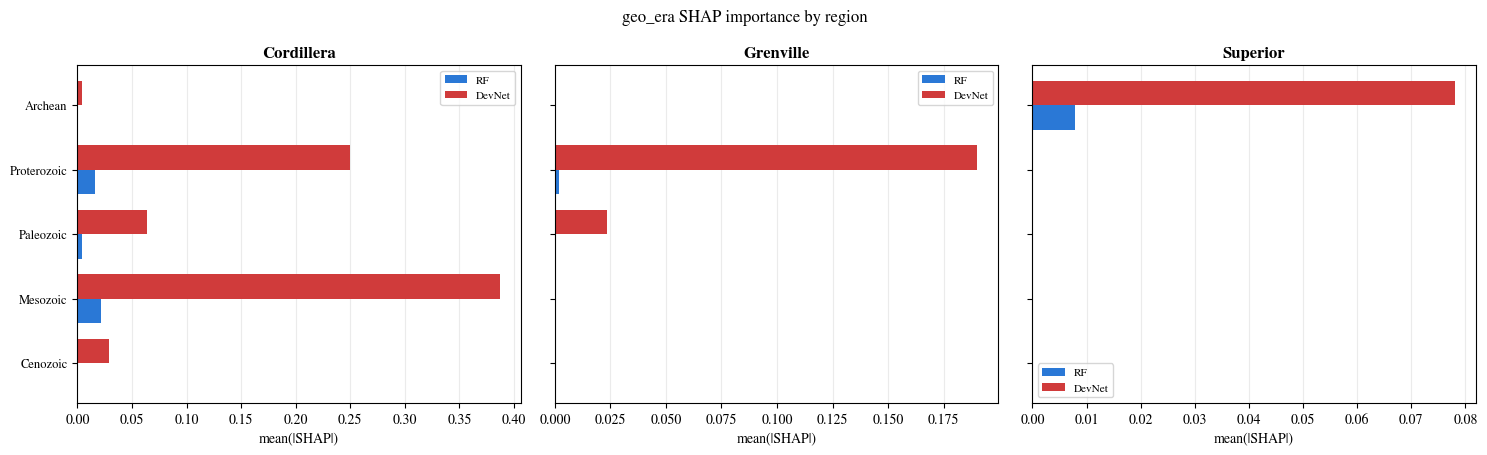

In [34]:
era_occurrence_rows = []
era_importance_rows = []

for name in SHAP_REGIONS:
    if name not in SHAP_RESULTS:
        print(f'[{name}] no SHAP_RESULTS -- run Section 13 first, skipping.')
        continue
    r = SHAP_RESULTS[name]
    feat_cols = r['feat_cols']
    pts_all = TRAINED[name]['pts']
    explain_pts = r['explain_pts']

    for era in ERA_DUMMY_GROUPS:
        col = f'geo_era_{era}'
        occ_rate = float(pts_all[col].mean(skipna=True)) if col in pts_all.columns else np.nan
        n_present = int((pts_all[col] == 1).sum()) if col in pts_all.columns else 0
        survived = col in feat_cols
        era_occurrence_rows.append({'region': name, 'era': era, 'occurrence_rate': occ_rate,
                                    'n_points_this_era': n_present, 'n_total_points': len(pts_all),
                                    'survived_pruning': survived})
        if not survived:
            continue

        i = feat_cols.index(col)
        shap_rf_col = r['shap_rf'][:, i]
        shap_dn_col = r['shap_dn'][:, i]
        era_is_1 = (explain_pts[col].values == 1)

        era_importance_rows.append({
            'region': name, 'era': era,
            'RF_mean_abs_shap':     float(np.abs(shap_rf_col).mean()),
            'RF_when_present':      float(shap_rf_col[era_is_1].mean()) if era_is_1.any() else np.nan,
            'DevNet_mean_abs_shap': float(np.abs(shap_dn_col).mean()),
            'DevNet_when_present':  float(shap_dn_col[era_is_1].mean()) if era_is_1.any() else np.nan,
            'n_present_in_explain_set': int(era_is_1.sum()),
        })

era_occurrence_df = pd.DataFrame(era_occurrence_rows)
era_importance_df = pd.DataFrame(era_importance_rows)

pd.set_option('display.width', 170)
print('=== geo_era occurrence rate per region (candidate + positive pool) ===')
pivot_occ = era_occurrence_df.pivot(index='era', columns='region', values='occurrence_rate').reindex(ERA_DUMMY_GROUPS)
print(pivot_occ.round(4).to_string())

zero_occ = era_occurrence_df[era_occurrence_df['n_points_this_era'] == 0]
if len(zero_occ):
    print('\nEras with ZERO occurrences (zero-variance column in that region, no SHAP possible):')
    print(zero_occ[['region', 'era']].to_string(index=False))

pruned_out = era_occurrence_df[~era_occurrence_df['survived_pruning'] & (era_occurrence_df['n_points_this_era'] > 0)]
if len(pruned_out):
    print('\nEras present in the data but pruned out by prune_collinear (no SHAP value below):')
    print(pruned_out[['region', 'era', 'occurrence_rate']].round(4).to_string(index=False))

print('\n=== geo_era SHAP importance per region (RF vs DevNet) ===')
print(era_importance_df.round(4).to_string(index=False))

print('\n=== Most influential era per region (ranked by RF+DevNet combined mean|SHAP|) ===')
era_importance_df['combined_importance'] = era_importance_df['RF_mean_abs_shap'] + era_importance_df['DevNet_mean_abs_shap']
for name in SHAP_REGIONS:
    sub = era_importance_df[era_importance_df['region'] == name].sort_values('combined_importance', ascending=False)
    if len(sub) == 0:
        print(f'  [{name}] no geo_era columns survived pruning -- nothing to rank.')
        continue
    for _, row in sub.iterrows():
        rf_dir = 'more prospective' if row['RF_when_present'] > 0 else 'less prospective'
        dn_dir = 'more prospective' if row['DevNet_when_present'] > 0 else 'less prospective'
        print(f"  [{name}] {row['era']:12s}  RF: importance={row['RF_mean_abs_shap']:.4f}, "
             f"present->{rf_dir} ({row['RF_when_present']:+.4f})  |  "
             f"DevNet: importance={row['DevNet_mean_abs_shap']:.4f}, present->{dn_dir} ({row['DevNet_when_present']:+.4f})")


def plot_era_importance(era_importance_df):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
    for ax, name in zip(axes, SHAP_REGIONS):
        sub = era_importance_df[era_importance_df['region'] == name].set_index('era').reindex(ERA_DUMMY_GROUPS)
        y = np.arange(len(ERA_DUMMY_GROUPS))
        h = 0.38
        ax.barh(y + h / 2, sub['RF_mean_abs_shap'].fillna(0).values, height=h, color='#2a78d6', label='RF')
        ax.barh(y - h / 2, sub['DevNet_mean_abs_shap'].fillna(0).values, height=h, color='#d03b3b', label='DevNet')
        ax.set_yticks(y); ax.set_yticklabels(ERA_DUMMY_GROUPS, fontsize=9)
        ax.invert_yaxis()
        ax.set_xlabel('mean(|SHAP|)')
        ax.set_title(name, fontweight='bold')
        ax.legend(fontsize=8)
        ax.grid(axis='x', alpha=0.25); ax.set_axisbelow(True)
    fig.suptitle('geo_era SHAP importance by region', fontsize=12)
    plt.tight_layout()
    plt.show()


plot_era_importance(era_importance_df)

### 13f. Local Explanation — Top Candidate Targets

Waterfall plots for DevNet's top-scoring unlabeled points
(`TRAINED[name]['top_targets']`, capped at 5 here regardless of `TOP_N_TARGETS`)
-- which features pushed each specific candidate target above the
background baseline. This is the evidence for "these targets are
geologically plausible, not noise": if the features driving a high score are
the same ones the global analysis above says matter (and in the expected
direction), that's a much stronger argument than the score alone.


[Cordillera] local explanation for top 5 candidate targets (DeepExplainer):


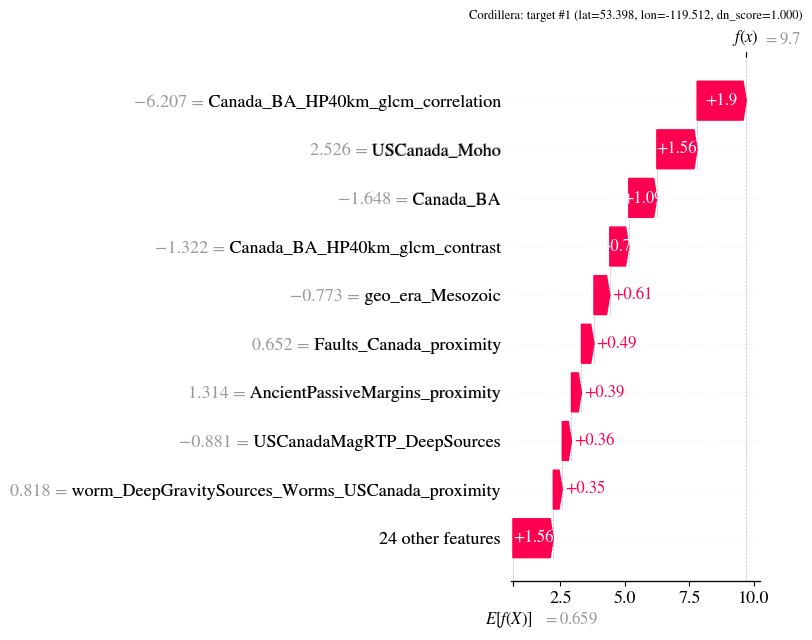

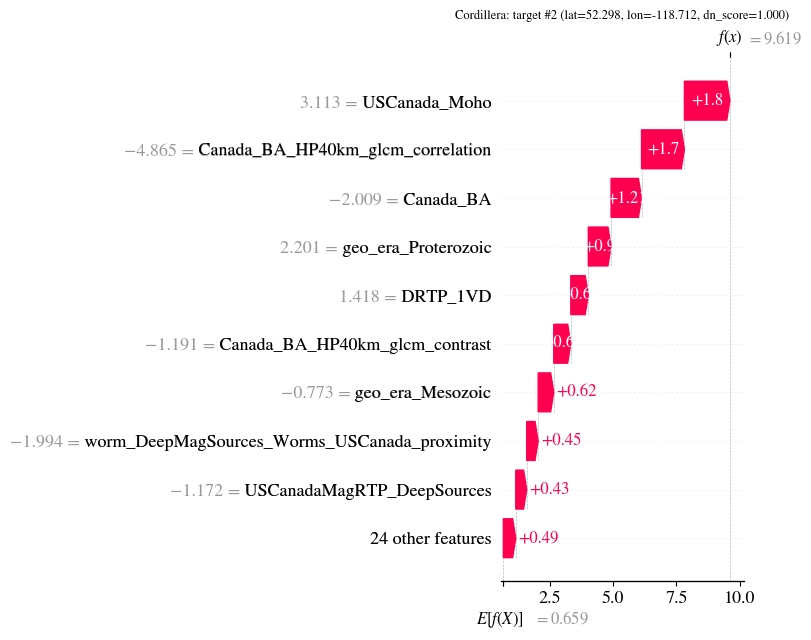

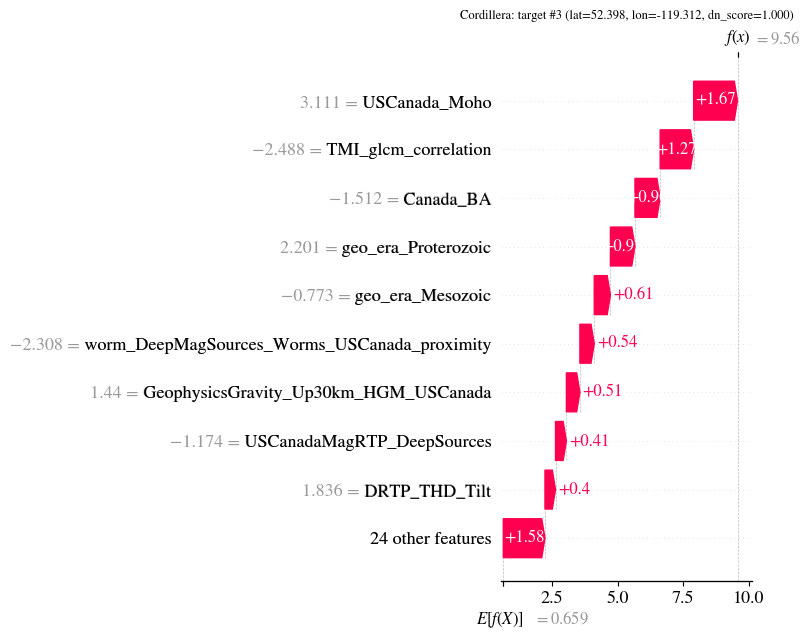

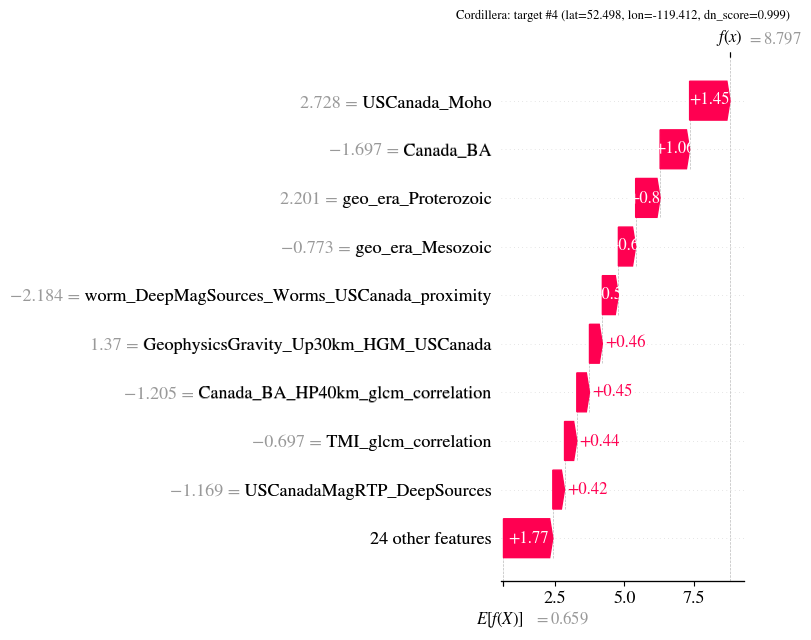

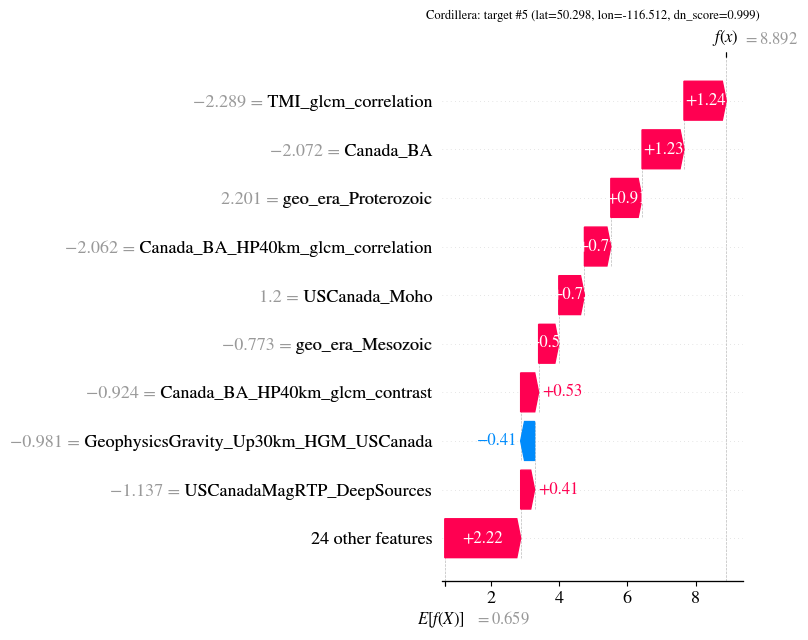

[Grenville] local explanation for top 5 candidate targets (DeepExplainer):


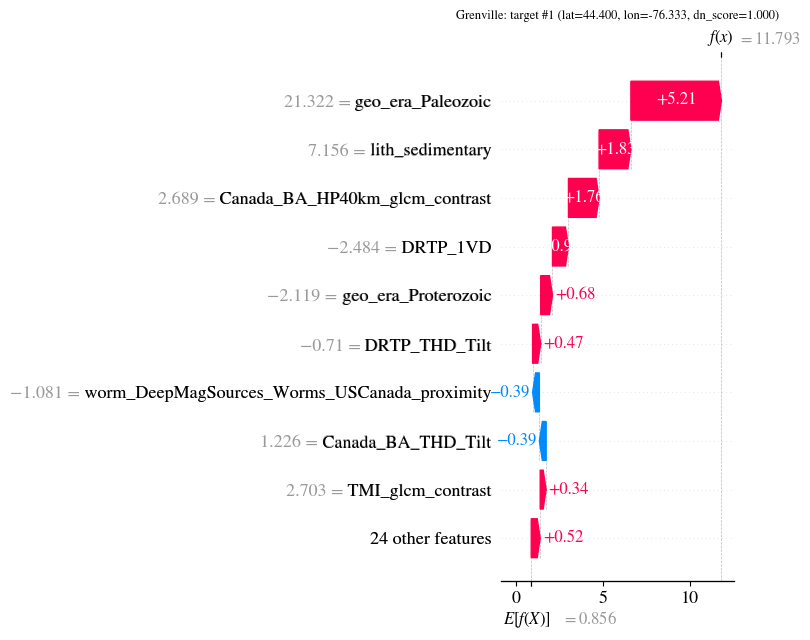

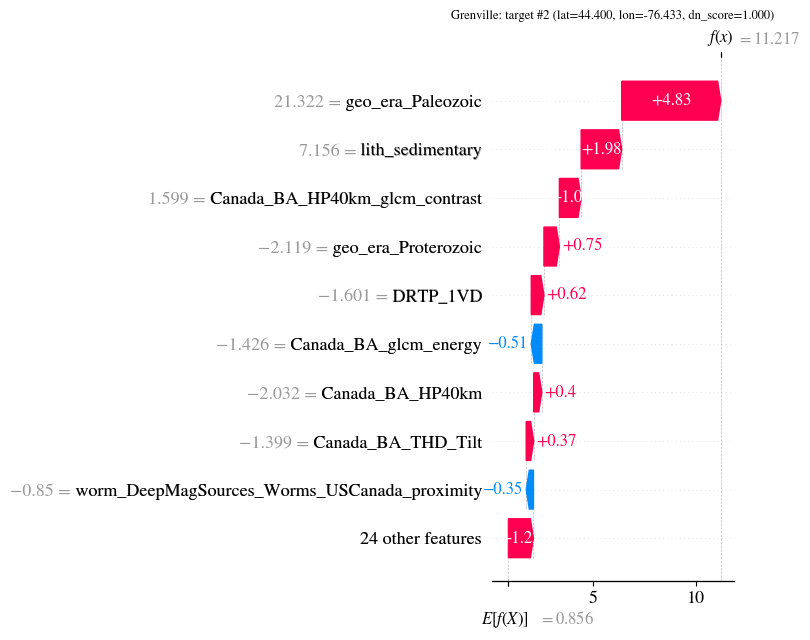

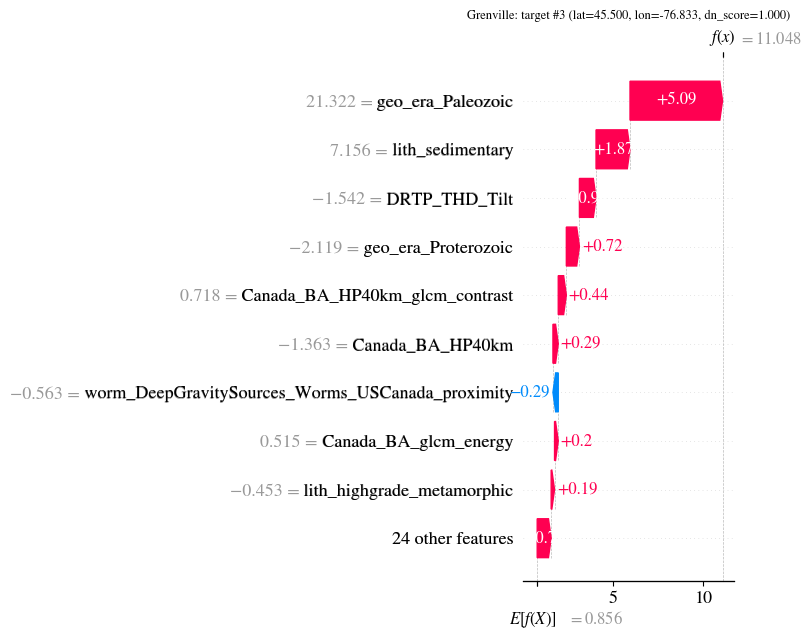

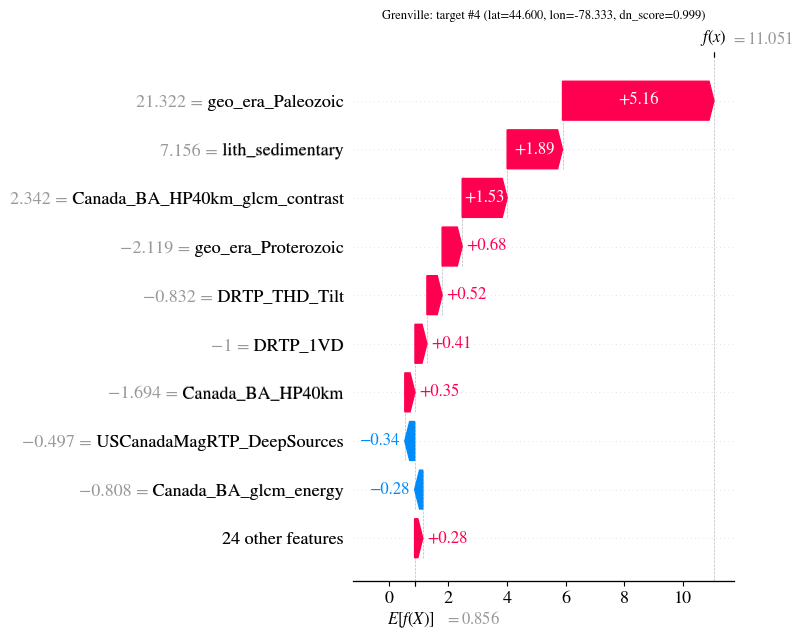

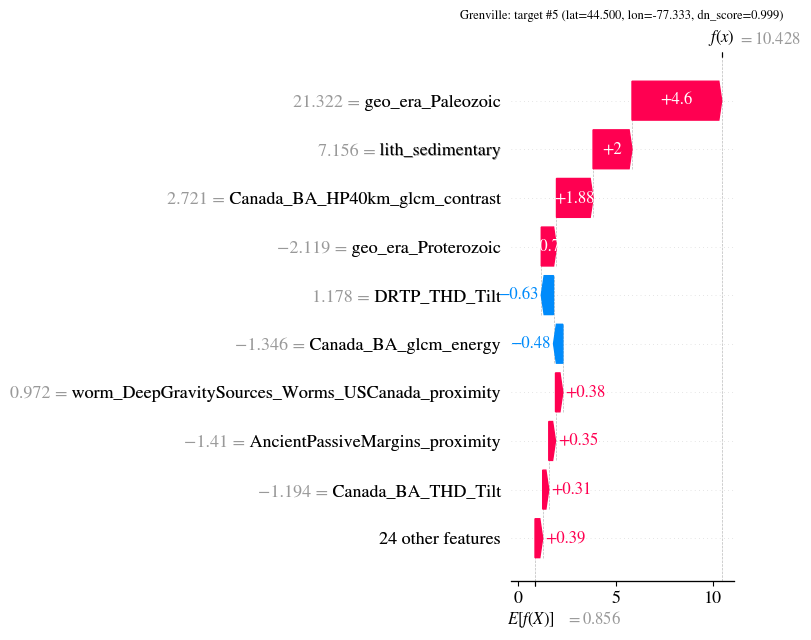

[Superior] local explanation for top 5 candidate targets (DeepExplainer):


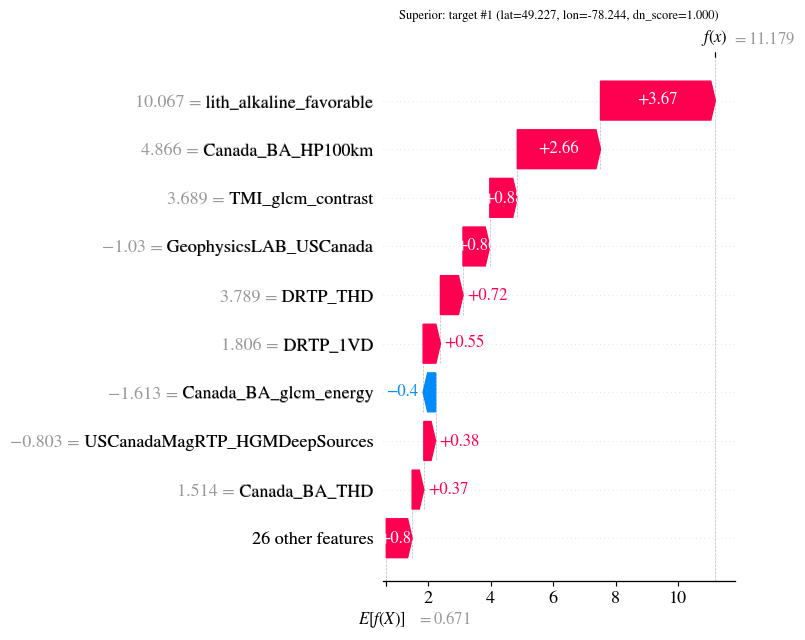

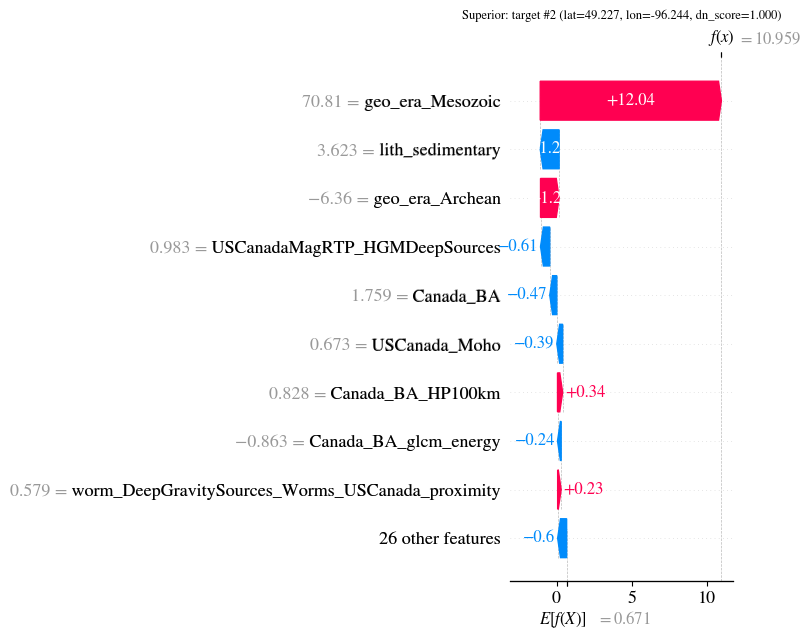

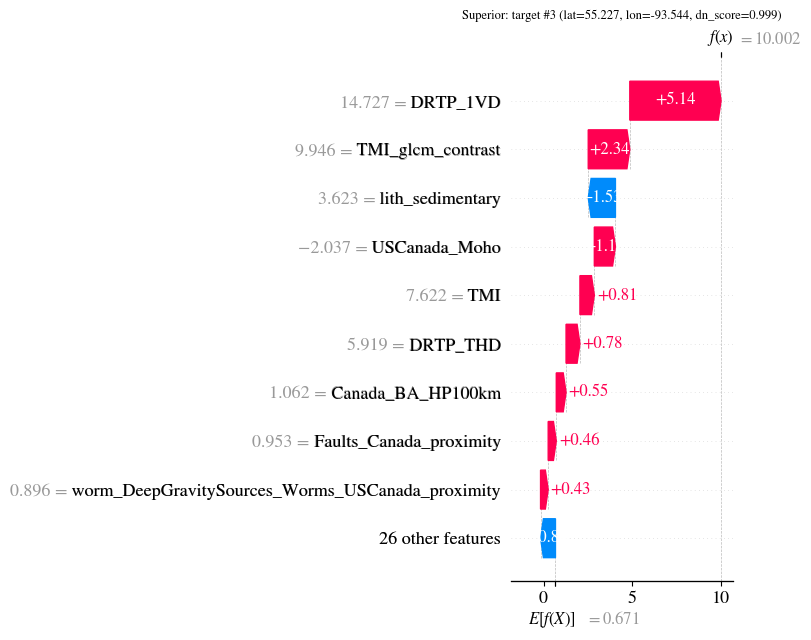

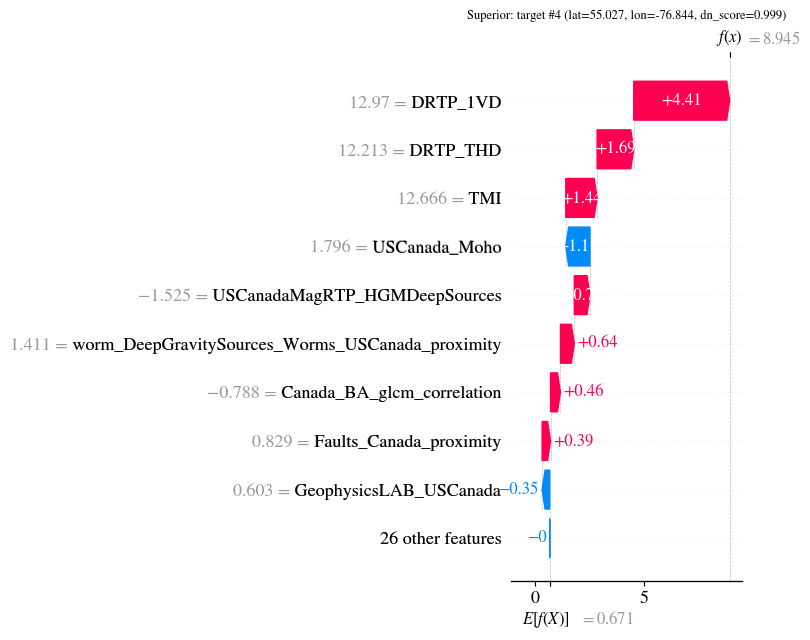

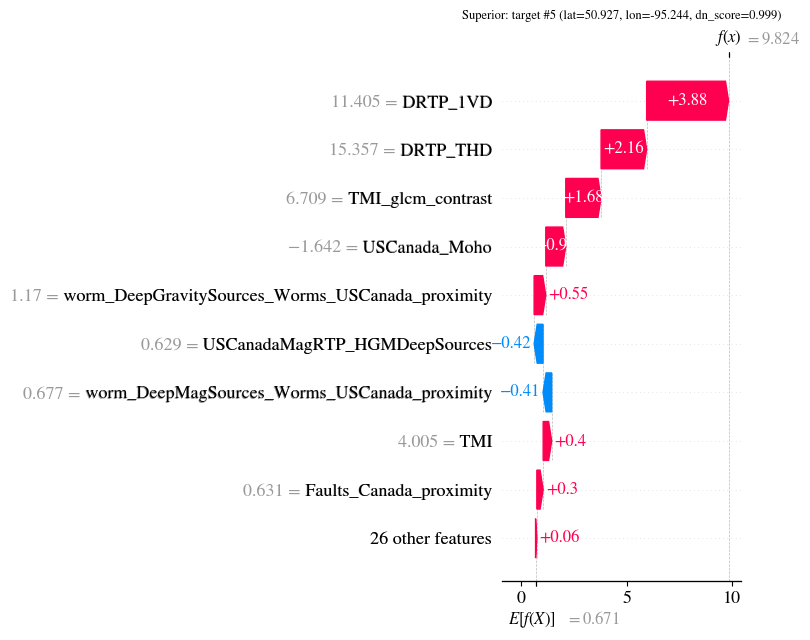

In [35]:
for name in SHAP_REGIONS:
    t = TRAINED[name]
    r = SHAP_RESULTS[name]
    top_targets = t.get('top_targets')
    if top_targets is None or len(top_targets) == 0:
        print(f'[{name}] no top_targets to explain -- skipping.')
        continue

    top_local = top_targets.sort_values('dn_score', ascending=False).head(5).reset_index(drop=True)
    pts_all = t['pts']
    top_rows = pts_all.merge(top_local[['lat', 'lon', 'dn_score']], on=['lat', 'lon'], how='inner')
    top_rows = top_rows.sort_values('dn_score', ascending=False).reset_index(drop=True)
    if len(top_rows) == 0:
        print(f'[{name}] could not match top_targets back to feature rows -- skipping.')
        continue

    X_top_raw, _, _ = get_raw_features(top_rows, feat_subset=r['feat_cols'])
    X_top_dn = t['dn_scaler'].transform(t['dn_imp'].transform(X_top_raw))

    shap_top, ev_top, method_top = explain_devnet(t['dn_ensemble'][0], r['X_bg_dn'], X_top_dn)
    print(f'[{name}] local explanation for top {len(top_rows)} candidate targets ({method_top}):')

    for i in range(len(top_rows)):
        exp = shap.Explanation(
            values=shap_top[i], base_values=ev_top,
            data=X_top_dn[i], feature_names=r['feat_cols'],
        )
        plt.figure()  # shap.plots.waterfall draws on the current axes rather
                       # than creating its own figure -- without this, it
                       # lands on top of whatever plot preceded it.
        shap.plots.waterfall(exp, show=False)
        plt.title(f"{name}: target #{i+1} (lat={top_rows.loc[i,'lat']:.3f}, "
                  f"lon={top_rows.loc[i,'lon']:.3f}, dn_score={top_rows.loc[i,'dn_score']:.3f})",
                  fontsize=9)
        plt.tight_layout()
        plt.savefig(os.path.join(SHAP_FIG_DIR, f'{name}_waterfall_target{i+1}.png'),
                    dpi=SHAP_FIG_DPI, bbox_inches='tight')
        plt.show()


## 13g. Single-Feature Ablation (Partial Predictive Power)

**Question:** how much predictive power does each input feature carry on
its own, independent of every other feature? SHAP (Section 13 above)
measures a feature's contribution *within* the full model, including
interactions with every other feature. Single-feature ablation asks the
complementary, simpler question: train a model on **only that one
feature** (plus the mandatory imputer) and see how far it gets alone --
the nonlinear-model analogue of a linear model's partial R². The two are
**not substitutes for each other**: a feature can rank high in SHAP (large
contribution inside the full model, working together with others) while
ranking low here (weak in isolation, only useful in combination), or the
reverse (independently informative on its own, but redundant with
something else the model already has, so SHAP discounts it inside the
full model). Disagreement between the two rankings is not a bug -- it is
exactly the interaction signal a linear partial-R² analogue can't see
either, and should be read as complementary evidence, never as one
overriding the other.

**Design:** for each region, for every feature in `REGION_FEATS[name]`
(the pruned set), train RF (`rf_shared_bg_fold_scorer_factory`) and DevNet
(`devnet_semisup_fold_scorer_factory`) on that feature ALONE, using the
exact same shared-background pools, CV folds, and `pooled_oof_eval`
protocol as the main experiment (Section 9) -- only the feature-matrix
width changes, from the full pruned set down to 1 column. Single 5-fold
`pooled_oof_eval` only (not repeated CV), and DevNet's restart count is
halved (`SINGLE_FEAT_DN_RESTARTS`) to keep this affordable across every
feature in every region.

Each region's table is printed against the main experiment's own
full-pruned-model AUC/AP as a baseline: single-feature AP should generally
sit well below that baseline (a lone feature normally can't do what the
whole feature set does together), and any feature that gets close to or
exceeds the full-model baseline by itself is flagged explicitly -- that
would mean the feature is carrying most of the model's signal alone.

Single-feature ablation: single 5-fold pooled_oof_eval only (no repeated CV), DevNet restarts=2 (main experiment uses 5)

[Cordillera] single-feature ablation over 33 pruned features ...

=== [Cordillera] Single-feature ablation (33 features, sorted by RF_ap desc) ===
  Full-pruned-model baseline (Section 9): RF AUC=0.918 AP=0.393  |  DevNet AUC=0.875 AP=0.095
                                            feature  RF_auc  RF_ap  DevNet_auc  DevNet_ap
                                      USCanada_Moho  0.8418 0.3214      0.7761     0.0400
                         USCanadaMagRTP_DeepSources  0.5936 0.1190      0.7535     0.0328
                                geo_era_Proterozoic  0.7203 0.0279      0.7203     0.0279
              GeophysicsGravity_Up30km_HGM_USCanada  0.5718 0.0248      0.7122     0.0205
   worm_DeepGravitySources_Worms_USCanada_proximity  0.5460 0.0247      0.5818     0.0125
                                   Canada_BA_HP40km  0.5541 0.0150      0.4514     0.0082
       

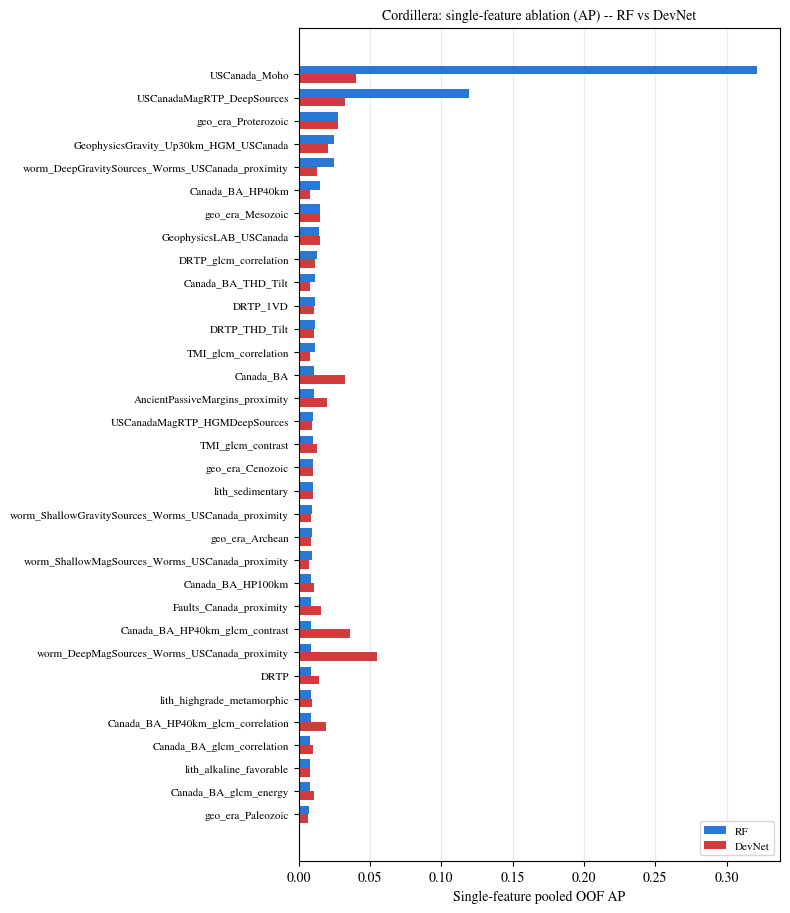

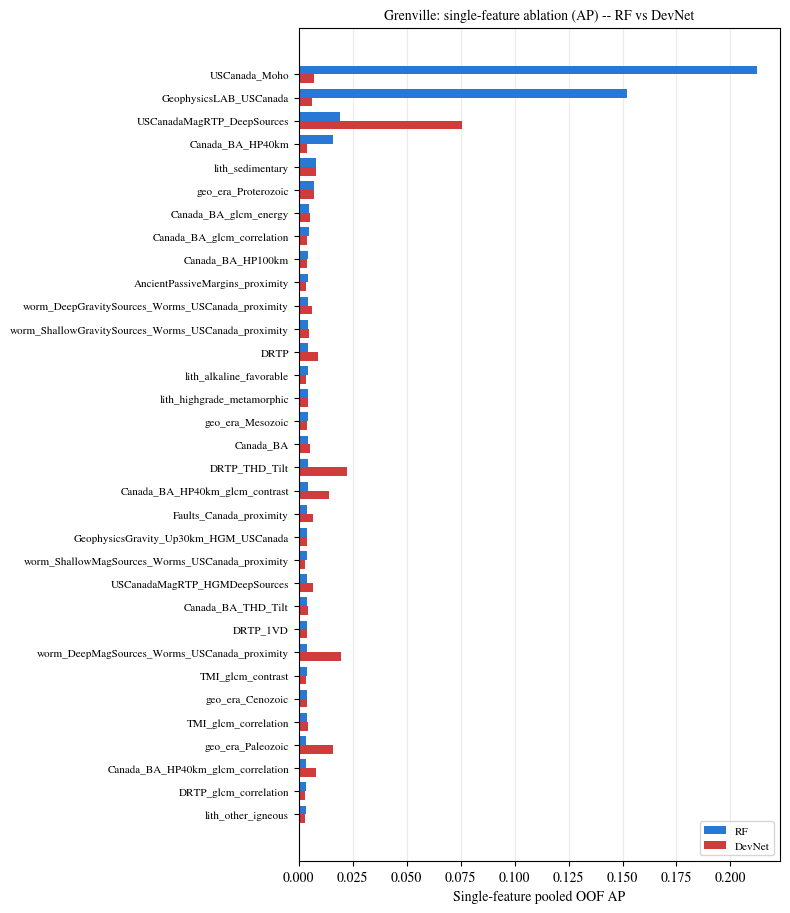

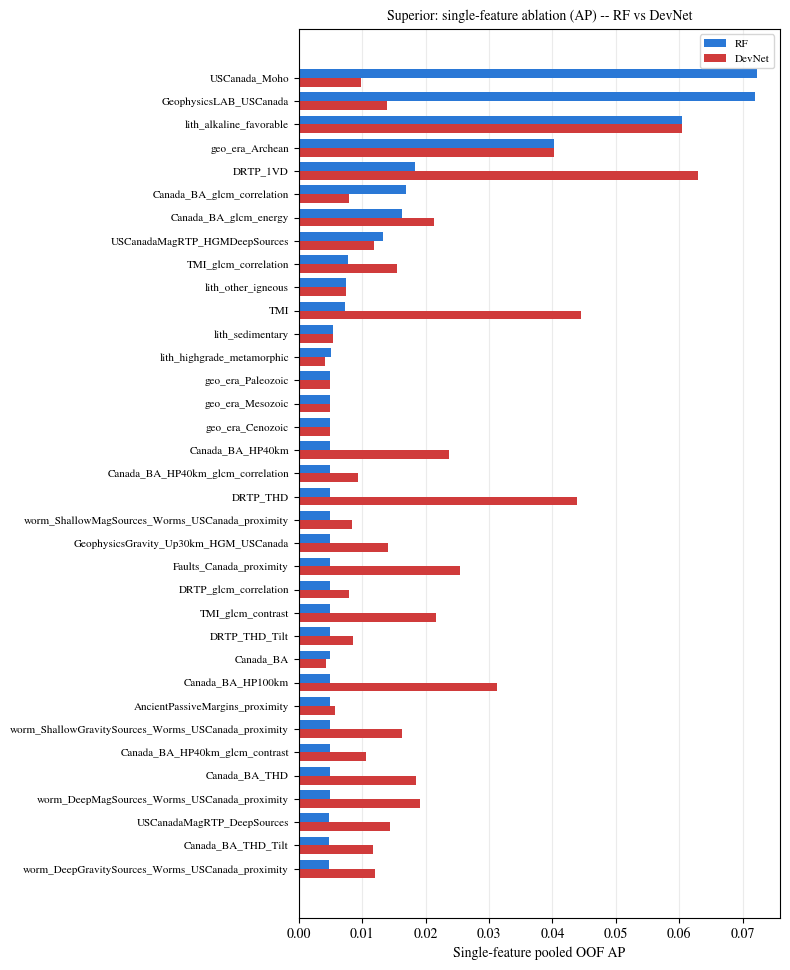

In [36]:
SINGLE_FEAT_DN_RESTARTS = max(1, DN_RESTARTS // 2)
print(f'Single-feature ablation: single 5-fold pooled_oof_eval only (no repeated CV), '
     f'DevNet restarts={SINGLE_FEAT_DN_RESTARTS} (main experiment uses {DN_RESTARTS})')

SINGLE_FEAT_RESULTS = {}   # name -> DataFrame(feature, RF_auc, RF_ap, DevNet_auc, DevNet_ap)

for name in RUN_REGIONS:
    pts         = TRAINED[name]['pts']
    feat_cols   = REGION_FEATS[name]
    model_cfg   = TRAINED[name]['model_cfg']

    pts_labeled   = pts[pts['pool'].isin(['positive', 'eval_neg'])].reset_index(drop=True)
    pts_unlabeled = pts[pts['pool'] == 'train_unlabeled'].reset_index(drop=True)

    print(f'\n[{name}] single-feature ablation over {len(feat_cols)} pruned features ...')
    rows = []
    for feat in feat_cols:
        X_lab,   y, _ = get_raw_features(pts_labeled,   feat_subset=[feat])
        X_unlab, _, _ = get_raw_features(pts_unlabeled, feat_subset=[feat])

        rf_scorer = rf_shared_bg_fold_scorer_factory(X_unlab)
        dn_scorer = devnet_semisup_fold_scorer_factory(
            X_unlab, model_cfg=model_cfg, restarts=SINGLE_FEAT_DN_RESTARTS)

        rf_auc, rf_ap, _ = pooled_oof_eval(X_lab, y, rf_scorer)
        dn_auc, dn_ap, _ = pooled_oof_eval(X_lab, y, dn_scorer)

        rows.append({'feature': feat, 'RF_auc': rf_auc, 'RF_ap': rf_ap,
                     'DevNet_auc': dn_auc, 'DevNet_ap': dn_ap})

    df = pd.DataFrame(rows).sort_values('RF_ap', ascending=False).reset_index(drop=True)
    assert len(df) == len(feat_cols), \
        f'[{name}] expected {len(feat_cols)} rows, got {len(df)} -- some feature was skipped'
    SINGLE_FEAT_RESULTS[name] = df

    ref_rf_auc = RESULTS[name]['RF']['pruned']['oof_auc']
    ref_rf_ap  = RESULTS[name]['RF']['pruned']['oof_ap']
    ref_dn_auc = RESULTS[name]['DevNet(deviation)']['pruned']['oof_auc']
    ref_dn_ap  = RESULTS[name]['DevNet(deviation)']['pruned']['oof_ap']

    print(f'\n=== [{name}] Single-feature ablation ({len(feat_cols)} features, sorted by RF_ap desc) ===')
    print(f'  Full-pruned-model baseline (Section 9): '
         f'RF AUC={ref_rf_auc:.3f} AP={ref_rf_ap:.3f}  |  DevNet AUC={ref_dn_auc:.3f} AP={ref_dn_ap:.3f}')
    pd.set_option('display.width', 160)
    print(df.round(4).to_string(index=False))

    close_or_exceeds = df[(df['RF_ap'] >= 0.9 * ref_rf_ap) | (df['DevNet_ap'] >= 0.9 * ref_dn_ap)]
    if len(close_or_exceeds):
        print(f'\n  FLAG -- feature(s) whose single-feature AP is within 90% of (or exceeds) the '
             f'full-pruned-model baseline (i.e. carrying most of the signal alone):')
        for _, r in close_or_exceeds.iterrows():
            flags = []
            if r['RF_ap'] >= ref_rf_ap:
                flags.append(f"RF_ap={r['RF_ap']:.3f} >= baseline {ref_rf_ap:.3f}")
            elif r['RF_ap'] >= 0.9 * ref_rf_ap:
                flags.append(f"RF_ap={r['RF_ap']:.3f} within 90% of baseline {ref_rf_ap:.3f}")
            if r['DevNet_ap'] >= ref_dn_ap:
                flags.append(f"DevNet_ap={r['DevNet_ap']:.3f} >= baseline {ref_dn_ap:.3f}")
            elif r['DevNet_ap'] >= 0.9 * ref_dn_ap:
                flags.append(f"DevNet_ap={r['DevNet_ap']:.3f} within 90% of baseline {ref_dn_ap:.3f}")
            print(f"    {r['feature']}: " + '; '.join(flags))
    else:
        print(f'\n  No single feature approaches the full-model baseline -- consistent with the '
             f'model relying on combinations/interactions of features, not one dominant signal.')

print('\n=== Reminder: single-feature ablation vs SHAP -- complementary, not interchangeable ===')
print('Single-feature ablation evaluates each feature in total isolation (no interactions), so its')
print('ranking need NOT match SHAP importance (which credits a feature for its contribution inside the')
print('full model, including interaction effects). Disagreement between the two is expected and itself')
print('informative -- it is exactly the interaction signal a linear partial-R^2 analogue cannot see either.')


def plot_single_feature_ap(name, df):
    """Horizontal bar chart, one figure per region (features differ in
    number/identity per region, so a single shared-axis multi-panel figure
    isn't meaningful) -- RF vs DevNet single-feature AP side by side, same
    layout convention as plot_global_importance_comparison (Section 13c).
    """
    df_sorted = df.sort_values('RF_ap', ascending=True)  # ascending -> highest ends up at top after invert
    y = np.arange(len(df_sorted))
    h = 0.38
    fig, ax = plt.subplots(figsize=(8, max(4, len(df_sorted) * 0.28)))
    ax.barh(y + h / 2, df_sorted['RF_ap'],     height=h, color='#2a78d6', label='RF')
    ax.barh(y - h / 2, df_sorted['DevNet_ap'], height=h, color='#d03b3b', label='DevNet')
    ax.set_yticks(y); ax.set_yticklabels(df_sorted['feature'], fontsize=8)
    ax.set_xlabel('Single-feature pooled OOF AP')
    ax.set_title(f'{name}: single-feature ablation (AP) -- RF vs DevNet', fontsize=10)
    ax.legend(fontsize=8)
    ax.grid(axis='x', alpha=0.25); ax.set_axisbelow(True)
    plt.tight_layout()
    plt.show()


for name in RUN_REGIONS:
    plot_single_feature_ap(name, SINGLE_FEAT_RESULTS[name])

## 14. Label-Confidence Stratification — Does RF Memorize Low-Confidence Positives?

**Question:** RF and DevNet(deviation) often *look* very different in how
confidently they score a positive — RF tends to score essentially every known
positive high, including the lowest-confidence `Occurrence` records, while
DevNet visibly deprioritizes some of them. Is that a real, measurable
pattern, or just an impression from staring at the prediction maps?

**Hypothesis:** RF discriminatively fits `positive` vs. `eval_neg` and can
simply memorize every training positive regardless of how weak its
underlying evidence is (`Occurrence` is, by the Hofstra et al. (2021)
definition this notebook's positive tables already use, the *lowest*-confidence
of the three classes — `Deposit/Prospect` > `Showing` > `Occurrence`, see
`DEP_TYPE_ORDER` / `COLOR_DEP_TYPE` in Section 12). DevNet never gets a
curated negative class to discriminate against; it only learns what the
unlabeled background typically looks like and scores deviation from it, so a
weak/ambiguous `Occurrence` point that doesn't stand out geophysically has no
mechanism forcing it to score high. If that's right, RF should score all
three occurrence-type groups about equally high, while DevNet's scores should
fall off from `Deposit/Prospect` to `Showing` to `Occurrence`.

**This section only reads already-produced artifacts** (`TRAINED`, `REGIONS`,
the fold-scorer functions from Sections 7-9, and `SHAP_RESULTS` from Section
13 if it was run) and adds analysis on top of them — it does not change
`make_points`, `build_region`, `pooled_oof_eval`, `repeated_pooled_auc`,
`rf_fold_scorer`, `devnet_semisup_fold_scorer_factory`, or any training
hyperparameter.

**Why this must use out-of-fold (OOF) scores, never the production models'
scores:** `TRAINED[name]['rf_model']` and `TRAINED[name]['dn_ensemble']` were
both *fit on every positive*, `Occurrence` included. Scoring positives with
those production models would just show RF "confidently" recognizing every
point it was trained on — that's training-set recall, not evidence about
memorization vs. generalization, and it would erase exactly the effect this
section is trying to measure. The question is "when a positive is held out
and the model has never seen it, does its confidence tier still predict how
it's scored?" — which is what OOF scoring answers and production-model
scoring cannot. Do not substitute production/training scores here.

### 14a. Occurrence-Type Labels + Repeated-CV OOF Scores (identical folds for RF and DevNet)

`get_positive_occurrence_types` re-reads each region's raw positive CSV
(`REGIONS[name]['dep']`, the same file `predict_grid`/`_prosp_panel` already
read in Section 12 to color the known-deposit star markers) and
auto-detects the occurrence-type column (`dep_type` in this dataset; also
tries `occurrence_type` / `OccurrenceType` / `type` / any column containing
"type" as a fallback, so this keeps working if the source CSV's column name
ever changes). Matching to a positive's `lat`/`lon` is by exact coordinate
(rounded to 1e-6 degrees for float safety) — those coordinates came from
this same CSV via `make_points`, unmodified, so the match is exact and any
miss is printed as a warning rather than silently dropped.

`repeated_pooled_oof_scores` is a thin variant of the existing
`repeated_pooled_auc` (Section 6): identical `RepeatedStratifiedKFold`
splitting, identical per-fold `rankdata(va_scores) / len(va_scores)`
within-fold percentile scoring — the only difference is it returns each
point's **out-of-fold score averaged across the `CV_N_REPEATS` repeats**
instead of collapsing straight to a pooled AUC. Calling it once with
`rf_fold_scorer` and once with `devnet_semisup_fold_scorer_factory` on the
exact same `(X, y, seed=RANDOM_SEED)` produces scores from **identical CV
folds** for both models — the split sequence depends only on `y` and the
seed, never on the scorer — which is what makes the RF-vs-DevNet comparison
below valid. Both use the region's **pruned** feature set, the same one the
production models and Section 9's headline numbers use.

`top_decile_flags` marks the top 10% of scores within whatever array it's
given — used below against each region's whole labeled pool
(`positive + eval_neg`) to define "hit rate".

Runs over `RUN_REGIONS`, so `FAST_MODE` controls how many regions this costs
compute on, exactly as it does in Sections 9 and 13. No new randomness is
introduced — everything reuses `CV_N_SPLITS` / `CV_N_REPEATS` / `RANDOM_SEED`.

In [37]:
_OCC_TYPE_COL_CANDIDATES = ['dep_type', 'occurrence_type', 'OccurrenceType', 'type', 'Type', 'DepType']

def _find_occurrence_type_col(df):
    """Auto-detect the occurrence-type column in a positive-sample CSV."""
    lower_map = {c.lower(): c for c in df.columns}
    for cand in _OCC_TYPE_COL_CANDIDATES:
        if cand.lower() in lower_map:
            return lower_map[cand.lower()]
    type_cols = [c for c in df.columns if 'type' in c.lower()]
    if len(type_cols) == 1:
        return type_cols[0]
    raise ValueError(f'Could not auto-detect an occurrence-type column among {list(df.columns)}')


def get_positive_occurrence_types(cfg, pos_tbl):
    """Attach each row of pos_tbl (lat/lon) its occurrence-type label
    (deposit/showing/occurrence confidence tier) by exact-coordinate match
    against the region's raw positive CSV (cfg['dep'])."""
    dep = pd.read_csv(cfg['dep']).dropna(subset=['Latitude', 'Longitude'])
    type_col = _find_occurrence_type_col(dep)
    dep_key = list(zip(np.round(dep['Latitude'].values, 6), np.round(dep['Longitude'].values, 6)))
    dep_lookup = dict(zip(dep_key, dep[type_col].values))

    pos_key = list(zip(np.round(pos_tbl['lat'].values, 6), np.round(pos_tbl['lon'].values, 6)))
    occ_type = np.array([dep_lookup.get(k, 'Unknown') for k in pos_key], dtype=object)
    n_unmatched = int((occ_type == 'Unknown').sum())
    if n_unmatched:
        print(f"    WARNING: {n_unmatched}/{len(pos_tbl)} positives could not be matched to an "
              f"occurrence-type label by lat/lon -- check {cfg['dep']!r} for coordinate drift.")
    return occ_type, type_col


def repeated_pooled_oof_scores(X_raw, y, fold_scorer, n_splits=CV_N_SPLITS,
                               n_repeats=CV_N_REPEATS, seed=RANDOM_SEED):
    """Same RepeatedStratifiedKFold(seed=seed) split sequence as
    repeated_pooled_auc, but returns each point's out-of-fold score averaged
    over all n_repeats repeats (instead of collapsing to a pooled AUC).
    Calling this with the same (X_raw, y, seed) for two different
    fold_scorers guarantees both see identical folds -- required for the
    RF-vs-DevNet comparison below to be apples-to-apples. NEVER substitute a
    production/training score here -- see the Section 14 intro."""
    rskf = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=seed)
    n = len(y)
    score_sum = np.zeros(n)
    score_cnt = np.zeros(n)
    for k, (tr_idx, va_idx) in enumerate(rskf.split(X_raw, y)):
        va_scores = fold_scorer(X_raw[tr_idx], y[tr_idx], X_raw[va_idx], seed_counter=k)
        score_sum[va_idx] += rankdata(va_scores) / len(va_scores)
        score_cnt[va_idx] += 1
    return score_sum / score_cnt


def top_decile_flags(oof_scores):
    """True where oof_scores ranks in the top 10% of the WHOLE array passed
    in (i.e. relative to the region's full labeled pool, positives + eval_neg
    pooled together) -- this is what 'hit rate' means below."""
    pct = rankdata(oof_scores) / len(oof_scores)
    return pct >= 0.90

print('Section 14 helpers ready.')

Section 14 helpers ready.


Run the repeated-CV OOF scoring for every region in `RUN_REGIONS`, using each
region's pruned feature set and production `model_cfg` (`TRAINED[name]`),
then attach each positive's occurrence-type label.

In [38]:
STRAT_POINTS = {}   # region -> DataFrame of per-positive OOF scores + occurrence_type

for name in RUN_REGIONS:
    t   = TRAINED[name]
    cfg = REGIONS[name]
    pts_all     = t['pts']
    feat_cols   = t['feat_cols']            # region's pruned feature set (production model's own)
    model_cfg   = t['model_cfg']

    pts_labeled   = pts_all[pts_all['pool'].isin(['positive', 'eval_neg'])].reset_index(drop=True)
    pts_unlabeled = pts_all[pts_all['pool'] == 'train_unlabeled'].reset_index(drop=True)

    X_lab,   y_lab, _ = get_raw_features(pts_labeled,   feat_subset=feat_cols)
    X_unlab, _,     _ = get_raw_features(pts_unlabeled, feat_subset=feat_cols)

    print(f'[{name}] repeated-CV OOF scoring ({CV_N_SPLITS}-fold x {CV_N_REPEATS} repeats, '
          f'IDENTICAL folds for RF and DevNet) ...')
    oof_rf = repeated_pooled_oof_scores(X_lab, y_lab, rf_fold_scorer, seed=RANDOM_SEED)
    dn_scorer = devnet_semisup_fold_scorer_factory(X_unlab, model_cfg=model_cfg)
    oof_dn = repeated_pooled_oof_scores(X_lab, y_lab, dn_scorer, seed=RANDOM_SEED)

    top10_rf = top_decile_flags(oof_rf)
    top10_dn = top_decile_flags(oof_dn)

    pos_mask = (y_lab == 1)
    pos_tbl  = pts_labeled[pos_mask].reset_index(drop=True)
    occ_type, type_col_used = get_positive_occurrence_types(cfg, pos_tbl)

    STRAT_POINTS[name] = pd.DataFrame({
        'region':          name,
        'lat':             pos_tbl['lat'].values,
        'lon':             pos_tbl['lon'].values,
        'occurrence_type': occ_type,
        'rf_oof_score':    oof_rf[pos_mask],
        'rf_top10pct':     top10_rf[pos_mask],
        'dn_oof_score':    oof_dn[pos_mask],
        'dn_top10pct':     top10_dn[pos_mask],
    })
    print(f"  [{name}] occurrence-type column detected: {type_col_used!r}  "
          f"counts: {STRAT_POINTS[name]['occurrence_type'].value_counts().to_dict()}")

STRAT_POSITIVES = (pd.concat(STRAT_POINTS.values(), ignore_index=True)
                   if STRAT_POINTS else pd.DataFrame())
print(f'\nTotal positives with OOF scores across {len(STRAT_POINTS)} region(s): {len(STRAT_POSITIVES)}')

[Cordillera] repeated-CV OOF scoring (5-fold x 6 repeats, IDENTICAL folds for RF and DevNet) ...
  [Cordillera] occurrence-type column detected: 'dep_type'  counts: {'Showing': 17, 'Occurrence': 8, 'Deposit/Prospect': 2}
[Grenville] repeated-CV OOF scoring (5-fold x 6 repeats, IDENTICAL folds for RF and DevNet) ...
  [Grenville] occurrence-type column detected: 'dep_type'  counts: {'Occurrence': 5, 'Showing': 5, 'Deposit/Prospect': 2}
[Superior] repeated-CV OOF scoring (5-fold x 6 repeats, IDENTICAL folds for RF and DevNet) ...
  [Superior] occurrence-type column detected: 'dep_type'  counts: {'Occurrence': 8, 'Showing': 4, 'Deposit/Prospect': 3}

Total positives with OOF scores across 3 region(s): 54


### 14b. Stratified Hit-Rate Table

For each occurrence-type group (`Deposit/Prospect` / `Showing` /
`Occurrence`), reports `n`, each model's mean OOF score, and each model's
**hit rate** — the fraction of that group's positives whose OOF score lands
in the top 10% of the region's whole labeled pool (`top_decile_flags` above,
computed against `positive + eval_neg` pooled together, i.e. "would this
point have ranked among the top-decile prospectivity scores when it was held
out"). One table per region, plus one for all three regions' positives
pooled together.

Expected under the hypothesis: RF's hit rate is high and similar across all
three groups (it memorized them at training time regardless of confidence
tier); DevNet's hit rate decreases `Deposit/Prospect > Showing > Occurrence`.

In [39]:
def stratified_hitrate_table(df, order=DEP_TYPE_ORDER):
    rows = []
    for grp in order:
        sub = df[df['occurrence_type'] == grp]
        if len(sub) == 0:
            continue
        rows.append({
            'occurrence_type':         grp,
            'n':                       len(sub),
            'RF_oof_mean':             sub['rf_oof_score'].mean(),
            'RF_hitrate_top10pct':     sub['rf_top10pct'].mean(),
            'DevNet_oof_mean':         sub['dn_oof_score'].mean(),
            'DevNet_hitrate_top10pct': sub['dn_top10pct'].mean(),
        })
    return pd.DataFrame(rows)

pd.set_option('display.width', 160)
STRAT_TABLES = {}
for name in RUN_REGIONS:
    STRAT_TABLES[name] = stratified_hitrate_table(STRAT_POINTS[name])
    print(f'\n[{name}] stratified hit-rate table:')
    print(STRAT_TABLES[name].round(3).to_string(index=False))

STRAT_TABLE_COMBINED = stratified_hitrate_table(STRAT_POSITIVES)
print('\n[All regions combined] stratified hit-rate table:')
print(STRAT_TABLE_COMBINED.round(3).to_string(index=False))


[Cordillera] stratified hit-rate table:
 occurrence_type  n  RF_oof_mean  RF_hitrate_top10pct  DevNet_oof_mean  DevNet_hitrate_top10pct
Deposit/Prospect  2        0.823                0.500            0.762                    0.000
         Showing 17        0.951                0.941            0.940                    0.882
      Occurrence  8        0.794                0.625            0.743                    0.375

[Grenville] stratified hit-rate table:
 occurrence_type  n  RF_oof_mean  RF_hitrate_top10pct  DevNet_oof_mean  DevNet_hitrate_top10pct
Deposit/Prospect  2        0.943                  1.0            0.876                      0.5
         Showing  5        0.950                  0.8            0.815                      0.6
      Occurrence  5        0.638                  0.4            0.463                      0.2

[Superior] stratified hit-rate table:
 occurrence_type  n  RF_oof_mean  RF_hitrate_top10pct  DevNet_oof_mean  DevNet_hitrate_top10pct
Deposit/Prospect

### 14c. Stratified Boxplots (paper figure)

RF (blue) vs. DevNet (red) OOF score by occurrence-type tier, one figure per
region and one for all three regions combined. Individual points are
jittered on top of each box since several groups have single-digit `n`
(especially `Deposit/Prospect` — see the counts printed above); with that
few points a boxplot alone can be misleading, so every underlying point stays
visible. The dashed line marks the top-10% threshold used for the hit-rate
table above. Colors match Section 13's RF-vs-DevNet SHAP comparison plots
(`#2a78d6` / `#d03b3b`) for visual consistency across the notebook's figures.

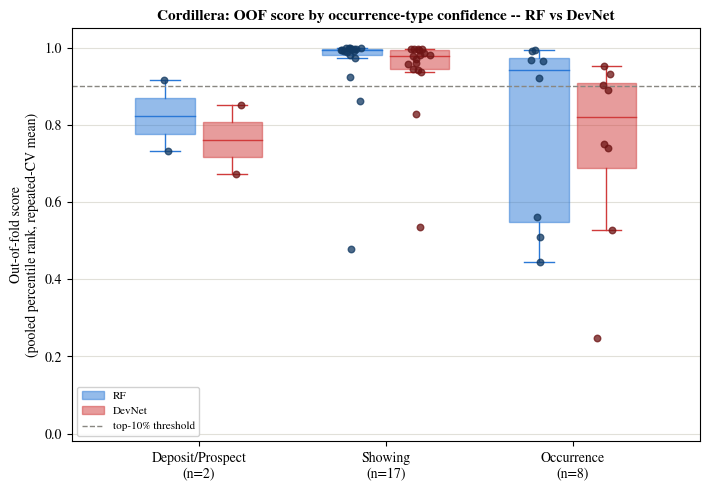

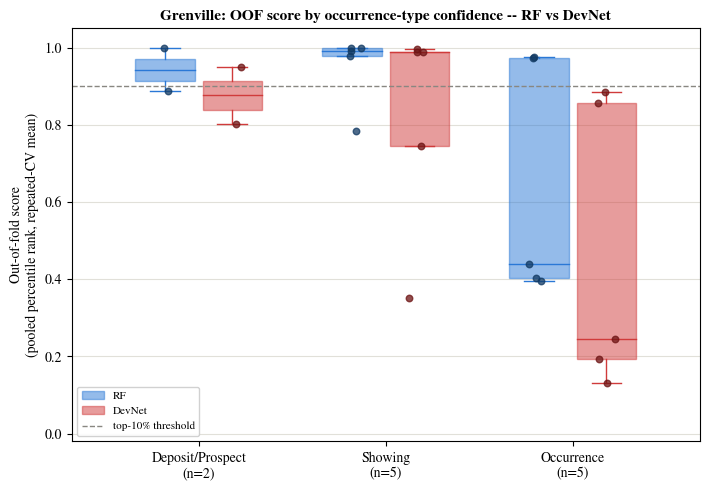

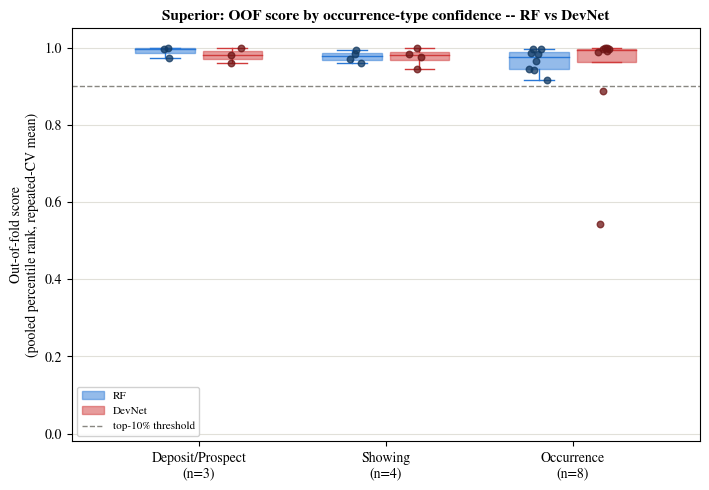

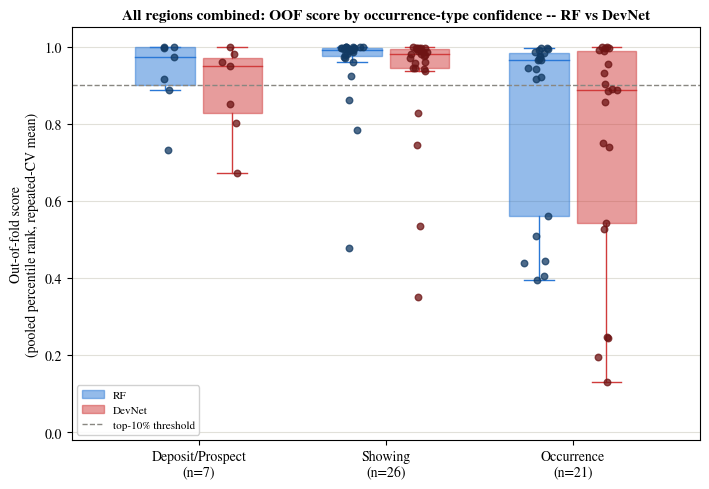

In [40]:
def plot_stratified_boxplot(df, title, order=DEP_TYPE_ORDER):
    order = [g for g in order if (df['occurrence_type'] == g).any()]
    if not order:
        print(f'  [{title}] no occurrence-type groups present -- skipping plot.')
        return

    pos_rf = np.arange(len(order)) - 0.18
    pos_dn = np.arange(len(order)) + 0.18
    rf_data = [df.loc[df['occurrence_type'] == g, 'rf_oof_score'].values for g in order]
    dn_data = [df.loc[df['occurrence_type'] == g, 'dn_oof_score'].values for g in order]

    fig, ax = plt.subplots(figsize=(max(6, len(order) * 2.4), 5))
    bp_rf = ax.boxplot(rf_data, positions=pos_rf, widths=0.32, patch_artist=True, showfliers=False)
    bp_dn = ax.boxplot(dn_data, positions=pos_dn, widths=0.32, patch_artist=True, showfliers=False)
    for box in bp_rf['boxes']:
        box.set(facecolor='#2a78d6', alpha=0.5, edgecolor='#2a78d6')
    for box in bp_dn['boxes']:
        box.set(facecolor='#d03b3b', alpha=0.5, edgecolor='#d03b3b')
    for element in ['whiskers', 'caps', 'medians']:
        for line in bp_rf[element]:
            line.set(color='#2a78d6')
        for line in bp_dn[element]:
            line.set(color='#d03b3b')

    jitter_rng = np.random.RandomState(RANDOM_SEED)
    for i, g in enumerate(order):
        yv_rf = df.loc[df['occurrence_type'] == g, 'rf_oof_score'].values
        ax.scatter(jitter_rng.normal(pos_rf[i], 0.03, size=len(yv_rf)), yv_rf,
                  color='#123a63', s=22, alpha=0.75, zorder=5)
        yv_dn = df.loc[df['occurrence_type'] == g, 'dn_oof_score'].values
        ax.scatter(jitter_rng.normal(pos_dn[i], 0.03, size=len(yv_dn)), yv_dn,
                  color='#6e1414', s=22, alpha=0.75, zorder=5)

    ax.axhline(0.90, color='#898781', ls='--', lw=1)
    ax.set_xticks(np.arange(len(order)))
    ax.set_xticklabels([f'{g}\n(n={int((df["occurrence_type"] == g).sum())})' for g in order])
    ax.set_ylabel('Out-of-fold score\n(pooled percentile rank, repeated-CV mean)')
    ax.set_ylim(-0.02, 1.05)
    ax.set_title(title, fontsize=11, fontweight='bold')
    legend_handles = [
        mpatches.Patch(facecolor='#2a78d6', alpha=0.5, edgecolor='#2a78d6', label='RF'),
        mpatches.Patch(facecolor='#d03b3b', alpha=0.5, edgecolor='#d03b3b', label='DevNet'),
        plt.Line2D([0], [0], color='#898781', ls='--', lw=1, label='top-10% threshold'),
    ]
    ax.legend(handles=legend_handles, loc='lower left', fontsize=8, framealpha=0.9)
    ax.grid(axis='y', color='#e1e0d9', lw=0.8, zorder=0)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.show()

for name in RUN_REGIONS:
    plot_stratified_boxplot(STRAT_POINTS[name],
                            f'{name}: OOF score by occurrence-type confidence -- RF vs DevNet')

if len(STRAT_POSITIVES) > 0:
    plot_stratified_boxplot(STRAT_POSITIVES,
                            'All regions combined: OOF score by occurrence-type confidence -- RF vs DevNet')

### 14d. Mann-Whitney U Test — Occurrence vs. Deposit/Prospect

Non-parametric (no normality assumption, appropriate for these small `n`)
one-sided test of `H1: Deposit/Prospect OOF scores > Occurrence OOF scores`,
run separately for RF and for DevNet, per region and for the three regions
combined. Reports `U` and `p`. If either group has fewer than 3 points the
test is skipped and flagged as not testable rather than reporting a
misleadingly precise p-value off 1-2 points.

In [41]:
from scipy.stats import mannwhitneyu

def mannwhitney_deposit_vs_occurrence(df, score_col, label):
    dep = df.loc[df['occurrence_type'] == 'Deposit/Prospect', score_col].values
    occ = df.loc[df['occurrence_type'] == 'Occurrence',       score_col].values
    if len(dep) < 3 or len(occ) < 3:
        print(f'    {label}: n_deposit={len(dep)}, n_occurrence={len(occ)} -- '
              f'fewer than 3 in one group, skipping Mann-Whitney U (not testable).')
        return None
    U, p = mannwhitneyu(dep, occ, alternative='greater')  # H1: deposit scores > occurrence scores
    flag = '[SIGNIFICANT p<0.05]' if p < 0.05 else '[not significant]'
    print(f'    {label}: deposit(n={len(dep)}) vs occurrence(n={len(occ)})  '
          f'U={U:.1f}  p={p:.4f}  {flag}')
    return {'U': float(U), 'p': float(p), 'n_deposit': len(dep), 'n_occurrence': len(occ)}

STRAT_TESTS = {}
print('Mann-Whitney U, H1 = Deposit/Prospect OOF score > Occurrence OOF score (one-sided):')
for name in RUN_REGIONS:
    print(f'\n[{name}]')
    STRAT_TESTS[name] = {
        'RF':     mannwhitney_deposit_vs_occurrence(STRAT_POINTS[name], 'rf_oof_score', 'RF'),
        'DevNet': mannwhitney_deposit_vs_occurrence(STRAT_POINTS[name], 'dn_oof_score', 'DevNet'),
    }

print('\n[All regions combined]')
STRAT_TESTS['combined'] = {
    'RF':     mannwhitney_deposit_vs_occurrence(STRAT_POSITIVES, 'rf_oof_score', 'RF'),
    'DevNet': mannwhitney_deposit_vs_occurrence(STRAT_POSITIVES, 'dn_oof_score', 'DevNet'),
}

Mann-Whitney U, H1 = Deposit/Prospect OOF score > Occurrence OOF score (one-sided):

[Cordillera]
    RF: n_deposit=2, n_occurrence=8 -- fewer than 3 in one group, skipping Mann-Whitney U (not testable).
    DevNet: n_deposit=2, n_occurrence=8 -- fewer than 3 in one group, skipping Mann-Whitney U (not testable).

[Grenville]
    RF: n_deposit=2, n_occurrence=5 -- fewer than 3 in one group, skipping Mann-Whitney U (not testable).
    DevNet: n_deposit=2, n_occurrence=5 -- fewer than 3 in one group, skipping Mann-Whitney U (not testable).

[Superior]
    RF: deposit(n=3) vs occurrence(n=8)  U=20.0  p=0.0667  [not significant]
    DevNet: deposit(n=3) vs occurrence(n=8)  U=11.0  p=0.6205  [not significant]

[All regions combined]
    RF: deposit(n=7) vs occurrence(n=21)  U=94.0  p=0.1480  [not significant]
    DevNet: deposit(n=7) vs occurrence(n=21)  U=86.0  p=0.2621  [not significant]


### 14e. Auto-Generated One-Line Conclusion

Reads `STRAT_TESTS` above and prints, per region and for the combined pool,
one sentence stating whether the RF-memorizes / DevNet-is-robust hypothesis
is supported, contradicted, or untestable given the available `n` — the
sentence this section exists to produce for the write-up.

In [42]:
def _fmt_p(r):
    return f"p={r['p']:.4f}" if r is not None else 'not testable (n<3)'

print('=== Summary ===')
for name in list(RUN_REGIONS) + ['combined']:
    rf_r, dn_r = STRAT_TESTS[name]['RF'], STRAT_TESTS[name]['DevNet']
    rf_sig = (rf_r is not None) and (rf_r['p'] < 0.05)
    dn_sig = (dn_r is not None) and (dn_r['p'] < 0.05)

    if dn_sig and not rf_sig:
        verdict = (f'DevNet significantly down-weights low-confidence occurrence-type positives '
                  f'({_fmt_p(dn_r)}), while RF does not ({_fmt_p(rf_r)}), indicating RF memorizes '
                  f'low-quality labels whereas DevNet is robust to label noise.')
    elif dn_sig and rf_sig:
        verdict = (f'Both models significantly down-weight occurrence-type positives '
                  f'(RF {_fmt_p(rf_r)}, DevNet {_fmt_p(dn_r)}) -- the hypothesized RF/DevNet '
                  f'asymmetry is not supported here.')
    elif not dn_sig and not rf_sig:
        verdict = (f'Neither model shows a significant deposit-vs-occurrence gap '
                  f'(RF {_fmt_p(rf_r)}, DevNet {_fmt_p(dn_r)}) -- likely underpowered (small n) '
                  f'rather than evidence against the hypothesis.')
    else:
        verdict = (f'RF shows a significant gap ({_fmt_p(rf_r)}) but DevNet does not '
                  f'({_fmt_p(dn_r)}) -- the opposite of the hypothesized direction.')
    print(f'[{name}] {verdict}')

=== Summary ===
[Cordillera] Neither model shows a significant deposit-vs-occurrence gap (RF not testable (n<3), DevNet not testable (n<3)) -- likely underpowered (small n) rather than evidence against the hypothesis.
[Grenville] Neither model shows a significant deposit-vs-occurrence gap (RF not testable (n<3), DevNet not testable (n<3)) -- likely underpowered (small n) rather than evidence against the hypothesis.
[Superior] Neither model shows a significant deposit-vs-occurrence gap (RF p=0.0667, DevNet p=0.6205) -- likely underpowered (small n) rather than evidence against the hypothesis.
[combined] Neither model shows a significant deposit-vs-occurrence gap (RF p=0.1480, DevNet p=0.2621) -- likely underpowered (small n) rather than evidence against the hypothesis.


## 15. GIS Export (ArcGIS Pro, EPSG:3978)

Exports three layer types per region into `gis_export/`, all reprojected
to `PROJECTED_CRS` (EPSG:3978):

1. **A∧B sampleable-domain mask** (`SAMPLEABLE[name]['sampleable']`) →
   `{region}_sampleable_domain.tif`, uint8 (1=in domain, 0=out,
   nodata=255), written directly on `SAMPLEABLE[name]['ref_tf']` -- no
   resampling, this raster and the mask share the same pixel grid by
   construction (Section 3h).
2. **Positive (deposit) points** → `{region}_positives.gpkg`. Rebuilt
   from `cfg['dep']` + the same within-outline filter and
   `dedup_close_positives` call `make_points` uses, keeping the full
   original attribute set (`Name`, `dep_type`, ...) that `VERIFY_PTS`
   itself drops -- then checked to have exactly as many rows as
   `VERIFY_PTS[name]['label']==1` before export, so a silent divergence
   between the two dedup call sites would raise loudly rather than
   export a mismatched layer.
3. **Prediction surfaces** (`rf_proba`, `dn_proba`) →
   `{region}_RF_proba.tif` / `{region}_DevNet_proba.tif`, float32,
   nodata=NaN outside the domain. Section 12's `predict_grid` only ever
   evaluated an irregular, `GRID_DEG`-spaced point cloud restricted to
   the A∧B domain (saved to
   `{region}_prospectivity_combined_dedup.geojson`) -- never a raster on
   `ref_tf`'s grid -- so this reads that GeoJSON back, reprojects it to
   EPSG:3978, and linearly interpolates (`scipy.interpolate.griddata`,
   the same method `_prosp_panel` already uses for the notebook's own
   prospectivity-map figures) onto every `ref_tf` pixel center, then
   masks to the sampleable domain. **Requires Section 12 to have already
   run** for every region in `RUN_REGIONS` (the GeoJSON must exist on
   disk); regions missing it are skipped with a warning, not silently
   dropped.

In [43]:
import os
import rasterio
import geopandas as gpd
from rasterio.transform import xy as _rio_xy
from scipy.interpolate import griddata as _griddata_export

GIS_EXPORT_DIR = 'gis_export'
os.makedirs(GIS_EXPORT_DIR, exist_ok=True)


def export_domain_mask_tif(name):
    """SAMPLEABLE[name]['sampleable'] -> uint8 GeoTIFF, 1=in domain / 0=out,
    nodata=255 (declared for GIS-tool convention; the mask array itself
    has no true no-data cells -- every pixel in ref_shape is 0 or 1).
    """
    info = SAMPLEABLE[name]
    ref_tf, ref_crs, ref_shape, mask = info['ref_tf'], info['ref_crs'], info['ref_shape'], info['sampleable']
    # ref_crs was already resolved from the raster file itself when SAMPLEABLE was
    # built (Section 3h) -- gravity_ba is natively EPSG:3978, i.e. PROJECTED_CRS.
    # (Deliberately not re-parsing 'EPSG:3978' via CRS.from_user_input here: that
    # triggers a fresh GDAL proj.db EPSG lookup, which can fail on environments
    # with a mismatched/stale proj.db even though ref_crs itself is already fine.)
    arr = mask.astype(np.uint8)

    out_path = os.path.join(GIS_EXPORT_DIR, f'{name}_sampleable_domain.tif')
    with rasterio.open(out_path, 'w', driver='GTiff', height=ref_shape[0], width=ref_shape[1],
                       count=1, dtype='uint8', crs=ref_crs, transform=ref_tf,
                       nodata=255, compress='lzw') as dst:
        dst.write(arr, 1)
    print(f'  [{name}] domain mask ({arr.sum()}/{arr.size} px in-domain) -> {out_path}')


def export_positive_points_gpkg(name, cfg):
    """VERIFY_PTS[name][label==1], WITH attributes. VERIFY_PTS only carries
    lat/lon/label, so attributes (Name, dep_type, ...) are joined back from
    cfg['dep'] by matching coordinates -- deliberately NOT by independently
    re-deriving the positive set via a second `boundary.unary_union()` +
    `.within()` call: GEOS's boundary test on a point sitting almost
    exactly on the outline edge can flip between two separate calls due to
    floating-point noise in unary_union, so re-deriving risks silently
    diverging from VERIFY_PTS (observed in practice: 29 vs 28 on
    Cordillera). Joining back onto VERIFY_PTS's own already-computed,
    authoritative result sidesteps that entirely -- no second boundary
    test is ever run.
    """
    verify_pos = VERIFY_PTS[name][VERIFY_PTS[name]['label'] == 1].reset_index(drop=True)

    dep = pd.read_csv(cfg['dep']).dropna(subset=['Latitude', 'Longitude'])
    dep_gdf = gpd.GeoDataFrame(dep,
        geometry=gpd.points_from_xy(dep['Longitude'], dep['Latitude']), crs='EPSG:4326')

    dep_key    = list(zip(dep_gdf.geometry.y.round(6), dep_gdf.geometry.x.round(6)))
    verify_key = set(zip(verify_pos['lat'].round(6), verify_pos['lon'].round(6)))
    dep_in = dep_gdf[[k in verify_key for k in dep_key]].reset_index(drop=True)

    if len(dep_in) != len(verify_pos):
        raise RuntimeError(f'[{name}] positive-attribute join mismatch: '
                           f'{len(dep_in)} attribute rows matched vs {len(verify_pos)} in VERIFY_PTS -- '
                           f'lat/lon join failed for at least one positive.')

    dep_proj = dep_in.to_crs(PROJECTED_CRS)
    out_path = os.path.join(GIS_EXPORT_DIR, f'{name}_positives.gpkg')
    dep_proj.to_file(out_path, driver='GPKG', layer=f'{name}_positives')
    print(f'  [{name}] positives ({len(dep_proj)}, attrs={list(dep_in.columns)}) -> {out_path}')


def export_prediction_tifs(name):
    """rf_proba / dn_proba, read back from Section 12's saved GeoJSON
    (an irregular GRID_DEG point cloud, A∧B-domain-restricted), linearly
    interpolated onto the ref_tf pixel grid (same method _prosp_panel
    uses for its own figures), masked to the sampleable domain,
    nodata=NaN outside it.
    """
    info = SAMPLEABLE[name]
    ref_tf, ref_crs, ref_shape, mask = info['ref_tf'], info['ref_crs'], info['ref_shape'], info['sampleable']
    H, W = ref_shape

    geojson_path = f'{name}_prospectivity_combined_dedup.geojson'
    if not os.path.exists(geojson_path):
        print(f'  [{name}] WARNING: {geojson_path} not found -- run Section 12 (predict_grid) '
             f'for this region first. Skipping prediction-surface export.')
        return

    grid = gpd.read_file(geojson_path).to_crs(ref_crs)
    xs_p = grid.geometry.x.values
    ys_p = grid.geometry.y.values

    rows_idx, cols_idx = np.meshgrid(np.arange(H), np.arange(W), indexing='ij')
    Xc, Yc = _rio_xy(ref_tf, rows_idx, cols_idx, offset='center')
    # rasterio.transform.xy flattens array inputs regardless of their shape --
    # reshape back to (H, W), matching rows_idx/cols_idx's row-major layout.
    Xc = np.asarray(Xc).reshape(H, W)
    Yc = np.asarray(Yc).reshape(H, W)

    for col, tag in [('rf_proba', 'RF'), ('dn_proba', 'DevNet')]:
        Z = _griddata_export(np.column_stack([xs_p, ys_p]), grid[col].values, (Xc, Yc), method='linear')
        Z = np.where(mask, Z, np.nan).astype(np.float32)

        out_path = os.path.join(GIS_EXPORT_DIR, f'{name}_{tag}_proba.tif')
        with rasterio.open(out_path, 'w', driver='GTiff', height=H, width=W, count=1,
                           dtype='float32', crs=ref_crs, transform=ref_tf,
                           nodata=np.nan, compress='lzw') as dst:
            dst.write(Z, 1)
        n_valid = int(np.isfinite(Z).sum())
        print(f'  [{name}] {tag} prospectivity ({n_valid}/{Z.size} px valid) -> {out_path}')


print(f'Exporting GIS layers to {GIS_EXPORT_DIR}/ (all in {PROJECTED_CRS}) ...')
for name in RUN_REGIONS:
    print(f'\n[{name}]')
    export_domain_mask_tif(name)
    export_positive_points_gpkg(name, REGIONS[name])
    export_prediction_tifs(name)
print(f'\nDone -- see {GIS_EXPORT_DIR}/')

Exporting GIS layers to gis_export/ (all in EPSG:3978) ...

[Cordillera]
  [Cordillera] domain mask (263994/645150 px in-domain) -> gis_export/Cordillera_sampleable_domain.tif
  [Cordillera] positives (27, attrs=['Name', 'source', 'dep_type', 'Latitude', 'Longitude', 'geometry']) -> gis_export/Cordillera_positives.gpkg
  [Cordillera] RF prospectivity (263039/645150 px valid) -> gis_export/Cordillera_RF_proba.tif
  [Cordillera] DevNet prospectivity (263039/645150 px valid) -> gis_export/Cordillera_DevNet_proba.tif

[Grenville]
  [Grenville] domain mask (168328/605070 px in-domain) -> gis_export/Grenville_sampleable_domain.tif
  [Grenville] positives (12, attrs=['Name', 'source', 'dep_type', 'Latitude', 'Longitude', 'geometry']) -> gis_export/Grenville_positives.gpkg
  [Grenville] RF prospectivity (167998/605070 px valid) -> gis_export/Grenville_RF_proba.tif
  [Grenville] DevNet prospectivity (167998/605070 px valid) -> gis_export/Grenville_DevNet_proba.tif

[Superior]
  [Superior] domai